# Imports

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import glob
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

plt.rcParams['figure.figsize'] = [15, 8]

# Load data

In [2]:
DATA_DIR = '../../data/first_batch/'
DEVICE_NUMBER = 4

In [3]:
all_files = glob.glob(DATA_DIR + f"df_TRB145-{DEVICE_NUMBER}*.csv")


df_list = []

for filename in all_files:
    df = pd.read_csv(filename, index_col=0, header=0)
    df_list.append(df)

df = pd.concat(df_list, axis=0, ignore_index=True)
del df_list
df

,result,table,_time,L1_act_power,L1_app_power,L1_current,L1_react_power,L1_voltage,L2_act_power,L2_app_power,...,L3_act_power,L3_app_power,L3_current,L3_react_power,L3_voltage,grid_freq,powerfactor1,powerfactor2,powerfactor3,timestamp
0,_result,0,2022-09-21 13:46:46+00:00,0.757,0.761,3.61,0.081,239.899994,1.199,1.264,...,0.405,0.406,2.06,0.035,241.699997,49.990002,0.99,0.95,1.00,21/09/2022 13:46:46
1,_result,0,2022-09-21 13:46:57+00:00,0.755,0.759,3.61,0.080,240.100006,1.215,1.278,...,0.445,0.447,2.22,0.039,241.699997,49.990002,0.99,0.95,1.00,21/09/2022 13:46:57
2,_result,0,2022-09-21 13:47:06+00:00,0.770,0.775,3.70,0.082,240.100006,1.208,1.277,...,0.413,0.415,2.13,0.036,241.800003,50.000000,0.99,0.95,1.00,21/09/2022 13:47:06
3,_result,0,2022-09-21 13:47:07.001000+00:00,0.752,0.756,3.62,0.079,240.100006,1.251,1.318,...,0.419,0.421,2.15,0.037,241.800003,50.000000,0.99,0.95,1.00,21/09/2022 13:47:07
4,_result,0,2022-09-21 13:47:16+00:00,0.755,0.760,3.63,0.083,239.899994,1.238,1.304,...,0.376,0.378,1.98,0.032,241.699997,50.009998,0.99,0.95,1.00,21/09/2022 13:47:16
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19038802,_result,0,2023-05-30 19:46:50.001000+00:00,0.337,0.337,1.76,0.003,242.500000,0.400,0.403,...,0.104,0.317,1.35,0.300,243.300003,50.009998,1.00,0.99,0.33,30/05/2023 19:46:50
19038803,_result,0,2023-05-30 19:46:51+00:00,0.313,0.313,1.67,0.000,242.500000,0.400,0.403,...,0.105,0.318,1.35,0.300,243.300003,50.000000,1.00,0.99,0.33,30/05/2023 19:46:51
19038804,_result,0,2023-05-30 19:46:53+00:00,0.304,0.304,1.63,0.000,242.500000,0.398,0.402,...,0.105,0.318,1.35,0.300,243.300003,50.009998,1.00,0.99,0.33,30/05/2023 19:46:53
19038805,_result,0,2023-05-30 19:46:53.001000+00:00,0.304,0.304,1.63,0.000,242.500000,0.398,0.402,...,0.105,0.318,1.35,0.300,243.300003,50.009998,1.00,0.99,0.33,30/05/2023 19:46:53


In [4]:
df.describe()

,table,L1_act_power,L1_app_power,L1_current,L1_react_power,L1_voltage,L2_act_power,L2_app_power,L2_current,L2_react_power,L2_voltage,L3_act_power,L3_app_power,L3_current,L3_react_power,L3_voltage,grid_freq,powerfactor1,powerfactor2,powerfactor3
count,19038807.0,1.903881e+07,1.903881e+07,1.903881e+07,1.903881e+07,1.903881e+07,1.903881e+07,1.903881e+07,1.903881e+07,1.903881e+07,1.903881e+07,1.903881e+07,1.903881e+07,1.903881e+07,1.903881e+07,1.903881e+07,1.903881e+07,1.903881e+07,1.903881e+07,1.903881e+07
mean,0.0,6.491426e-01,6.841106e-01,3.168878e+00,1.833923e-01,2.403480e+02,6.164370e-01,6.520008e-01,2.981834e+00,1.654668e-01,2.408749e+02,4.044675e-01,4.939343e-01,2.210619e+00,2.120744e-01,2.412358e+02,5.000833e+01,9.290179e-01,9.172998e-01,6.832127e-01
std,0.0,6.230916e-01,6.369067e-01,2.722249e+00,1.739156e-01,1.738426e+00,5.739636e-01,5.810960e-01,2.545227e+00,1.607464e-01,1.580990e+00,4.336475e-01,4.011934e-01,1.729109e+00,9.047078e-02,1.511939e+00,2.361688e-02,1.035183e-01,9.125494e-02,2.346704e-01
min,0.0,8.300000e-02,1.800000e-01,9.700000e-01,0.000000e+00,2.154000e+02,1.200000e-01,1.450000e-01,8.300000e-01,0.000000e+00,2.217000e+02,4.800000e-02,1.390000e-01,6.400000e-01,0.000000e+00,1.857000e+02,4.984000e+01,1.900000e-01,1.800000e-01,1.100000e-01
25%,0.0,2.750000e-01,3.010000e-01,1.520000e+00,6.200000e-02,2.391000e+02,2.130000e-01,2.550000e-01,1.270000e+00,6.400000e-02,2.398000e+02,1.190000e-01,2.440000e-01,1.120000e+00,1.690000e-01,2.402000e+02,4.999000e+01,9.100000e-01,8.600000e-01,4.900000e-01
50%,0.0,3.290000e-01,3.550000e-01,1.760000e+00,1.240000e-01,2.404000e+02,3.280000e-01,3.410000e-01,1.580000e+00,1.220000e-01,2.409000e+02,1.690000e-01,2.930000e-01,1.320000e+00,2.080000e-01,2.412000e+02,5.001000e+01,9.600000e-01,9.600000e-01,6.400000e-01
75%,0.0,8.470000e-01,8.570000e-01,4.010000e+00,2.320000e-01,2.416000e+02,8.700000e-01,9.390000e-01,4.230000e+00,1.870000e-01,2.420000e+02,6.790000e-01,6.870000e-01,3.010000e+00,2.610000e-01,2.423000e+02,5.002000e+01,9.900000e-01,9.900000e-01,9.600000e-01
max,0.0,5.250000e+00,5.338000e+00,2.253000e+01,1.422000e+00,2.502000e+02,4.639000e+00,4.648000e+00,1.957000e+01,1.892000e+00,2.515000e+02,4.885000e+00,4.920000e+00,2.061000e+01,1.162000e+00,2.514000e+02,5.017000e+01,1.000000e+00,1.000000e+00,1.000000e+00


# Data preprocessing

## Drop useless columns

In [5]:
display(df['result'].unique(), df['table'].unique())
df = df.drop(columns=['result', 'table'])

array(['_result'], dtype=object)

array([0])

In [6]:
df.columns

Index(['_time', 'L1_act_power', 'L1_app_power', 'L1_current', 'L1_react_power',
       'L1_voltage', 'L2_act_power', 'L2_app_power', 'L2_current',
       'L2_react_power', 'L2_voltage', 'L3_act_power', 'L3_app_power',
       'L3_current', 'L3_react_power', 'L3_voltage', 'grid_freq',
       'powerfactor1', 'powerfactor2', 'powerfactor3', 'timestamp'],
      dtype='object')

Drop 0 std columns

In [7]:
cols_0_std = df.std(numeric_only=True)[df.std(numeric_only=True) == 0].index.values
print('Columns with 0 std:\n', cols_0_std)

df = df.drop(columns=cols_0_std)
print('\nColumns left:')
df.columns

Columns with 0 std:
 []

Columns left:


Index(['_time', 'L1_act_power', 'L1_app_power', 'L1_current', 'L1_react_power',
       'L1_voltage', 'L2_act_power', 'L2_app_power', 'L2_current',
       'L2_react_power', 'L2_voltage', 'L3_act_power', 'L3_app_power',
       'L3_current', 'L3_react_power', 'L3_voltage', 'grid_freq',
       'powerfactor1', 'powerfactor2', 'powerfactor3', 'timestamp'],
      dtype='object')

Devices **#1** and **#2** have `std==0` for **L2/powerfactor2** and **L3/powerfactor3** features

`L3_voltage` has only 1 value that's different from the others, so also drop it (in **device #2**)

In [8]:
try:
    display(df['L3_voltage'].value_counts())
    if df['L3_voltage'].value_counts().shape[0] < 3:
        print('L3_voltage has only one value, dropping it')
        df = df.drop(columns=['L3_voltage'])
except KeyError:
    print('L3_voltage not found in df (already deleted in the previous stage)')

L3_voltage
240.899994    467304
241.000000    467234
240.800003    462145
241.100006    459980
240.699997    459683
               ...  
186.600006         1
185.699997         1
227.899994         1
251.399994         1
225.699997         1
Name: count, Length: 227, dtype: int64

## Missing values (without filled seconds)

In [9]:
pd.concat(
    [df.count(), df.isna().sum(), (df.isna().sum()/df.shape[0])*100],
    axis=1).rename(columns={0:'total', 1:'missing', 2:'missing_perc'})

,total,missing,missing_perc
_time,19038807,0,0.0
L1_act_power,19038807,0,0.0
L1_app_power,19038807,0,0.0
L1_current,19038807,0,0.0
L1_react_power,19038807,0,0.0
L1_voltage,19038807,0,0.0
L2_act_power,19038807,0,0.0
L2_app_power,19038807,0,0.0
L2_current,19038807,0,0.0
L2_react_power,19038807,0,0.0


## Time-index

In [10]:
df[['_time', 'timestamp']]

,_time,timestamp
0,2022-09-21 13:46:46+00:00,21/09/2022 13:46:46
1,2022-09-21 13:46:57+00:00,21/09/2022 13:46:57
2,2022-09-21 13:47:06+00:00,21/09/2022 13:47:06
3,2022-09-21 13:47:07.001000+00:00,21/09/2022 13:47:07
4,2022-09-21 13:47:16+00:00,21/09/2022 13:47:16
...,...,...
19038802,2023-05-30 19:46:50.001000+00:00,30/05/2023 19:46:50
19038803,2023-05-30 19:46:51+00:00,30/05/2023 19:46:51
19038804,2023-05-30 19:46:53+00:00,30/05/2023 19:46:53
19038805,2023-05-30 19:46:53.001000+00:00,30/05/2023 19:46:53


`_time` issues:
- column has inconsistent time differences between rows;
- it's inconsistent with the `timestamp` column (they show different times for the same row);
- it takes too long to transform it to datetime. 

We decide to use the `timestamp` column as a more reliable time index. We drop the `_time` column.

In [11]:
df = df.drop(columns=['_time'])

If looking at `timestamp`, the $1/3$ of data are duplicates

In [12]:
df['timestamp'].duplicated().sum()

np.int64(6432399)

We can **drop** the duplicates or merge them by taking the **mean**

We decide to take the **mean**

In [13]:
# merge duplicated 'timestamp' rows by taking the mean of all values
df = df.groupby('timestamp').mean().reset_index()
df

,timestamp,L1_act_power,L1_app_power,L1_current,L1_react_power,L1_voltage,L2_act_power,L2_app_power,L2_current,L2_react_power,L2_voltage,L3_act_power,L3_app_power,L3_current,L3_react_power,L3_voltage,grid_freq,powerfactor1,powerfactor2,powerfactor3
0,01/02/2023 00:00:00,0.301,0.379,1.82,0.229,242.500000,0.299,0.310,1.40,0.083,242.100006,0.118,0.277,1.30,0.251,242.199997,50.020000,0.80,0.96,0.43
1,01/02/2023 00:00:01,0.305,0.381,1.84,0.228,242.500000,0.299,0.310,1.40,0.084,242.100006,0.124,0.280,1.33,0.251,242.199997,50.009998,0.80,0.96,0.44
2,01/02/2023 00:00:03,0.331,0.406,1.94,0.234,242.500000,0.315,0.325,1.46,0.080,242.100006,0.120,0.278,1.32,0.251,242.199997,50.000000,0.82,0.97,0.43
3,01/02/2023 00:00:04,0.303,0.379,1.83,0.227,242.500000,0.309,0.320,1.46,0.084,242.199997,0.119,0.279,1.31,0.252,242.199997,50.009998,0.80,0.96,0.43
4,01/02/2023 00:00:06,0.298,0.374,1.81,0.226,242.500000,0.309,0.320,1.46,0.083,242.100006,0.116,0.277,1.30,0.251,242.199997,50.000000,0.80,0.97,0.42
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12606403,31/10/2022 23:59:52,0.280,0.286,1.50,0.059,241.600006,0.544,0.545,2.47,0.012,241.399994,0.216,0.287,1.39,0.188,242.199997,50.040001,0.98,1.00,0.75
12606404,31/10/2022 23:59:54,0.283,0.290,1.51,0.059,241.500000,0.542,0.542,2.45,0.009,241.300003,0.216,0.286,1.39,0.188,242.100006,50.020000,0.98,1.00,0.75
12606405,31/10/2022 23:59:55,0.280,0.286,1.50,0.059,241.500000,0.542,0.543,2.45,0.011,241.300003,0.231,0.303,1.46,0.195,242.100006,50.020000,0.98,1.00,0.76
12606406,31/10/2022 23:59:57,0.278,0.284,1.49,0.058,241.500000,0.541,0.541,2.45,0.013,241.300003,0.215,0.286,1.39,0.189,242.100006,50.020000,0.98,1.00,0.75


Transform `timestamp` to datetime and use as index

In [14]:
df['timestamp'] = pd.to_datetime(df['timestamp'], format='%d/%m/%Y %H:%M:%S')
df = df.sort_values(by='timestamp')
df

,timestamp,L1_act_power,L1_app_power,L1_current,L1_react_power,L1_voltage,L2_act_power,L2_app_power,L2_current,L2_react_power,L2_voltage,L3_act_power,L3_app_power,L3_current,L3_react_power,L3_voltage,grid_freq,powerfactor1,powerfactor2,powerfactor3
7153910,2022-09-19 12:17:55,1.132,1.133,5.17,0.057,239.300003,1.002,1.093,5.17,0.437,240.399994,1.013,1.018,4.56,0.107,240.800003,49.990002,1.0,0.92,0.99
7153911,2022-09-19 12:17:57,1.133,1.134,5.17,0.059,239.300003,0.999,1.092,5.16,0.439,240.399994,0.989,0.995,4.47,0.110,240.800003,49.980000,1.0,0.92,0.99
7153912,2022-09-19 12:18:08,1.121,1.123,5.12,0.056,239.100006,1.012,1.101,5.24,0.434,240.300003,0.913,0.921,4.17,0.119,240.600006,49.980000,1.0,0.92,0.99
7153913,2022-09-19 12:18:18,1.121,1.123,5.12,0.058,239.100006,1.002,1.097,5.19,0.446,240.300003,1.009,1.015,4.55,0.108,240.699997,50.000000,1.0,0.91,0.99
7153914,2022-09-19 12:18:27,1.135,1.137,5.19,0.060,239.300003,0.984,1.079,5.15,0.440,240.500000,1.007,1.013,4.60,0.114,240.800003,50.000000,1.0,0.91,0.99
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12269457,2023-05-30 19:46:48,0.302,0.302,1.62,0.000,242.399994,0.395,0.398,1.82,0.052,242.800003,0.104,0.318,1.35,0.300,243.300003,50.000000,1.0,0.99,0.33
12269458,2023-05-30 19:46:50,0.337,0.337,1.76,0.003,242.500000,0.400,0.403,1.85,0.052,242.899994,0.104,0.317,1.35,0.300,243.300003,50.009998,1.0,0.99,0.33
12269459,2023-05-30 19:46:51,0.313,0.313,1.67,0.000,242.500000,0.400,0.403,1.85,0.052,243.000000,0.105,0.318,1.35,0.300,243.300003,50.000000,1.0,0.99,0.33
12269460,2023-05-30 19:46:53,0.304,0.304,1.63,0.000,242.500000,0.398,0.402,1.84,0.053,243.000000,0.105,0.318,1.35,0.300,243.300003,50.009998,1.0,0.99,0.33


## Time range

In [15]:
print('We have data from:', df['timestamp'].min(),
      '\nuntil:', df['timestamp'].max())


We have data from: 2022-09-19 12:17:55 
until: 2023-05-30 19:46:54


## Time frequency
1-2 seconds between rows

In [16]:
df['timestamp'].diff().describe()

count                     12606407
mean     0 days 00:00:01.736112359
std      0 days 00:05:47.922969518
min                0 days 00:00:01
25%                0 days 00:00:01
50%                0 days 00:00:02
75%                0 days 00:00:02
max               11 days 15:25:45
Name: timestamp, dtype: object

## Missing seconds?

In [17]:
df.groupby(df['timestamp'].dt.floor('min')).count().describe()

,timestamp,L1_act_power,L1_app_power,L1_current,L1_react_power,L1_voltage,L2_act_power,L2_app_power,L2_current,L2_react_power,L2_voltage,L3_act_power,L3_app_power,L3_current,L3_react_power,L3_voltage,grid_freq,powerfactor1,powerfactor2,powerfactor3
count,325119.000000,325119.000000,325119.000000,325119.000000,325119.000000,325119.000000,325119.000000,325119.000000,325119.000000,325119.000000,325119.000000,325119.000000,325119.000000,325119.000000,325119.000000,325119.000000,325119.000000,325119.000000,325119.000000,325119.000000
mean,38.774750,38.774750,38.774750,38.774750,38.774750,38.774750,38.774750,38.774750,38.774750,38.774750,38.774750,38.774750,38.774750,38.774750,38.774750,38.774750,38.774750,38.774750,38.774750,38.774750
std,4.268511,4.268511,4.268511,4.268511,4.268511,4.268511,4.268511,4.268511,4.268511,4.268511,4.268511,4.268511,4.268511,4.268511,4.268511,4.268511,4.268511,4.268511,4.268511,4.268511
min,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
25%,39.000000,39.000000,39.000000,39.000000,39.000000,39.000000,39.000000,39.000000,39.000000,39.000000,39.000000,39.000000,39.000000,39.000000,39.000000,39.000000,39.000000,39.000000,39.000000,39.000000
50%,40.000000,40.000000,40.000000,40.000000,40.000000,40.000000,40.000000,40.000000,40.000000,40.000000,40.000000,40.000000,40.000000,40.000000,40.000000,40.000000,40.000000,40.000000,40.000000,40.000000
75%,40.000000,40.000000,40.000000,40.000000,40.000000,40.000000,40.000000,40.000000,40.000000,40.000000,40.000000,40.000000,40.000000,40.000000,40.000000,40.000000,40.000000,40.000000,40.000000,40.000000
max,52.000000,52.000000,52.000000,52.000000,52.000000,52.000000,52.000000,52.000000,52.000000,52.000000,52.000000,52.000000,52.000000,52.000000,52.000000,52.000000,52.000000,52.000000,52.000000,52.000000


- Only **24-30** seconds are available out of **60** on average for **each minute** for **devices #1, #2 and #3**
- Only **~40** seconds are available out of **60** on average for **each minute** for **devices #4** and **#5**

In [18]:
df.groupby(df['timestamp'].dt.floor('h')).count().describe()

,timestamp,L1_act_power,L1_app_power,L1_current,L1_react_power,L1_voltage,L2_act_power,L2_app_power,L2_current,L2_react_power,L2_voltage,L3_act_power,L3_app_power,L3_current,L3_react_power,L3_voltage,grid_freq,powerfactor1,powerfactor2,powerfactor3
count,5427.000000,5427.000000,5427.000000,5427.000000,5427.000000,5427.000000,5427.000000,5427.000000,5427.000000,5427.000000,5427.000000,5427.000000,5427.000000,5427.000000,5427.000000,5427.000000,5427.000000,5427.000000,5427.000000,5427.000000
mean,2322.905473,2322.905473,2322.905473,2322.905473,2322.905473,2322.905473,2322.905473,2322.905473,2322.905473,2322.905473,2322.905473,2322.905473,2322.905473,2322.905473,2322.905473,2322.905473,2322.905473,2322.905473,2322.905473,2322.905473
std,238.989671,238.989671,238.989671,238.989671,238.989671,238.989671,238.989671,238.989671,238.989671,238.989671,238.989671,238.989671,238.989671,238.989671,238.989671,238.989671,238.989671,238.989671,238.989671,238.989671
min,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000
25%,2328.000000,2328.000000,2328.000000,2328.000000,2328.000000,2328.000000,2328.000000,2328.000000,2328.000000,2328.000000,2328.000000,2328.000000,2328.000000,2328.000000,2328.000000,2328.000000,2328.000000,2328.000000,2328.000000,2328.000000
50%,2368.000000,2368.000000,2368.000000,2368.000000,2368.000000,2368.000000,2368.000000,2368.000000,2368.000000,2368.000000,2368.000000,2368.000000,2368.000000,2368.000000,2368.000000,2368.000000,2368.000000,2368.000000,2368.000000,2368.000000
75%,2383.000000,2383.000000,2383.000000,2383.000000,2383.000000,2383.000000,2383.000000,2383.000000,2383.000000,2383.000000,2383.000000,2383.000000,2383.000000,2383.000000,2383.000000,2383.000000,2383.000000,2383.000000,2383.000000,2383.000000
max,2533.000000,2533.000000,2533.000000,2533.000000,2533.000000,2533.000000,2533.000000,2533.000000,2533.000000,2533.000000,2533.000000,2533.000000,2533.000000,2533.000000,2533.000000,2533.000000,2533.000000,2533.000000,2533.000000,2533.000000


- **1430-1700** seconds present out of **60*60=3600** seconds in **device #1, #2 and #3**
$$1700/3600=0.4722$$
- **~2300** seconds present out of **60*60=3600** seconds in **device #4** and **#5** 
$$2300/3600=0.6388$$

In [19]:
df = df.set_index('timestamp')

In [20]:
full_range = pd.DataFrame(
    index=pd.date_range(
        pd.DatetimeIndex(df.index).min(),
        pd.DatetimeIndex(df.index).max(), 
        freq='s'
    )
)
df = full_range.join(df, how='left').squeeze()

## Missing values with all seconds filled

In [21]:
pd.concat(
    [df.count(), df.isna().sum(), (df.isna().sum()/df.shape[0])*100],
    axis=1).rename(columns={0:'total', 1:'missing', 2:'missing_perc'})

,total,missing,missing_perc
L1_act_power,12606408,9279732,42.400039
L1_app_power,12606408,9279732,42.400039
L1_current,12606408,9279732,42.400039
L1_react_power,12606408,9279732,42.400039
L1_voltage,12606408,9279732,42.400039
L2_act_power,12606408,9279732,42.400039
L2_app_power,12606408,9279732,42.400039
L2_current,12606408,9279732,42.400039
L2_react_power,12606408,9279732,42.400039
L2_voltage,12606408,9279732,42.400039


**Device #1**
```
                total	missing	    missing_perc
L1_act_power	3215454	6027729	    65.212698
```

**Device #2**
```
                total	missing	    missing_perc
L1_act_power	8676673	16654247	65.746712

```
**Device #3**
```
                total	missing	    missing_perc
L1_act_power	4299551	6259595	    59.281262
```

**Device #4**
```
                total	    missing	    missing_perc
L1_act_power	12606408	9279732	    42.400039
```

**Device #5**
```
                total	    missing	    missing_perc
L1_act_power	12605043	9280582	    42.404921
```

In [22]:
df = df.reset_index().rename(columns={'index': 'timestamp'})

# Data Analysis

## Correlation matrix

In [24]:
# Fill missing values with the median of each column before calculating correlation
sns.heatmap(df.drop(columns=['timestamp']).fillna(df.median(numeric_only=True)).corr(), annot=True)
plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

MemoryError: Unable to allocate 167. MiB for an array with shape (21886140,) and data type float64

## Feature Analysis by Phase

### L1 Phase Analysis

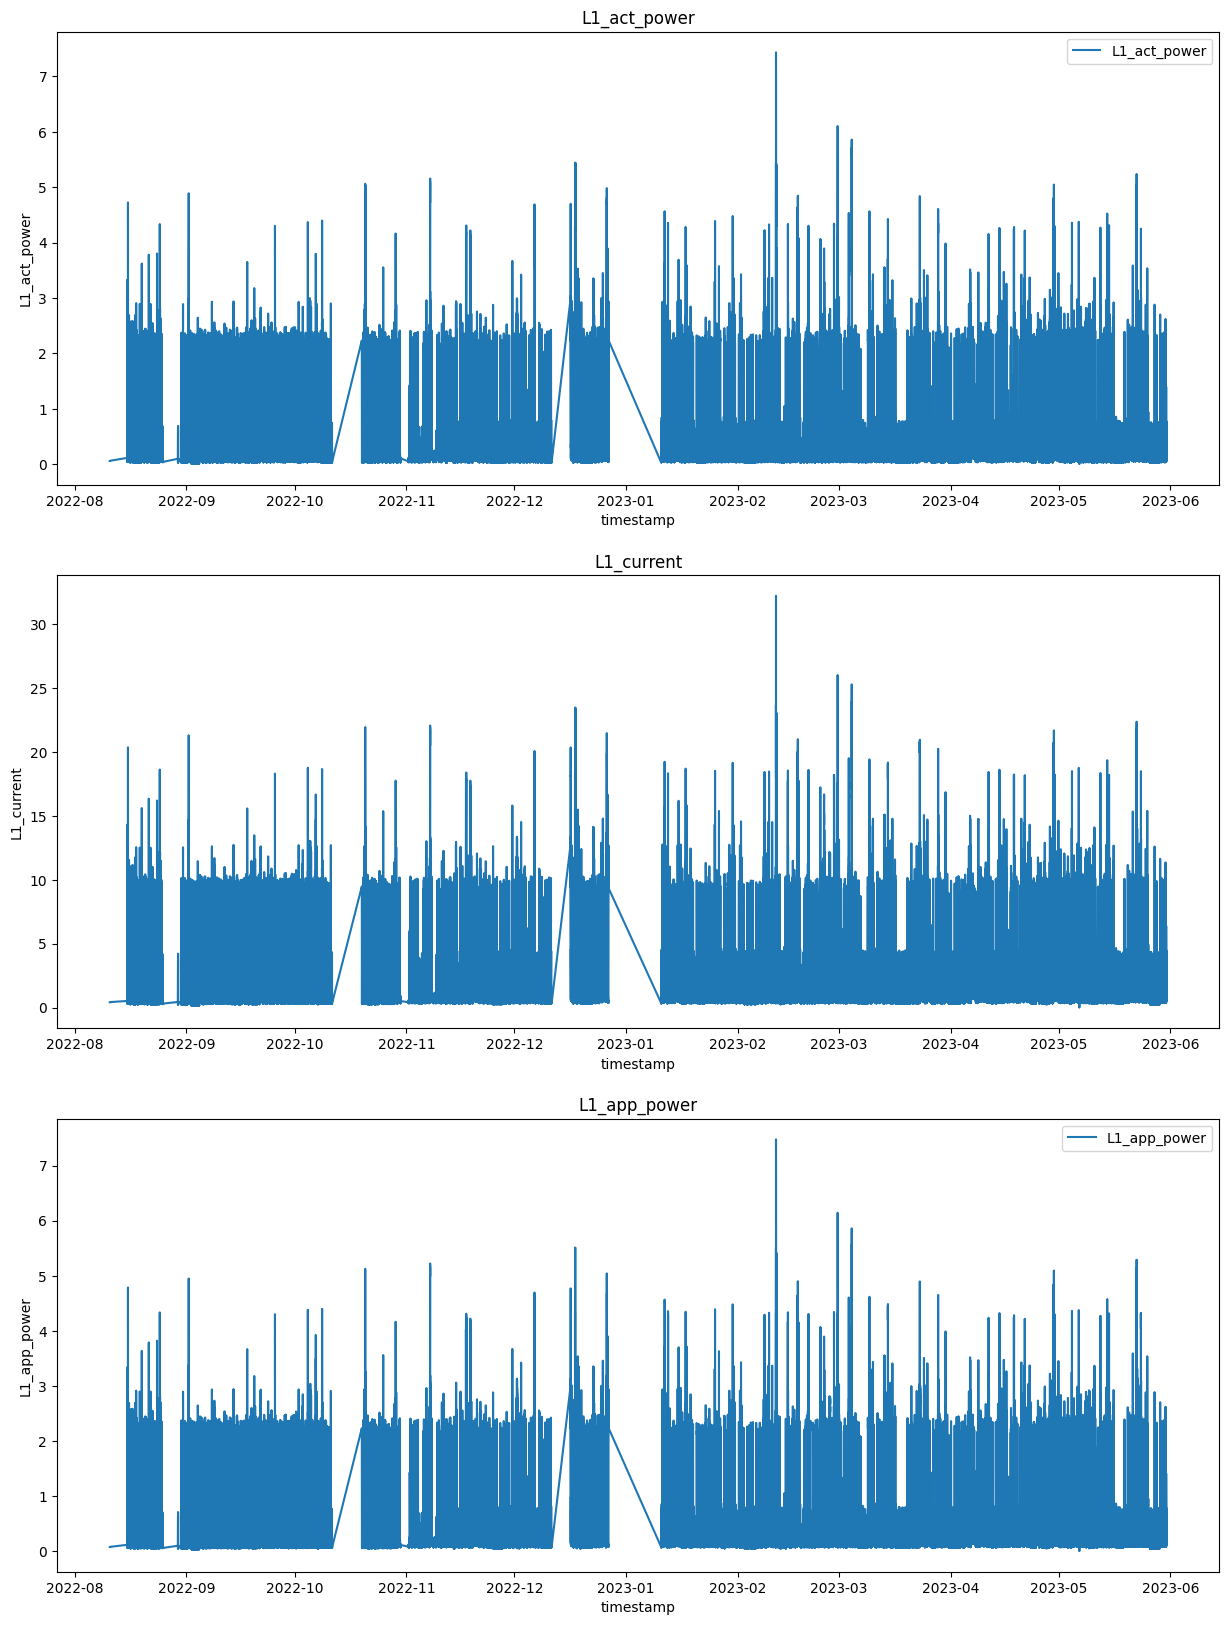

In [ ]:
fig, axes = plt.subplots(3, 1, figsize=(15, 20))

sns.lineplot(data=df, x='timestamp', y='L1_act_power', label='L1_act_power', ax=axes[0])
axes[0].set_title('L1_act_power')
sns.lineplot(data=df, x='timestamp', y='L1_current', ax=axes[1])
axes[1].set_title('L1_current')
sns.lineplot(data=df, x='timestamp', y='L1_app_power', label='L1_app_power', ax=axes[2])
axes[2].set_title('L1_app_power');

We have missing values from around **2022-10-12 until 2022-10-20** for **all devices**

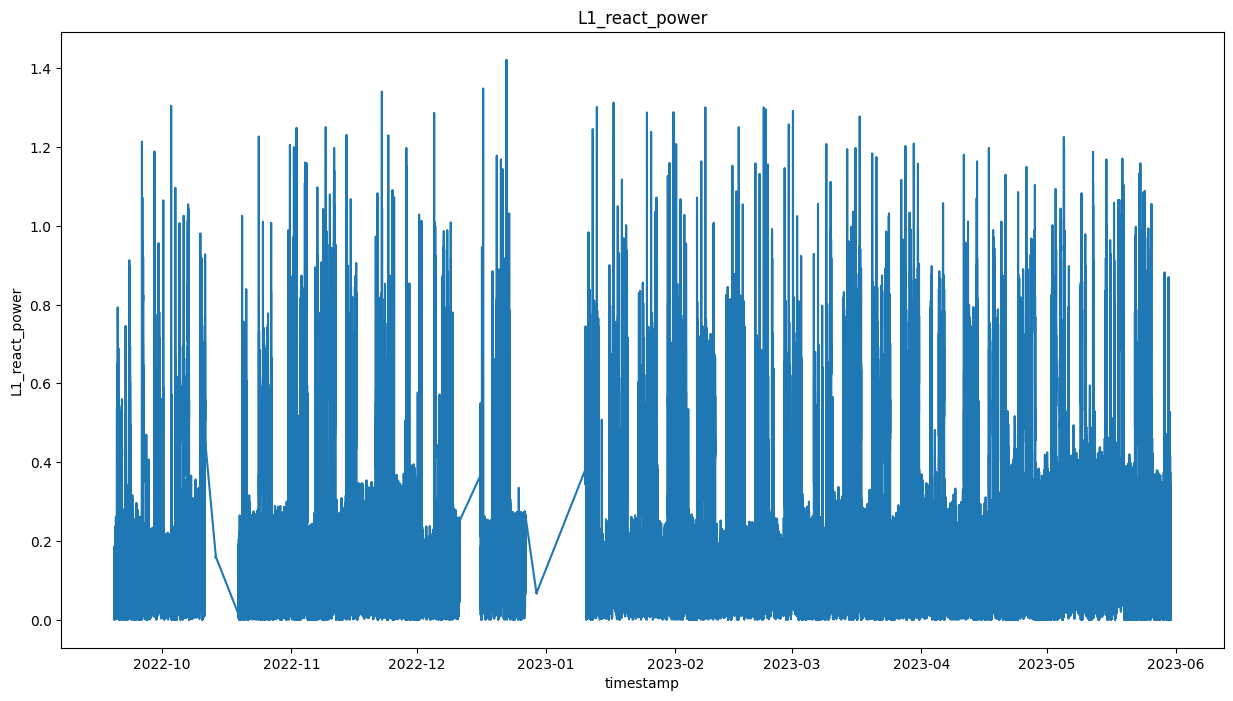

In [ ]:
sns.lineplot(data=df, x='timestamp', y='L1_react_power')
plt.title('L1_react_power');

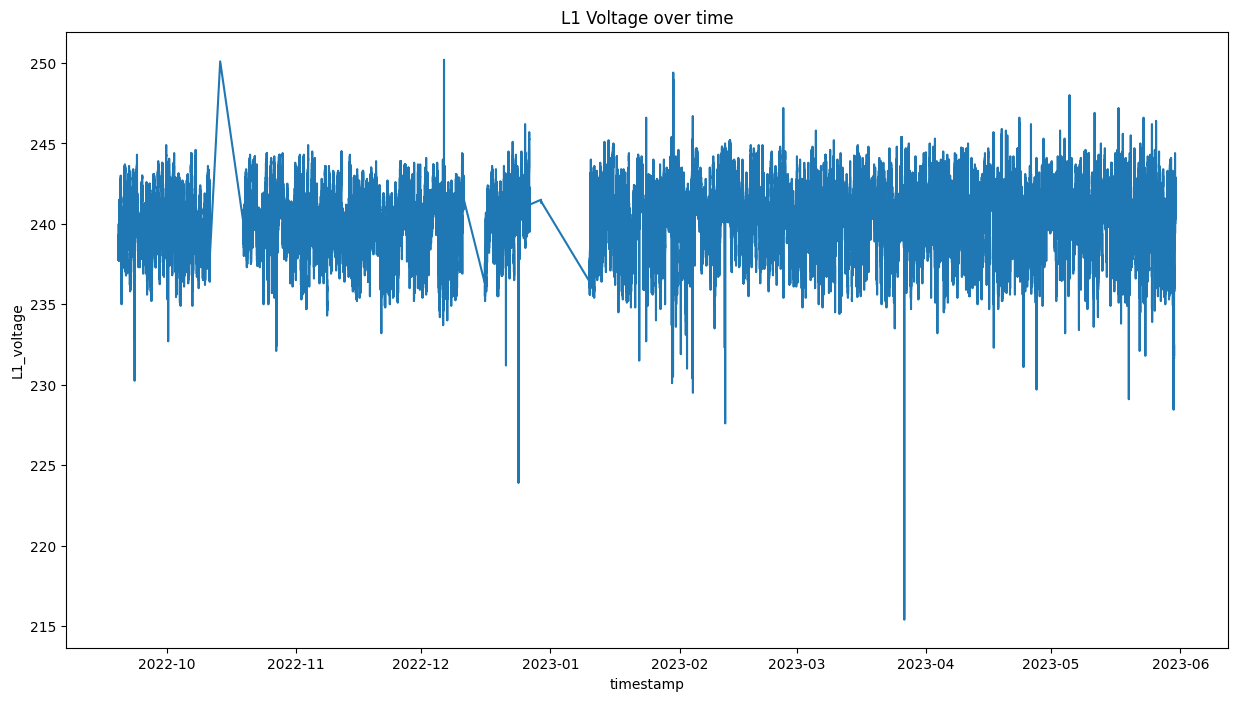

In [ ]:
sns.lineplot(data=df, x='timestamp', y='L1_voltage')
plt.title('L1 Voltage over time');

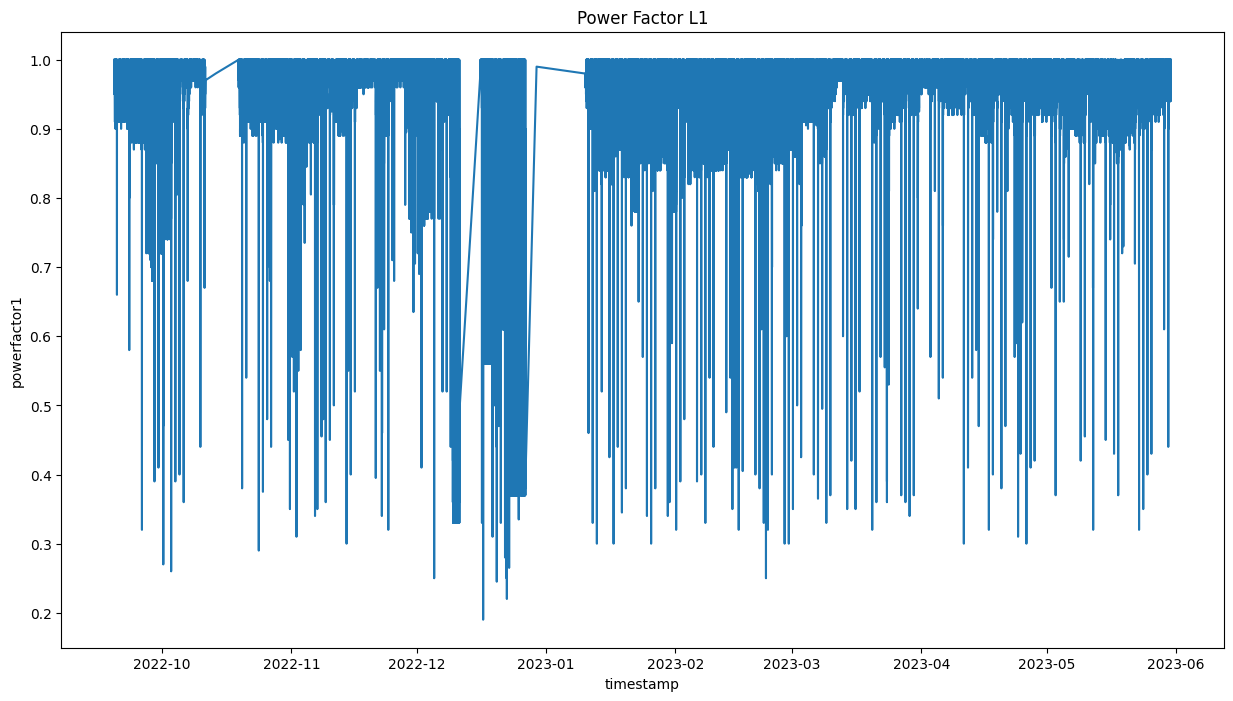

In [ ]:
sns.lineplot(data=df, x='timestamp', y='powerfactor1')
plt.title('Power Factor L1');

### L2 Phase Analysis

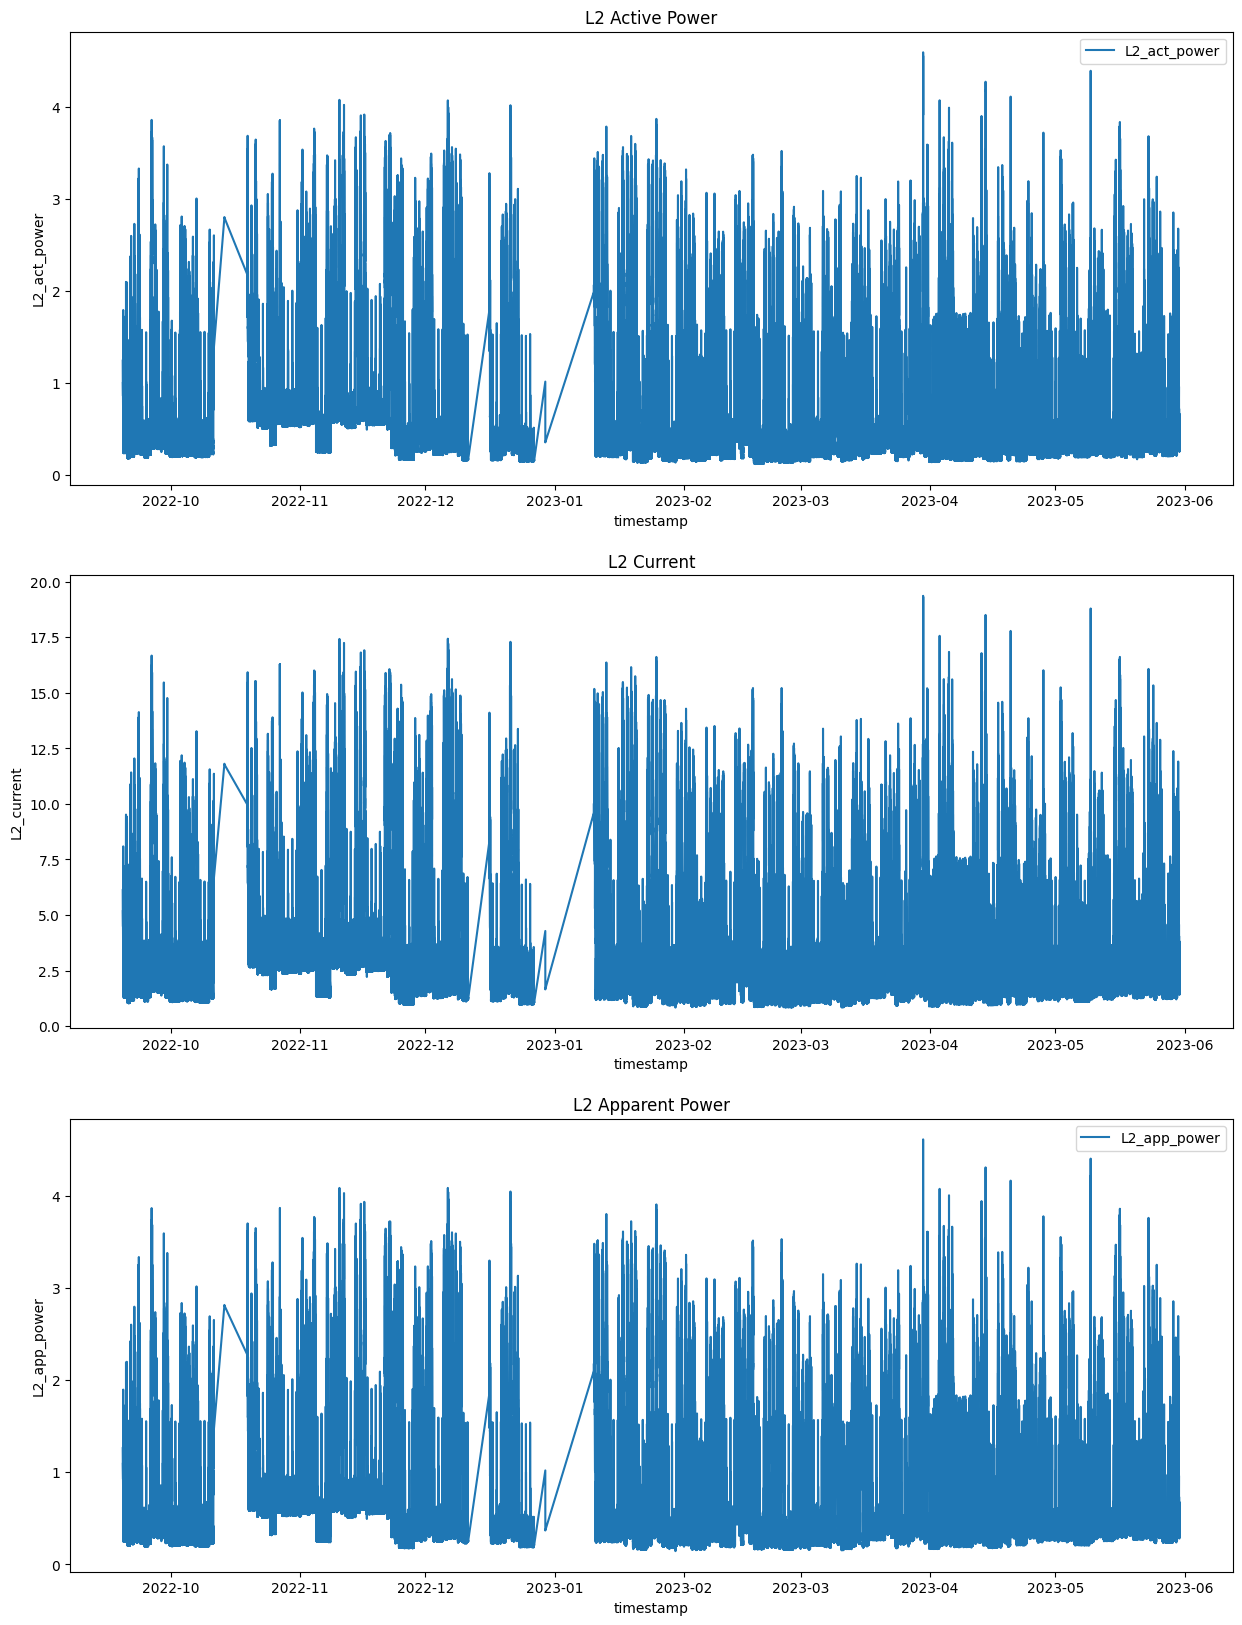

In [ ]:
if df.columns.str.contains('L2').any():
    fig, axes = plt.subplots(3, 1, figsize=(15, 20))
    sns.lineplot(data=df, x='timestamp', y='L2_act_power', label='L2_act_power', ax=axes[0])
    axes[0].set_title('L2 Active Power')
    sns.lineplot(data=df, x='timestamp', y='L2_current', ax=axes[1])
    axes[1].set_title('L2 Current')
    sns.lineplot(data=df, x='timestamp', y='L2_app_power', label='L2_app_power', ax=axes[2])
    axes[2].set_title('L2 Apparent Power');
else:
    print('L2-phase columns for this device are uninformative (std = 0)')

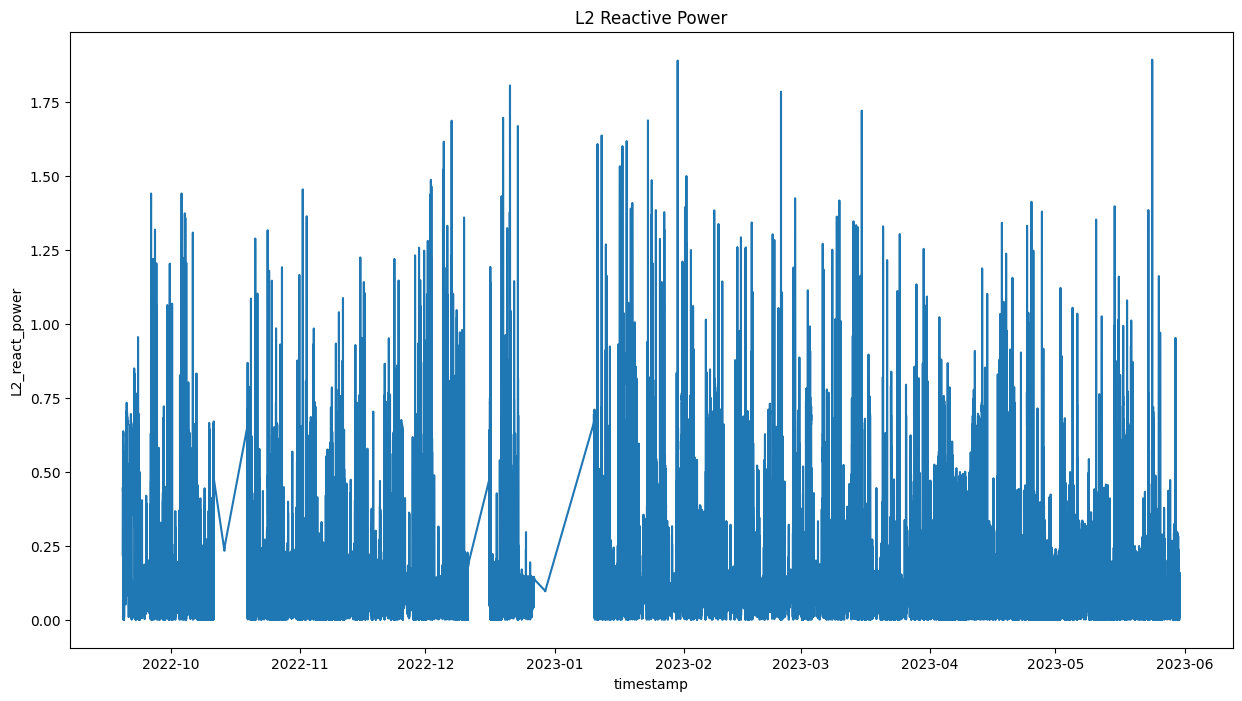

In [ ]:
if df.columns.str.contains('L2').any():
    sns.lineplot(data=df, x='timestamp', y='L2_react_power')
    plt.title('L2 Reactive Power');
else:
    print('L2-phase columns for this device are uninformative (std = 0)')

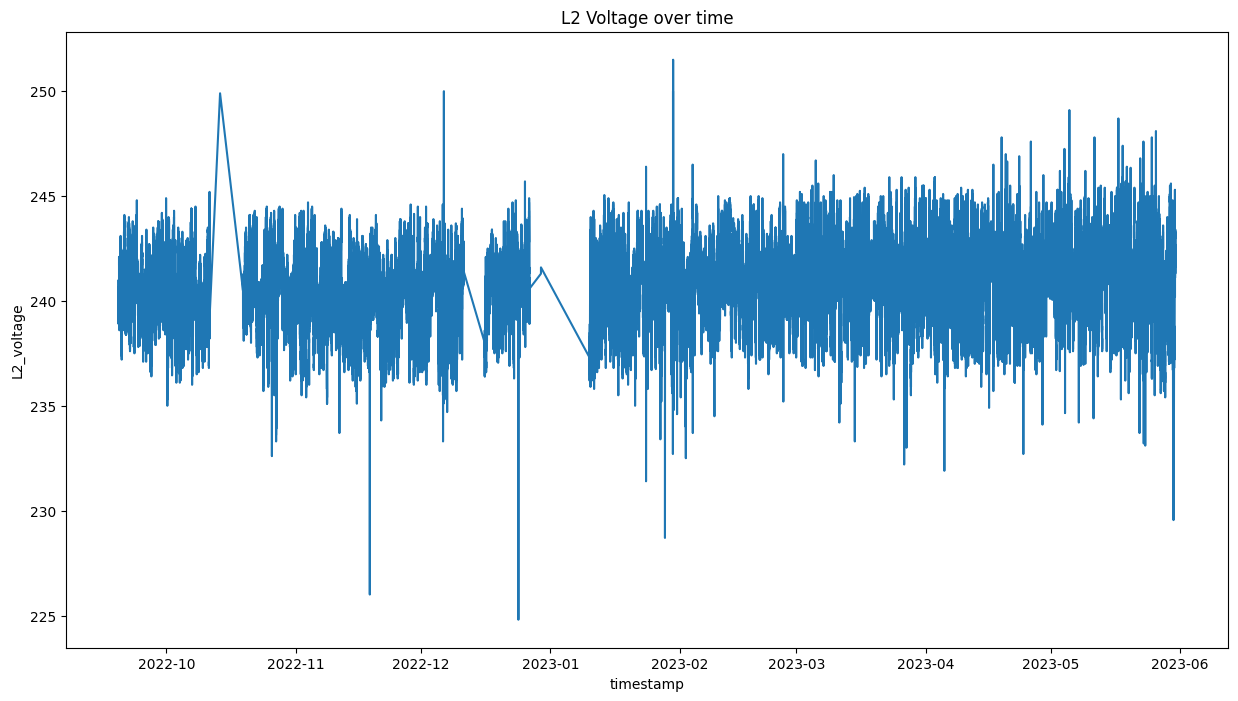

In [ ]:
if df.columns.str.contains('L2').any():
    sns.lineplot(data=df, x='timestamp', y='L2_voltage')
    plt.title('L2 Voltage over time');
else:
    print('L2-phase columns for this device are uninformative (std = 0)')

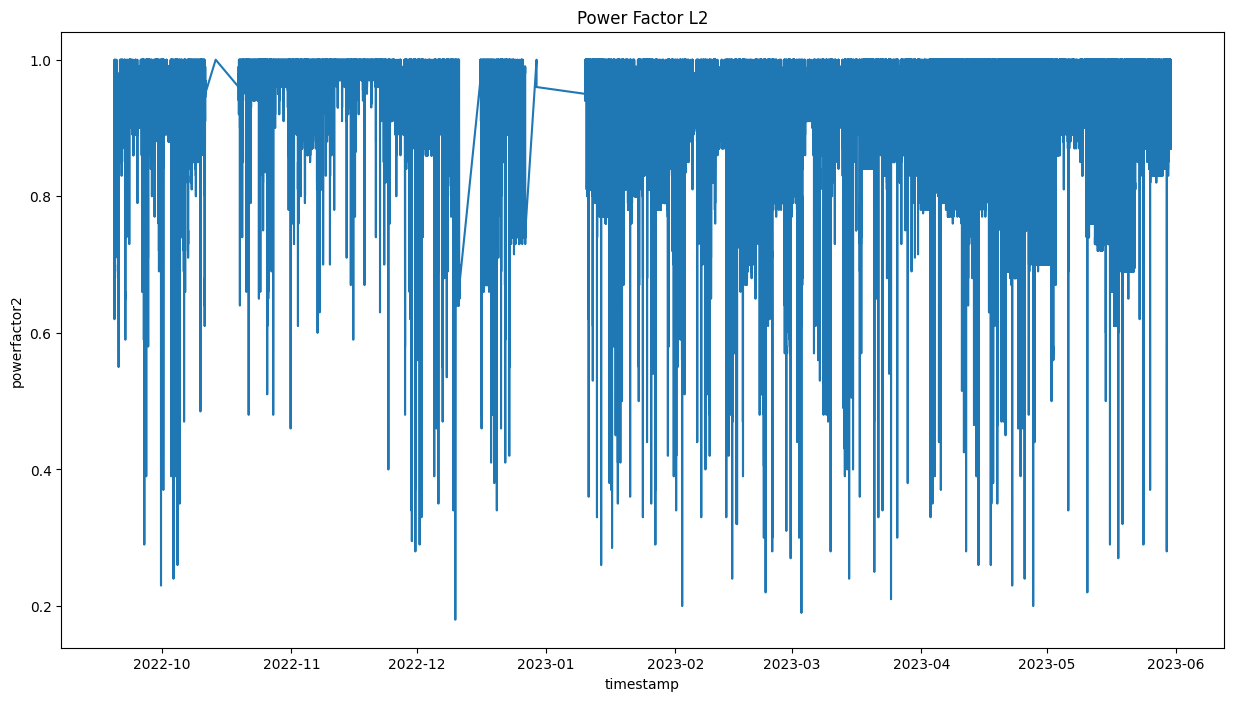

In [ ]:
# Plot powerfactor2 if it exists in the dataframe (wasn't dropped due to 0 std)
if 'powerfactor2' in df.columns:
    sns.lineplot(data=df, x='timestamp', y='powerfactor2')
    plt.title('Power Factor L2');

### L3 Phase Analysis

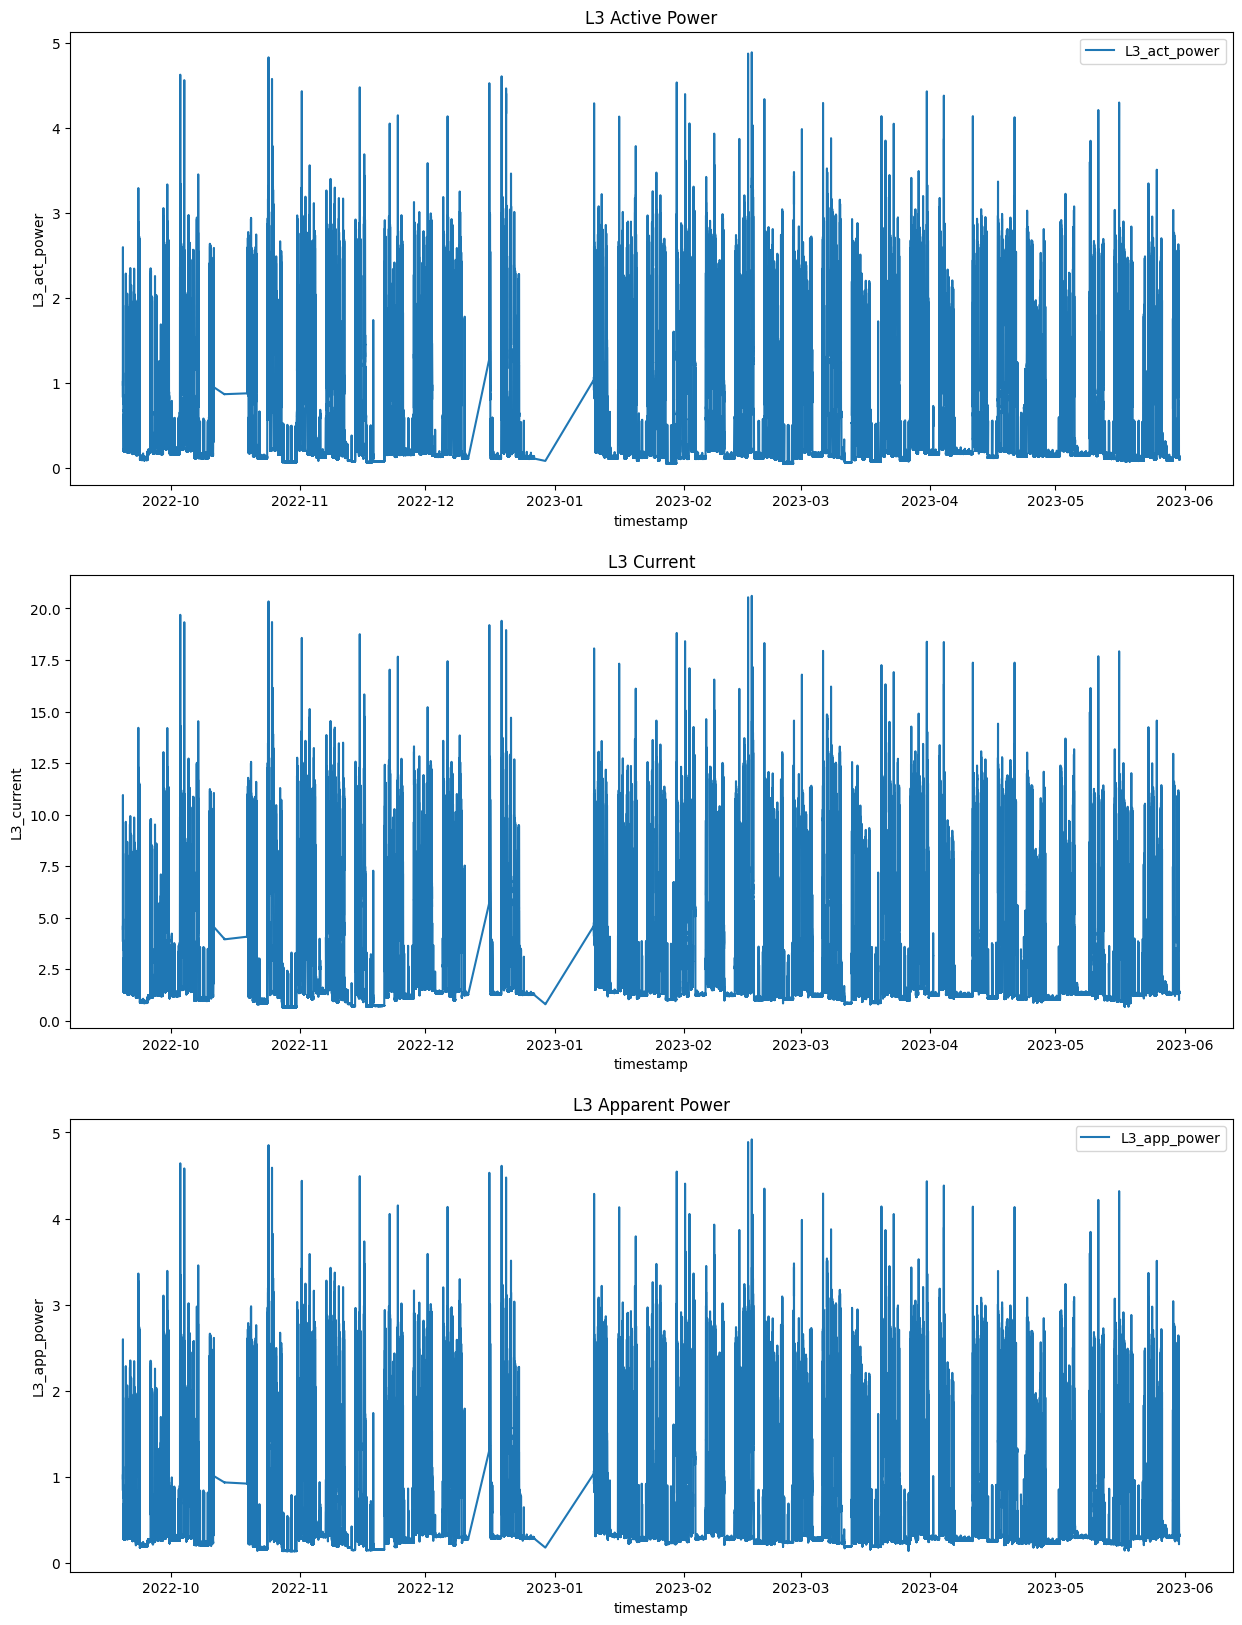

In [ ]:
if df.columns.str.contains('L3').any():
    fig, axes = plt.subplots(3, 1, figsize=(15, 20))

    sns.lineplot(data=df, x='timestamp', y='L3_act_power', label='L3_act_power', ax=axes[0])
    axes[0].set_title('L3 Active Power')
    sns.lineplot(data=df, x='timestamp', y='L3_current', ax=axes[1])
    axes[1].set_title('L3 Current')
    sns.lineplot(data=df, x='timestamp', y='L3_app_power', label='L3_app_power', ax=axes[2])
    axes[2].set_title('L3 Apparent Power');
else:
    print('L3-phase columns for this device are uninformative (std = 0)')

In [ ]:
if df.columns.str.contains('L3').any():    
    sns.lineplot(data=df, x='timestamp', y='L3_react_power')
    plt.title('L3 Reactive Power');
else:
    print('L3-phase columns for this device are uninformative (std = 0)')

L3-phase columns for this device are uninformative (std = 0)


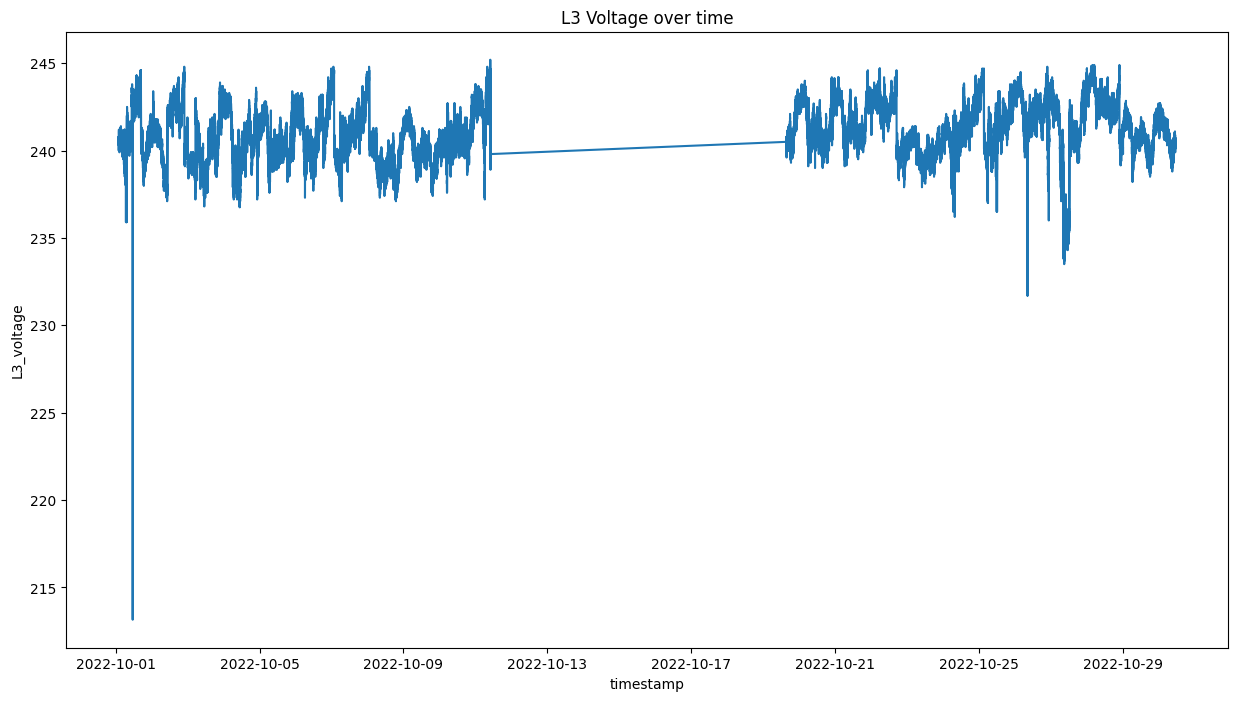

In [ ]:
if df.columns.str.contains('L3').any():    
    sns.lineplot(data=df, x='timestamp', y='L3_voltage')
    plt.title('L3 Voltage over time');
else:
    print('L3-phase columns for this device are uninformative (std = 0)')

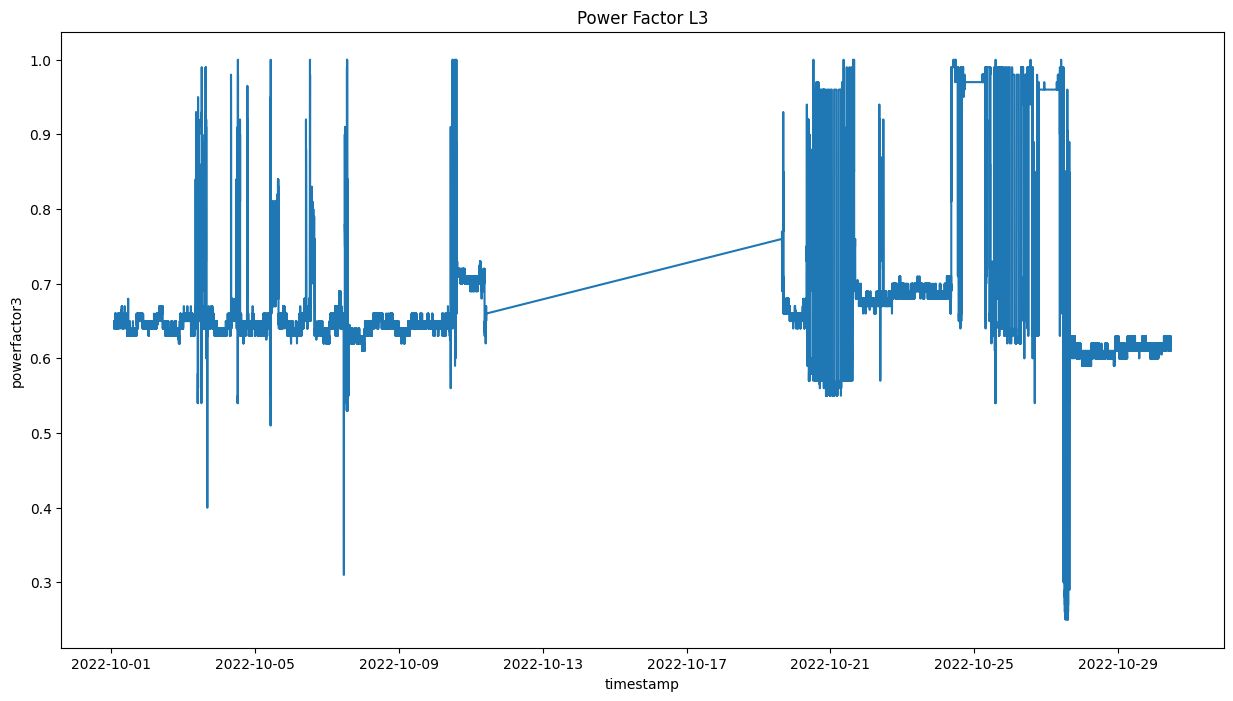

In [ ]:
# Plot powerfactor3 if it exists in the dataframe (wasn't dropped due to 0 std)
if 'powerfactor3' in df.columns:
    sns.lineplot(data=df, x='timestamp', y='powerfactor3')
    plt.title('Power Factor L3');

### Grid Frequency Analysis

Text(0.5, 1.0, 'Grid Frequency')

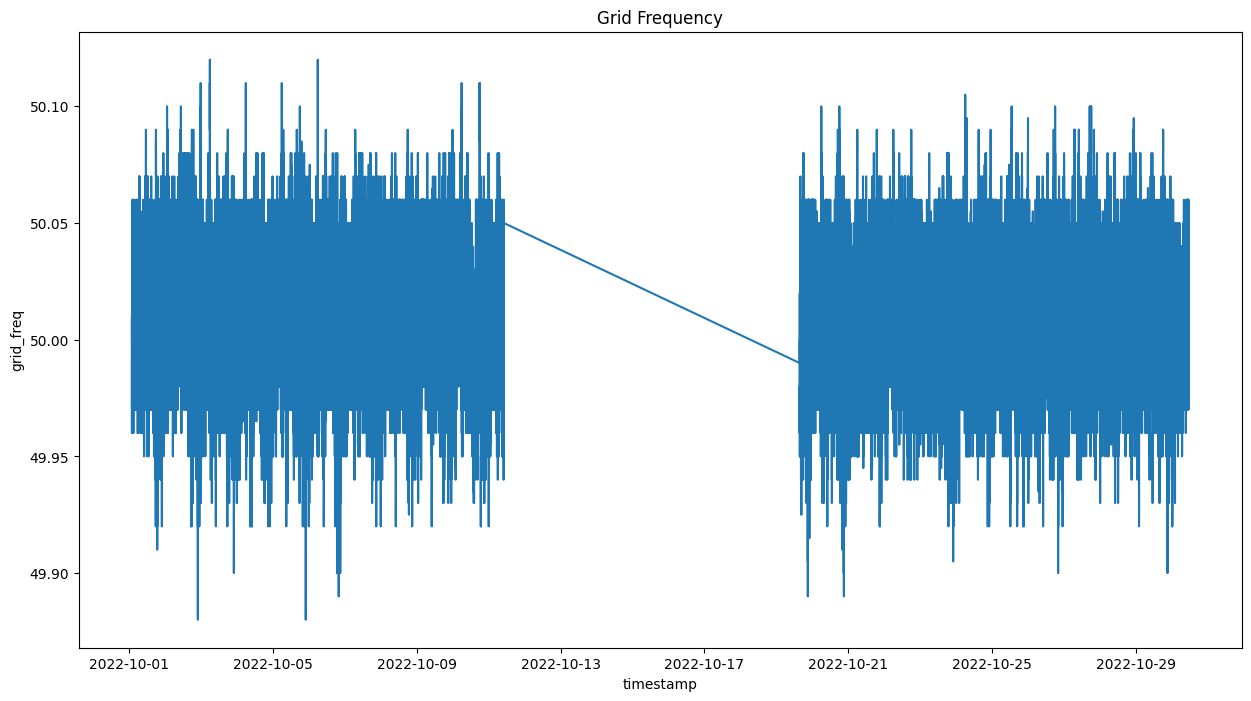

In [ ]:
sns.lineplot(data=df, x='timestamp', y='grid_freq')
plt.title('Grid Frequency')

## Cross-Phase Comparison (if available)

e:\DataScience\Mycroft\.venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


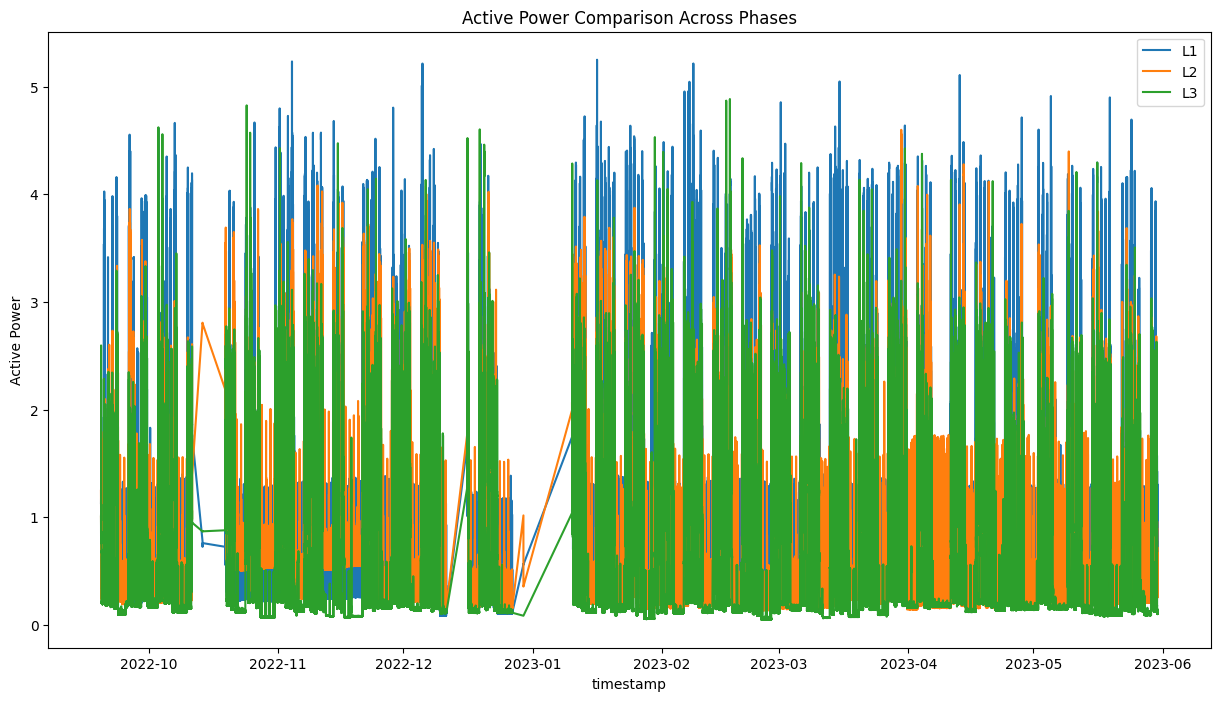

In [ ]:
sns.lineplot(data=df, x='timestamp', y='L1_act_power', label='L1')
if 'L2_act_power' in df.columns:
    sns.lineplot(data=df, x='timestamp', y='L2_act_power', label='L2')
else:
    print('L2-phase columns for this device were dropped (std = 0)')
if 'L3_act_power' in df.columns:
    sns.lineplot(data=df, x='timestamp', y='L3_act_power', label='L3')
else:
    print('L3-phase columns for this device were dropped (std = 0)')
    
plt.title('Active Power Comparison Across Phases')
plt.ylabel('Active Power')
plt.legend()
plt.show()

In [ ]:
sns.lineplot(data=df, x='timestamp', y='L1_current', label='L1')
if 'L2_current' in df.columns:
    sns.lineplot(data=df, x='timestamp', y='L2_current', label='L2')
else:
    print('L2-phase columns for this device were dropped (std = 0)')
if 'L3_current' in df.columns:
    sns.lineplot(data=df, x='timestamp', y='L3_current', label='L3')
else:
    print('L3-phase columns for this device were dropped (std = 0)')
    
plt.title('Current Comparison Across Phases')
plt.ylabel('Current')
plt.legend()
plt.show()

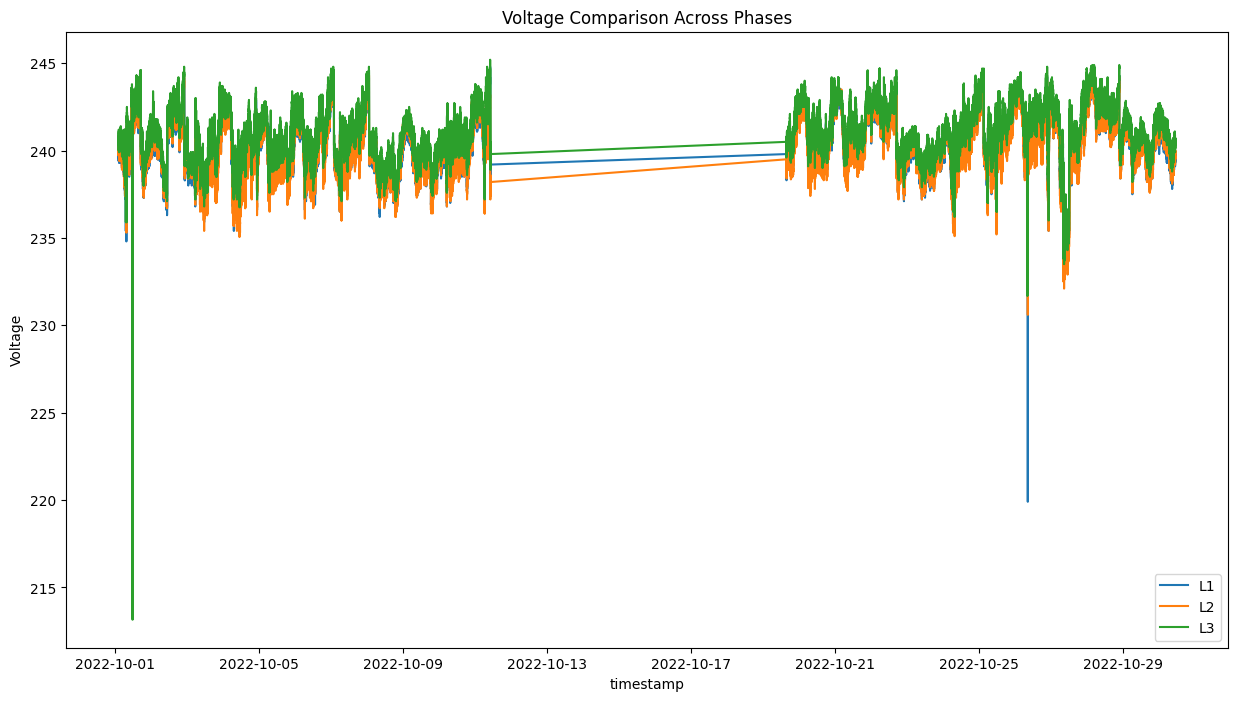

In [ ]:
sns.lineplot(data=df, x='timestamp', y='L1_voltage', label='L1')
if 'L2_voltage' in df.columns:
    sns.lineplot(data=df, x='timestamp', y='L2_voltage', label='L2')
else:
    print('L2-phase columns for this device were dropped (std = 0)')
if 'L3_voltage' in df.columns:
    sns.lineplot(data=df, x='timestamp', y='L3_voltage', label='L3')
else:
    print('L3-phase columns for this device were dropped (std = 0)')
    
plt.title('Voltage Comparison Across Phases')
plt.ylabel('Voltage')
plt.legend()
plt.show()

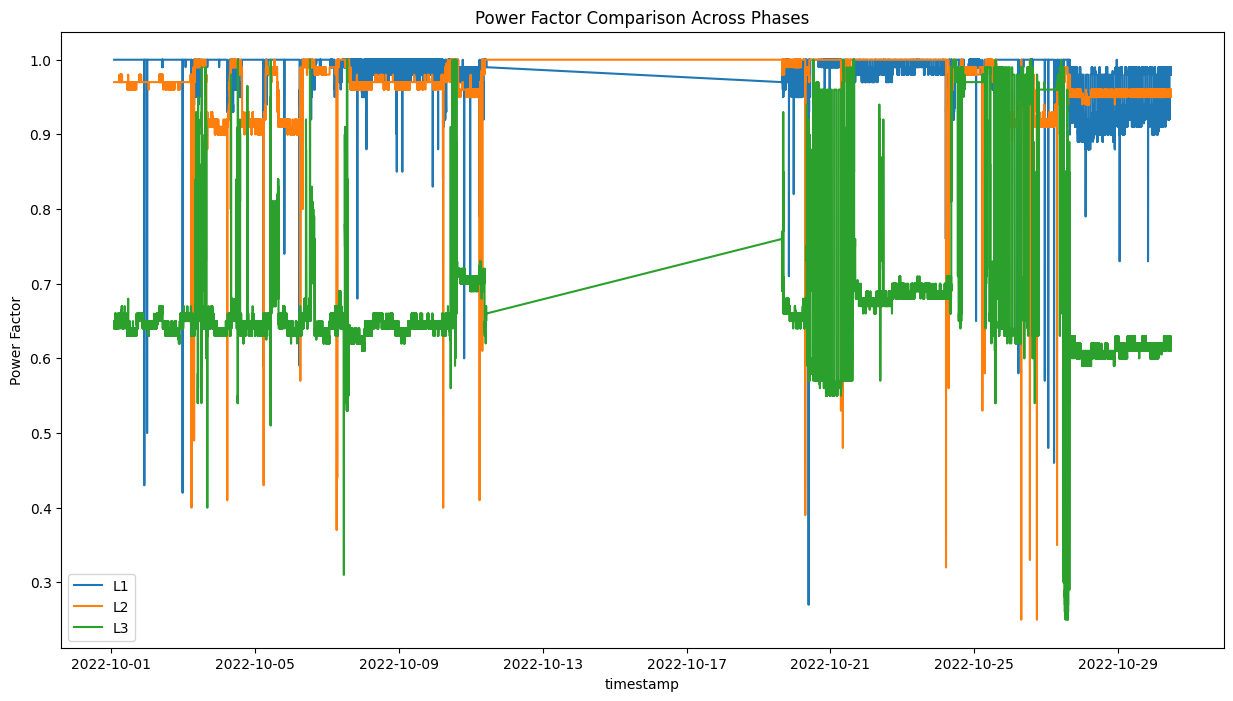

In [ ]:
sns.lineplot(data=df, x='timestamp', y='powerfactor1', label='L1')
if 'powerfactor2' in df.columns:
    sns.lineplot(data=df, x='timestamp', y='powerfactor2', label='L2')
else:
    print('L2-phase columns for this device were dropped (std = 0)')
if 'powerfactor3' in df.columns:
    sns.lineplot(data=df, x='timestamp', y='powerfactor3', label='L3')
else:
    print('L3-phase columns for this device were dropped (std = 0)')
    
plt.title('Power Factor Comparison Across Phases')
plt.ylabel('Power Factor')
plt.legend()
plt.show()

## Peaks detection

In [28]:
from scipy.signal import find_peaks

def normalize_zscore(y):
    return (y - np.mean(y)) / np.std(y)

def robust_zscore(y):
    y = np.array(y)
    med = np.median(y)
    mad = np.median(np.abs(y - med))
    return (y - med) / (mad if mad > 1e-6 else 1)

def plot_spikes_and_drops(x, y, title="Signal with Spikes and Drops", prominence=1.0, robust=False):

    if robust:
        y_pred_norm = robust_zscore(y)
    else:
        y_pred_norm = normalize_zscore(y)
    peaks, _ = find_peaks(y_pred_norm, prominence=prominence)  # use normalized threshold
    drops, _ = find_peaks(-y_pred_norm, prominence=prominence)  # use normalized threshold

    plt.figure(figsize=(15, 9))
    plt.plot(x, y, label="Signal", color="gray")
    plt.plot(x[peaks], y[peaks], "r^", label="Spikes")
    plt.plot(x[drops], y[drops], "bv", label="Drops")
    plt.title(title)
    plt.xlabel("Time")
    plt.ylabel("Value")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

C:\Users\HP\AppData\Local\Temp\ipykernel_2472\555613157.py:30: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()
e:\DataScience\Mycroft\.venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


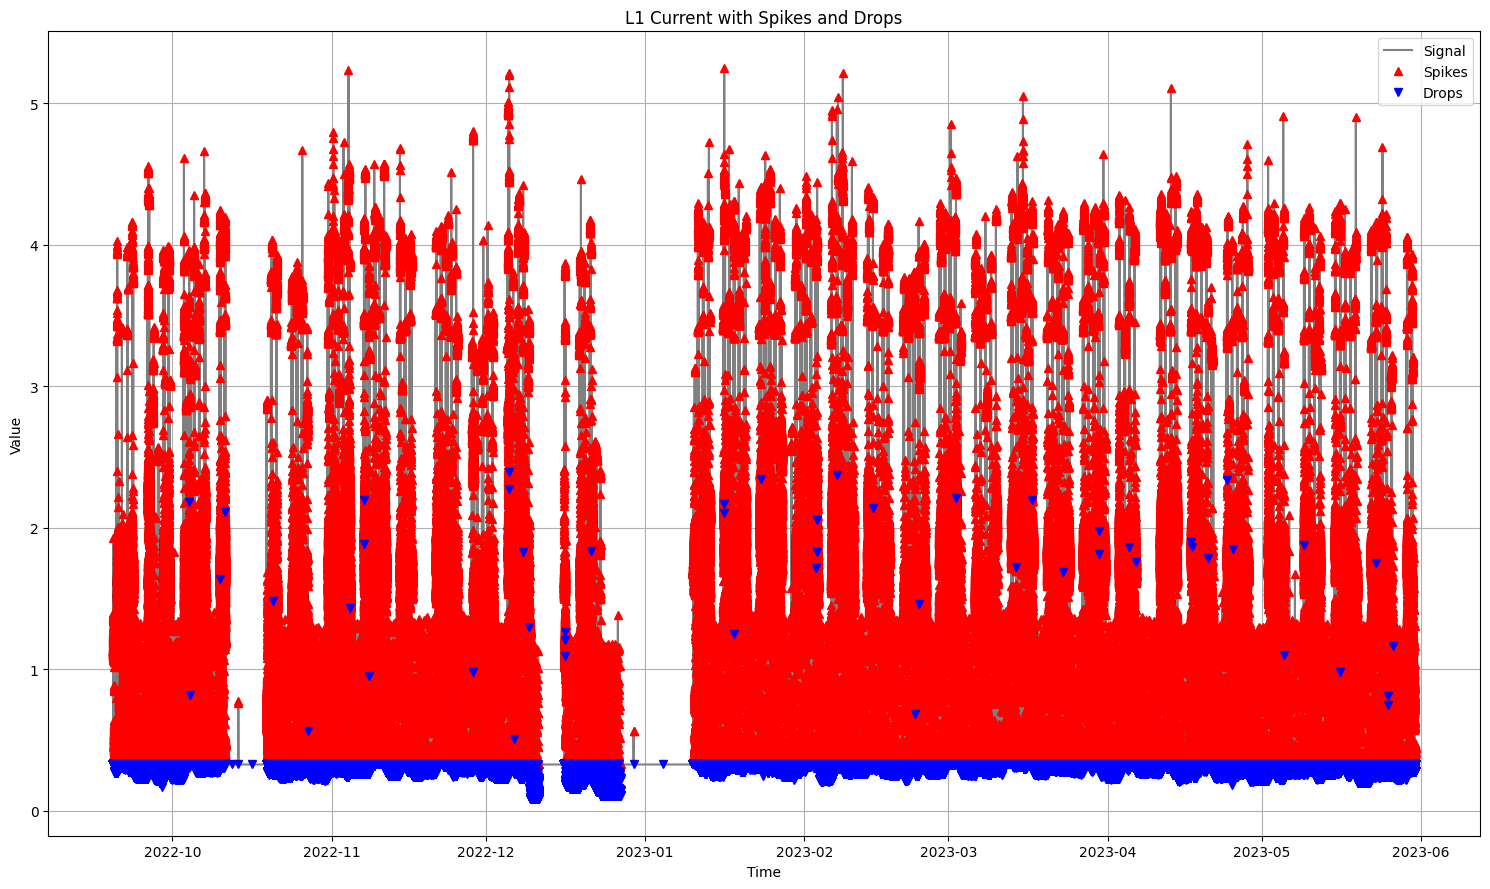

In [ ]:
plot_spikes_and_drops(df['timestamp'],
                      df['L1_act_power'].fillna(df['L1_act_power'].median()), 
                      title="L1 Current with Spikes and Drops",
                      prominence=2.0, robust=True)

Doesn't work well with 1-sec granularity (or with missing values)

In [ ]:
if 'L2_act_power' in df.columns:
    plot_spikes_and_drops(df['timestamp'],
                          df['L2_act_power'], 
                          title="L2 Current with Spikes and Drops",
                          prominence=1)
else:
    print('L2-phase columns for this device were dropped (std = 0)')

L2-phase columns for this device were dropped (std = 0)


In [ ]:
if 'L3_act_power' in df.columns:
    plot_spikes_and_drops(df['timestamp'],
                        df['L3_act_power'], 
                        title="L3 Current with Spikes and Drops",
                        prominence=1)
else:
    print('L3-phase columns for this device were dropped (std = 0)')

L3-phase columns for this device were dropped (std = 0)


## Hourly Analysis

In [24]:
# Group by hour
df_hour = df.groupby(df['timestamp'].dt.floor('h'))

# Create index for full time range
full_range = pd.DataFrame(
    index=pd.date_range(
        pd.DatetimeIndex(df_hour.indices.keys()).min(),
        pd.DatetimeIndex(df_hour.indices.keys()).max(), 
        freq='h'
    )
)

# Join with hourly aggregated data for each phase
l1_act_pow_hour_endog = full_range.join(df_hour['L1_act_power'].mean(), how='left').squeeze()
if 'L2_act_power' in df.columns:
    l2_act_pow_hour_endog = full_range.join(df_hour['L2_act_power'].mean(), how='left').squeeze()
if 'L3_act_power' in df.columns:
    l3_act_pow_hour_endog = full_range.join(df_hour['L3_act_power'].mean(), how='left').squeeze()

In [25]:
df_hour.count().describe()

,timestamp,L1_act_power,L1_app_power,L1_current,L1_react_power,L1_voltage,L2_act_power,L2_app_power,L2_current,L2_react_power,L2_voltage,L3_act_power,L3_app_power,L3_current,L3_react_power,L3_voltage,grid_freq,powerfactor1,powerfactor2,powerfactor3
count,6080.000000,6080.000000,6080.000000,6080.000000,6080.000000,6080.000000,6080.000000,6080.000000,6080.000000,6080.000000,6080.000000,6080.000000,6080.000000,6080.000000,6080.000000,6080.000000,6080.000000,6080.000000,6080.000000,6080.000000
mean,3599.694079,2073.422368,2073.422368,2073.422368,2073.422368,2073.422368,2073.422368,2073.422368,2073.422368,2073.422368,2073.422368,2073.422368,2073.422368,2073.422368,2073.422368,2073.422368,2073.422368,2073.422368,2073.422368,2073.422368
std,17.069770,753.889684,753.889684,753.889684,753.889684,753.889684,753.889684,753.889684,753.889684,753.889684,753.889684,753.889684,753.889684,753.889684,753.889684,753.889684,753.889684,753.889684,753.889684,753.889684
min,2525.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,3600.000000,2294.000000,2294.000000,2294.000000,2294.000000,2294.000000,2294.000000,2294.000000,2294.000000,2294.000000,2294.000000,2294.000000,2294.000000,2294.000000,2294.000000,2294.000000,2294.000000,2294.000000,2294.000000,2294.000000
50%,3600.000000,2361.000000,2361.000000,2361.000000,2361.000000,2361.000000,2361.000000,2361.000000,2361.000000,2361.000000,2361.000000,2361.000000,2361.000000,2361.000000,2361.000000,2361.000000,2361.000000,2361.000000,2361.000000,2361.000000
75%,3600.000000,2381.000000,2381.000000,2381.000000,2381.000000,2381.000000,2381.000000,2381.000000,2381.000000,2381.000000,2381.000000,2381.000000,2381.000000,2381.000000,2381.000000,2381.000000,2381.000000,2381.000000,2381.000000,2381.000000
max,3600.000000,2533.000000,2533.000000,2533.000000,2533.000000,2533.000000,2533.000000,2533.000000,2533.000000,2533.000000,2533.000000,2533.000000,2533.000000,2533.000000,2533.000000,2533.000000,2533.000000,2533.000000,2533.000000,2533.000000


In [26]:
def plot_hourly_data(series, title, color='blue'):
    # Choose a sensible default value for missing data
    fill_value = series.median() if not pd.isna(series.median()) else -100
    
     
    sns.lineplot(series.fillna(fill_value), label=f'hourly {title}', color=color)
    
    # Mark missing values
    plt.scatter(
        x=series[series.isna()].index,
        y=[series.min()-0.01]*series[series.isna()].shape[0],
        color='red',
        marker='x',
        label='missing'
    )
    
    plt.title(f"Hourly {title}")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

### Separate by phase

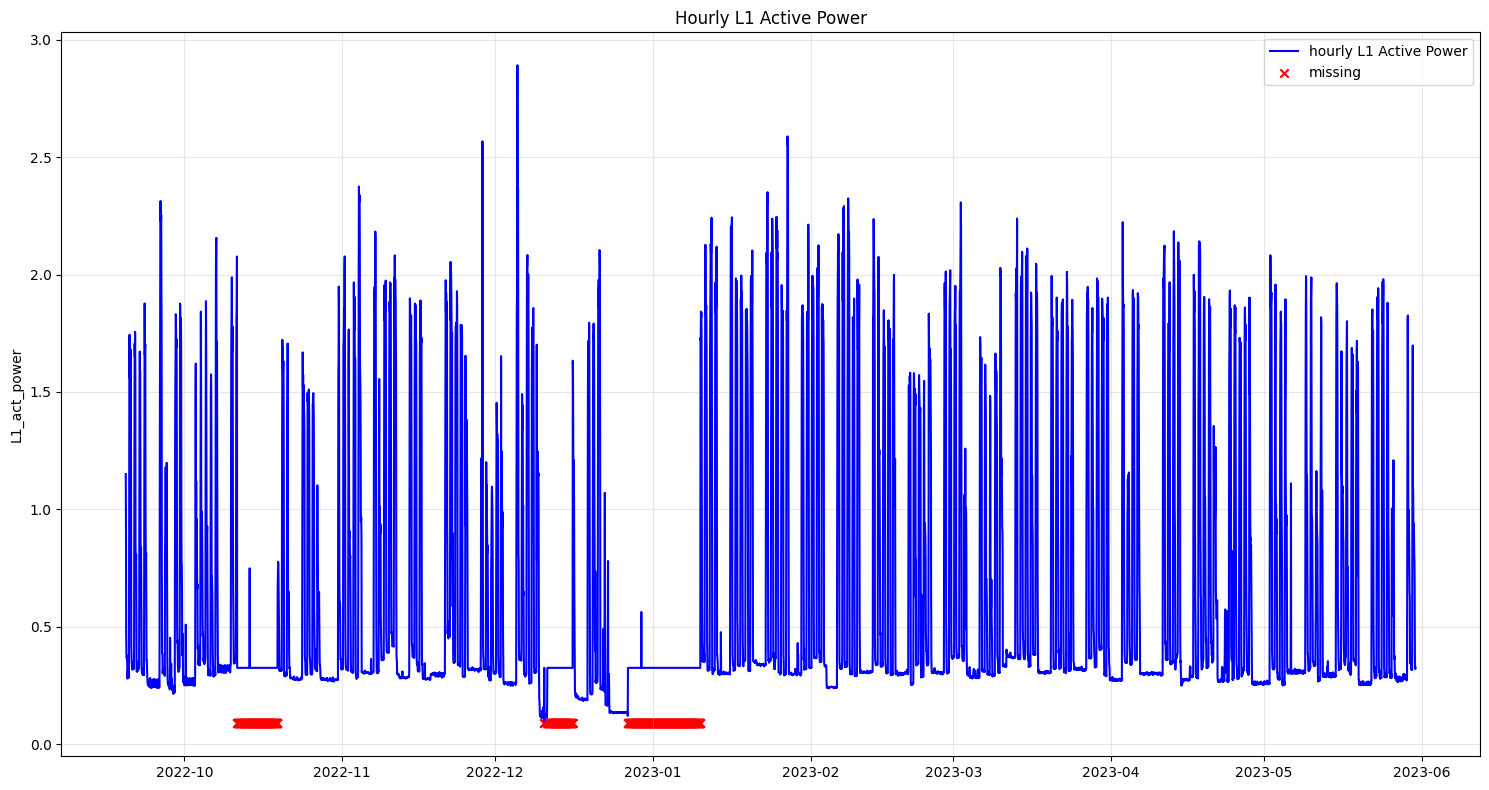

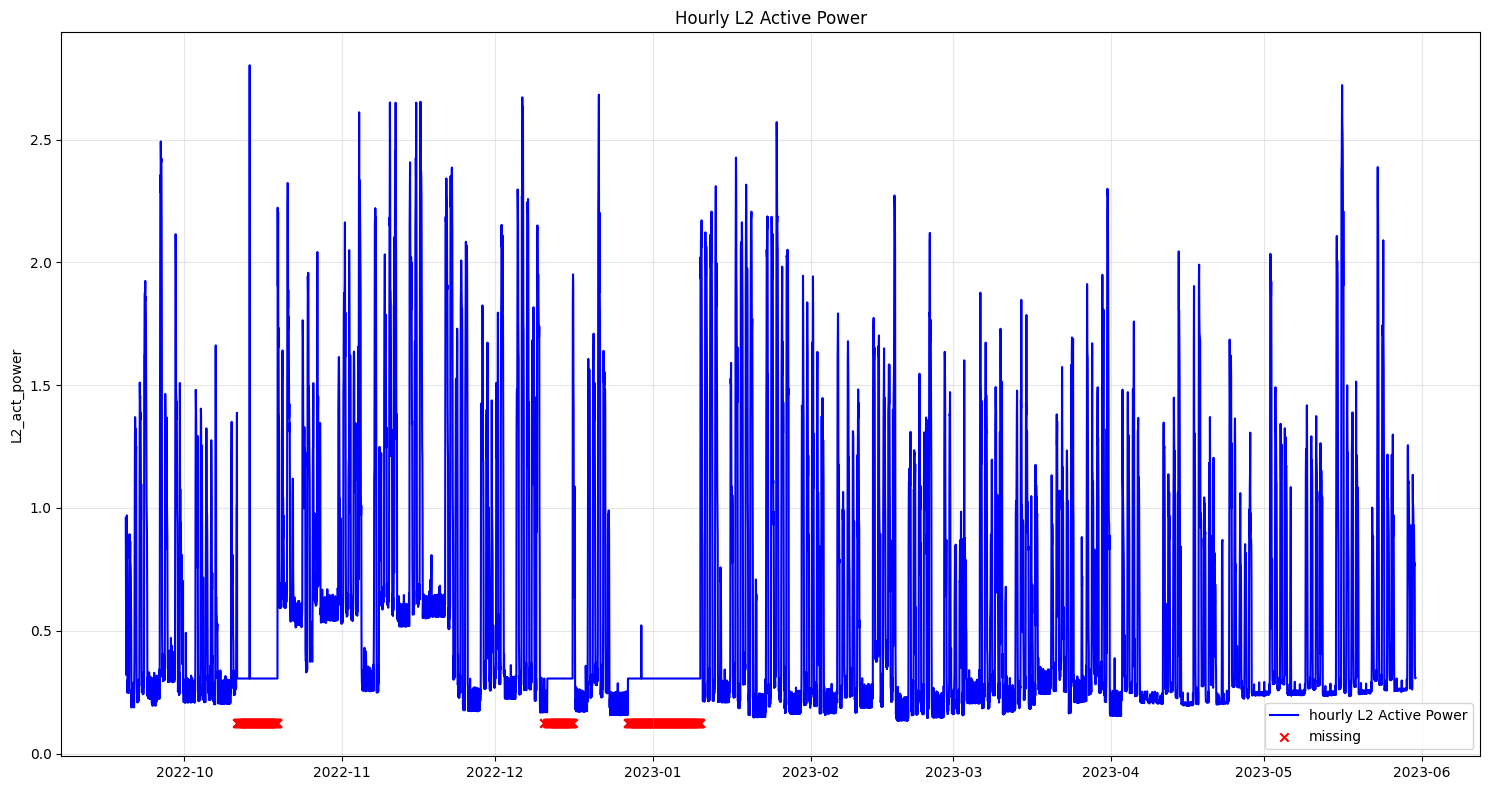

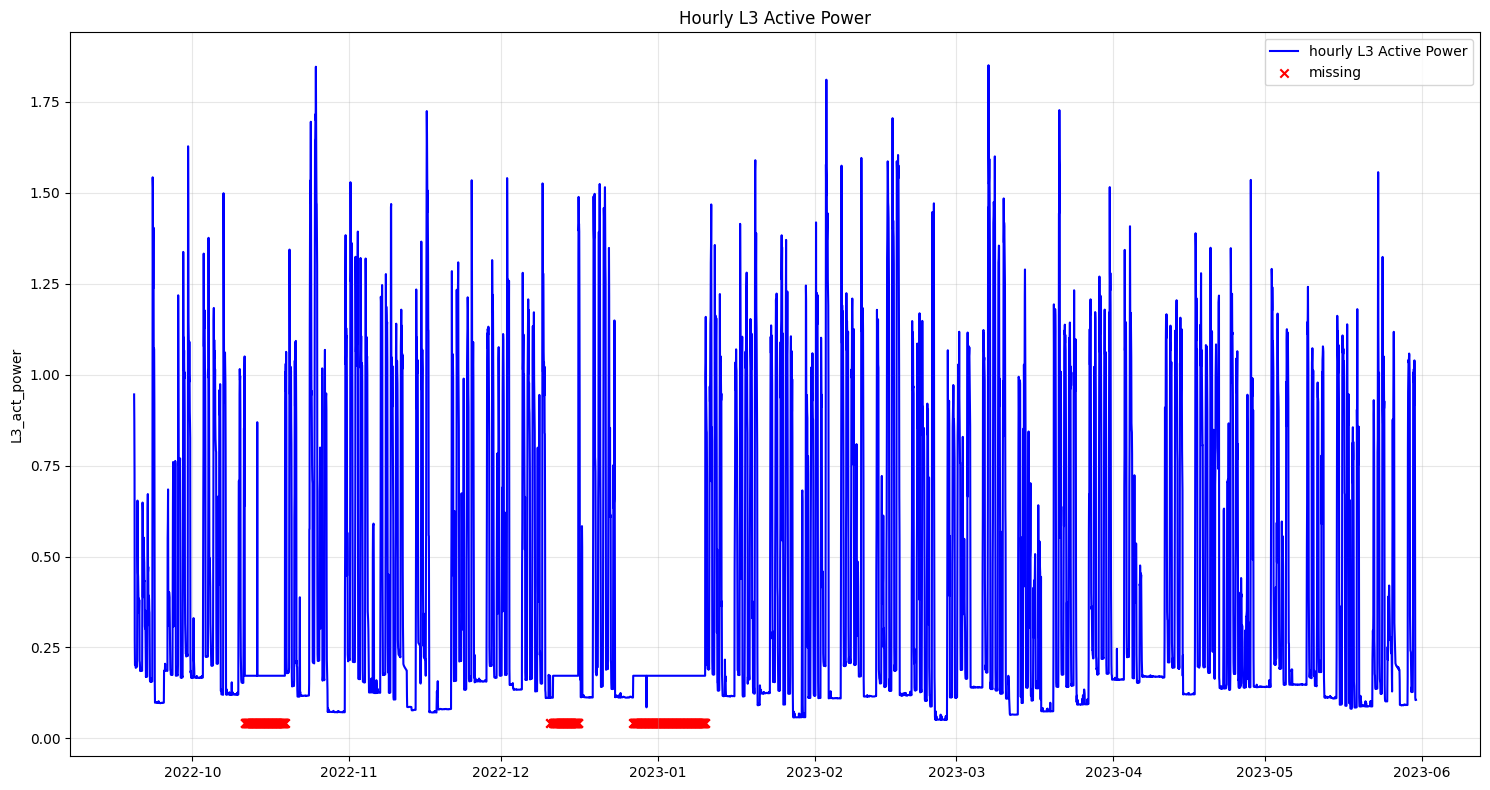

In [27]:
plot_hourly_data(l1_act_pow_hour_endog, 'L1 Active Power')
if 'L2_act_power' in df.columns:
    plot_hourly_data(l2_act_pow_hour_endog, 'L2 Active Power')
if 'L3_act_power' in df.columns:
    plot_hourly_data(l3_act_pow_hour_endog, 'L3 Active Power')

### Detect peaks

C:\Users\HP\AppData\Local\Temp\ipykernel_22216\555613157.py:23: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  plt.plot(x[peaks], y[peaks], "r^", label="Spikes")
C:\Users\HP\AppData\Local\Temp\ipykernel_22216\555613157.py:24: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  plt.plot(x[drops], y[drops], "bv", label="Drops")


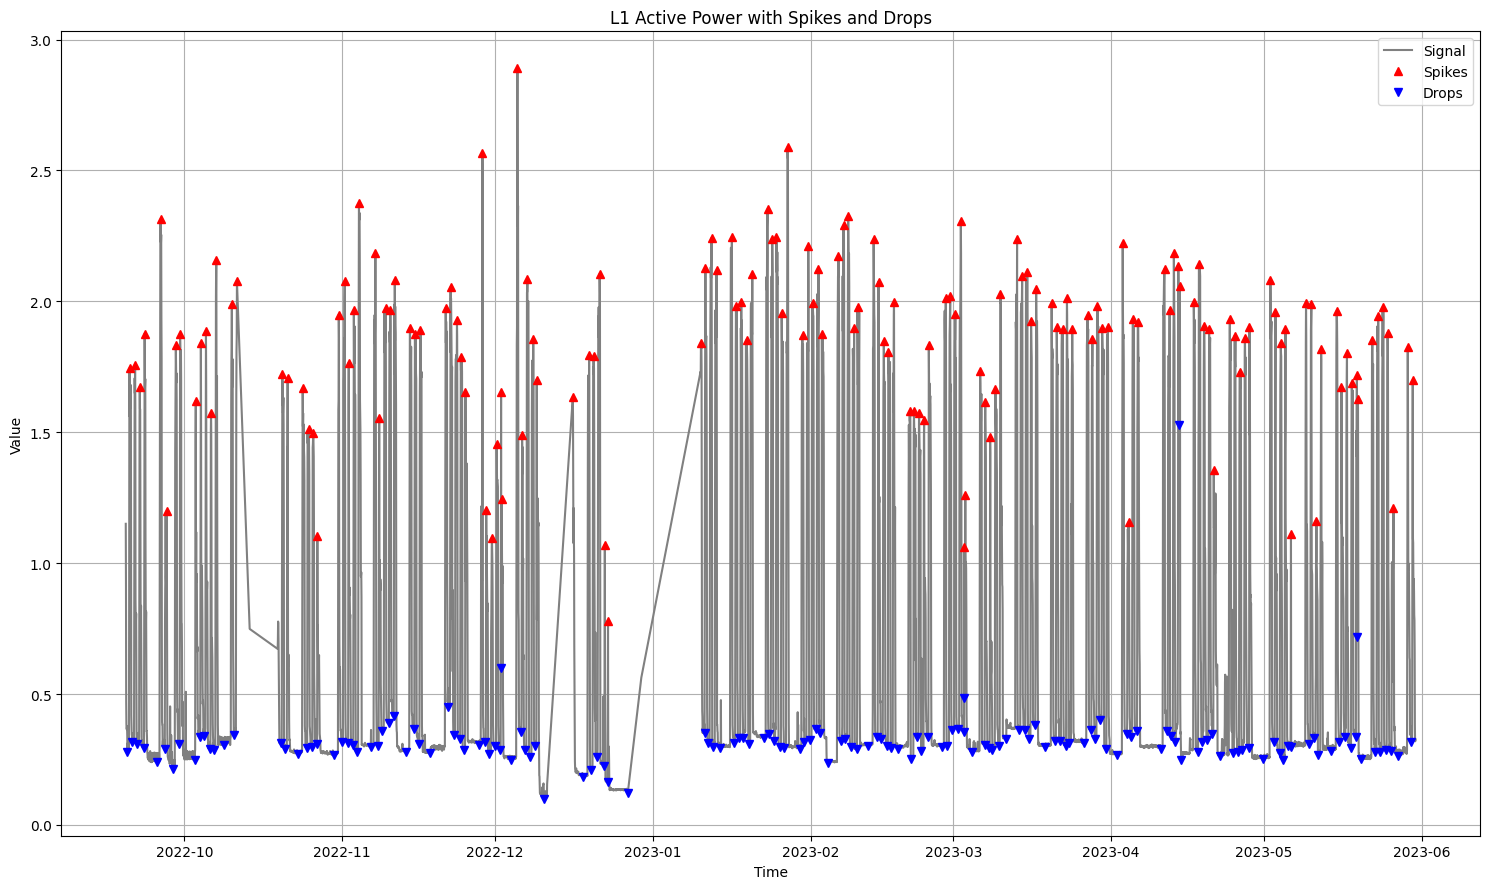

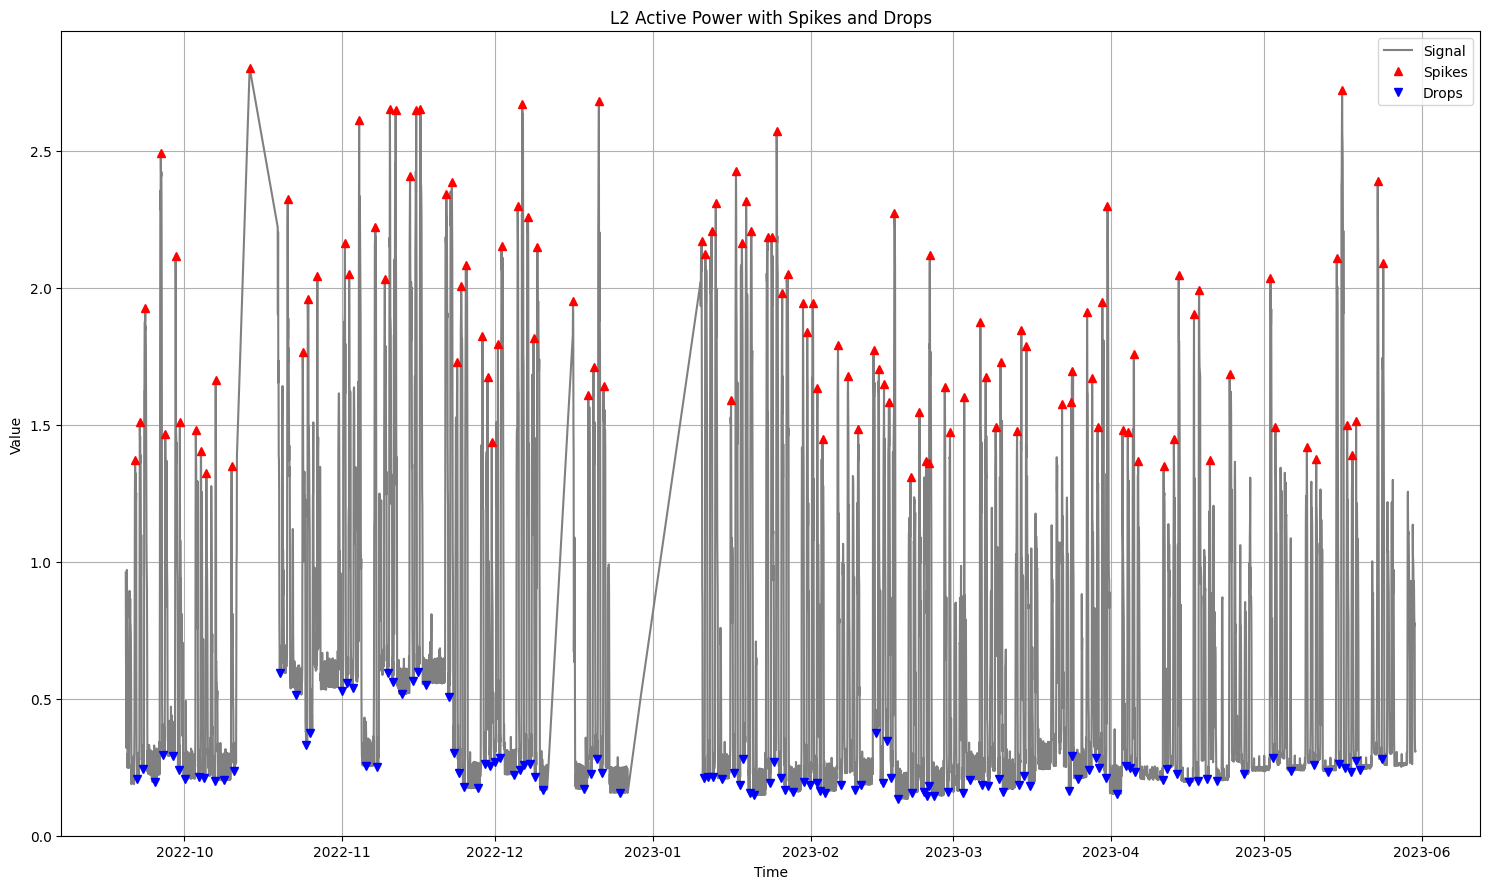

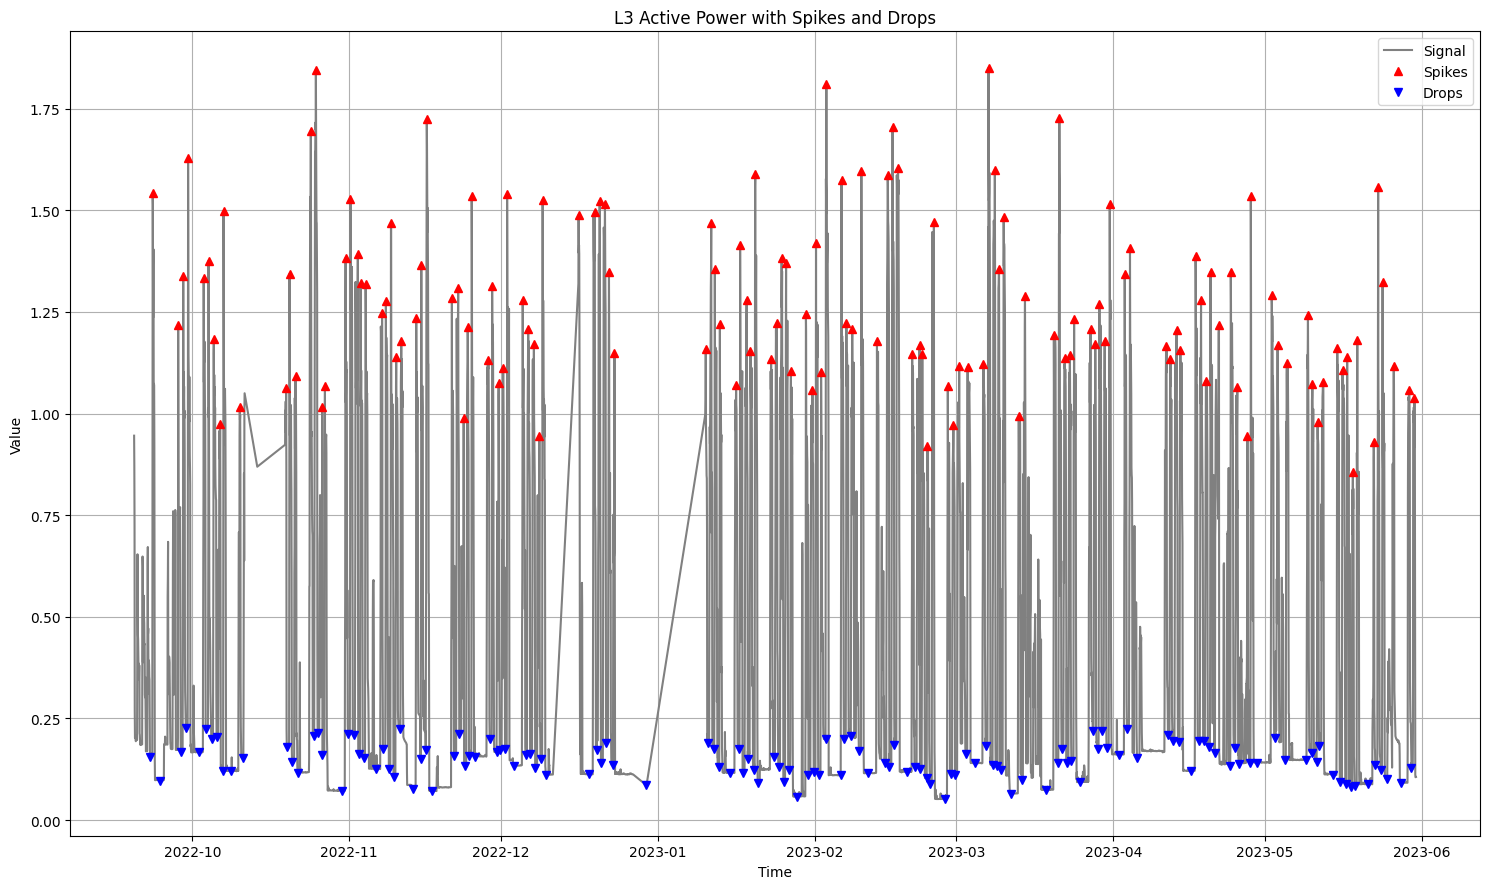

In [28]:
plot_spikes_and_drops(l1_act_pow_hour_endog.dropna().index,
                      l1_act_pow_hour_endog.dropna(), 
                      title="L1 Active Power with Spikes and Drops",
                      prominence=10.0, robust=True)
if 'L2_act_power' in df.columns:
    plot_spikes_and_drops(l2_act_pow_hour_endog.dropna().index,
                          l2_act_pow_hour_endog.dropna(), 
                          title="L2 Active Power with Spikes and Drops",
                          prominence=10.0, robust=True)
if 'L3_act_power' in df.columns:
    plot_spikes_and_drops(l3_act_pow_hour_endog.dropna().index,
                          l3_act_pow_hour_endog.dropna(), 
                          title="L3 Active Power with Spikes and Drops",
                          prominence=10.0, robust=True)

### Cross-phase

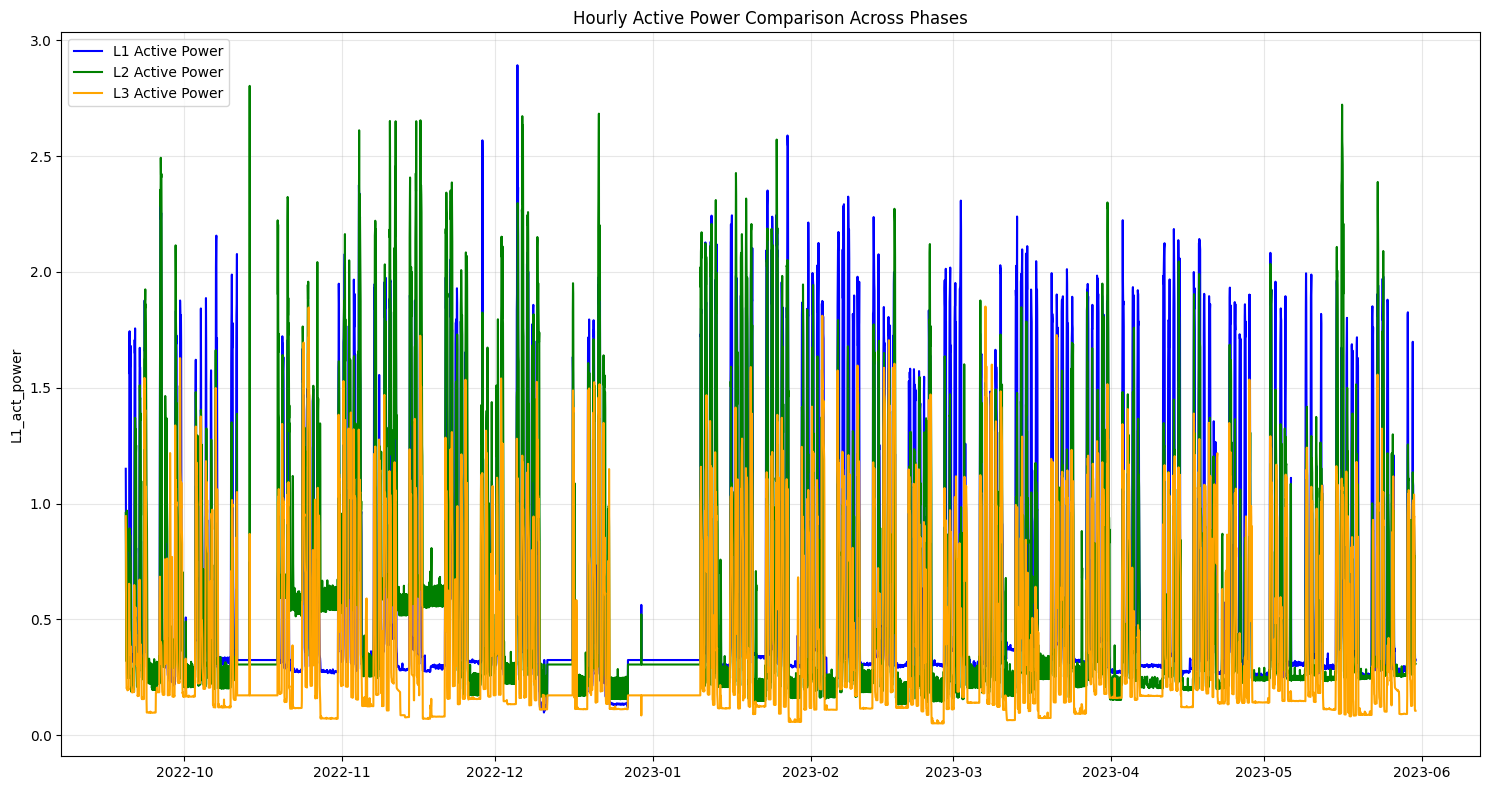

In [29]:
fill_value1 = l1_act_pow_hour_endog.median() if not pd.isna(l1_act_pow_hour_endog.median()) else -100
sns.lineplot(l1_act_pow_hour_endog.fillna(fill_value1), label='L1 Active Power', color='blue')
if 'L2_act_power' in df.columns:
    fill_value2 = l2_act_pow_hour_endog.median() if not pd.isna(l2_act_pow_hour_endog.median()) else -100
    sns.lineplot(l2_act_pow_hour_endog.fillna(fill_value2), label='L2 Active Power', color='green')
if 'L3_act_power' in df.columns:
    fill_value3 = l3_act_pow_hour_endog.median() if not pd.isna(l3_act_pow_hour_endog.median()) else -100
    sns.lineplot(l3_act_pow_hour_endog.fillna(fill_value3), label='L3 Active Power', color='orange')

plt.title("Hourly Active Power Comparison Across Phases")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Cross-phase (smaller time range)

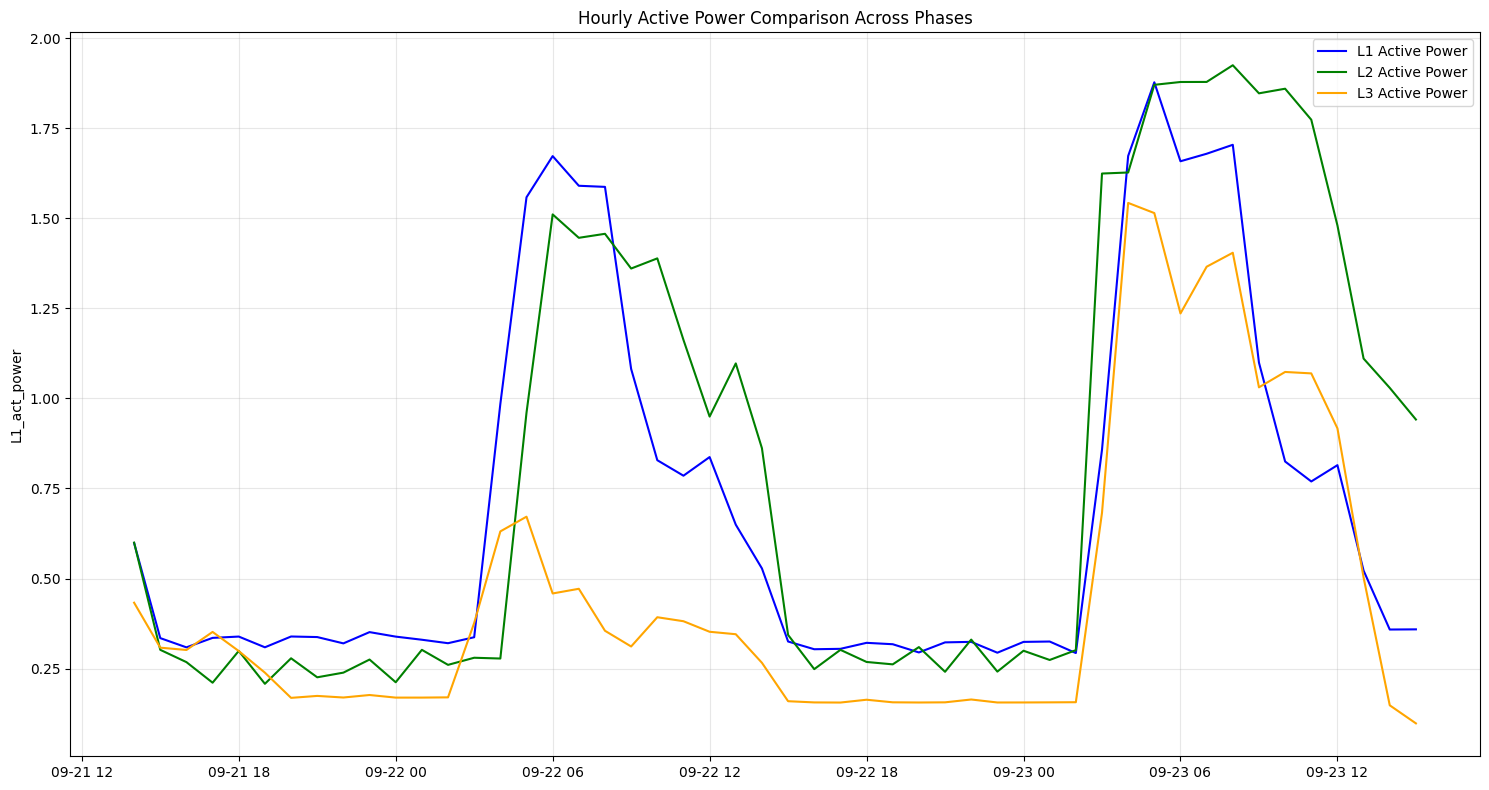

In [30]:
fill_value1 = l1_act_pow_hour_endog.median() if not pd.isna(l1_act_pow_hour_endog.median()) else -100
sns.lineplot(l1_act_pow_hour_endog.fillna(fill_value1).iloc[50:100], label='L1 Active Power', color='blue')
if 'L2_act_power' in df.columns:
    fill_value2 = l2_act_pow_hour_endog.median() if not pd.isna(l2_act_pow_hour_endog.median()) else -100
    sns.lineplot(l2_act_pow_hour_endog.fillna(fill_value2).iloc[50:100], label='L2 Active Power', color='green')
if 'L3_act_power' in df.columns:
    fill_value3 = l3_act_pow_hour_endog.median() if not pd.isna(l3_act_pow_hour_endog.median()) else -100
    sns.lineplot(l3_act_pow_hour_endog.fillna(fill_value3).iloc[50:100], label='L3 Active Power', color='orange')

plt.title("Hourly Active Power Comparison Across Phases")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Weekly Patterns Analysis (based on hourly analysis)

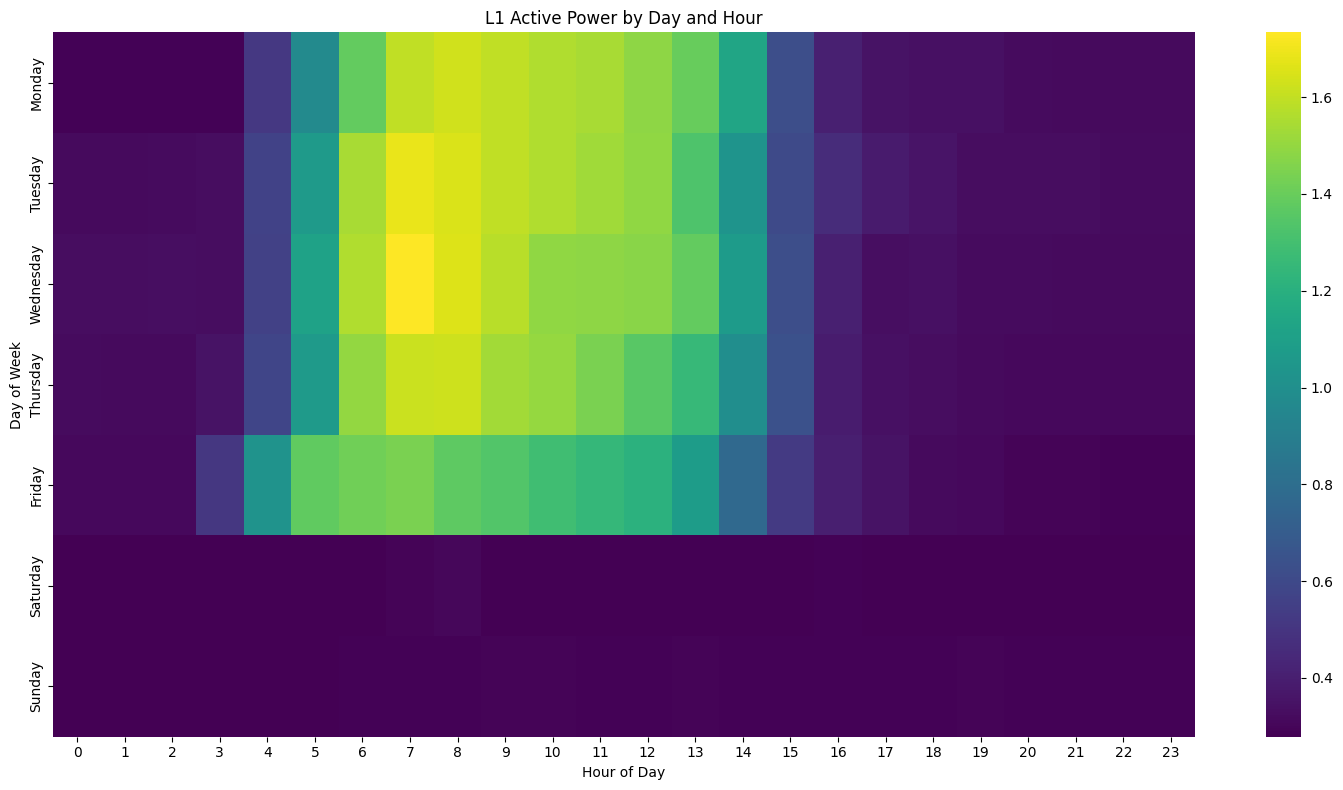

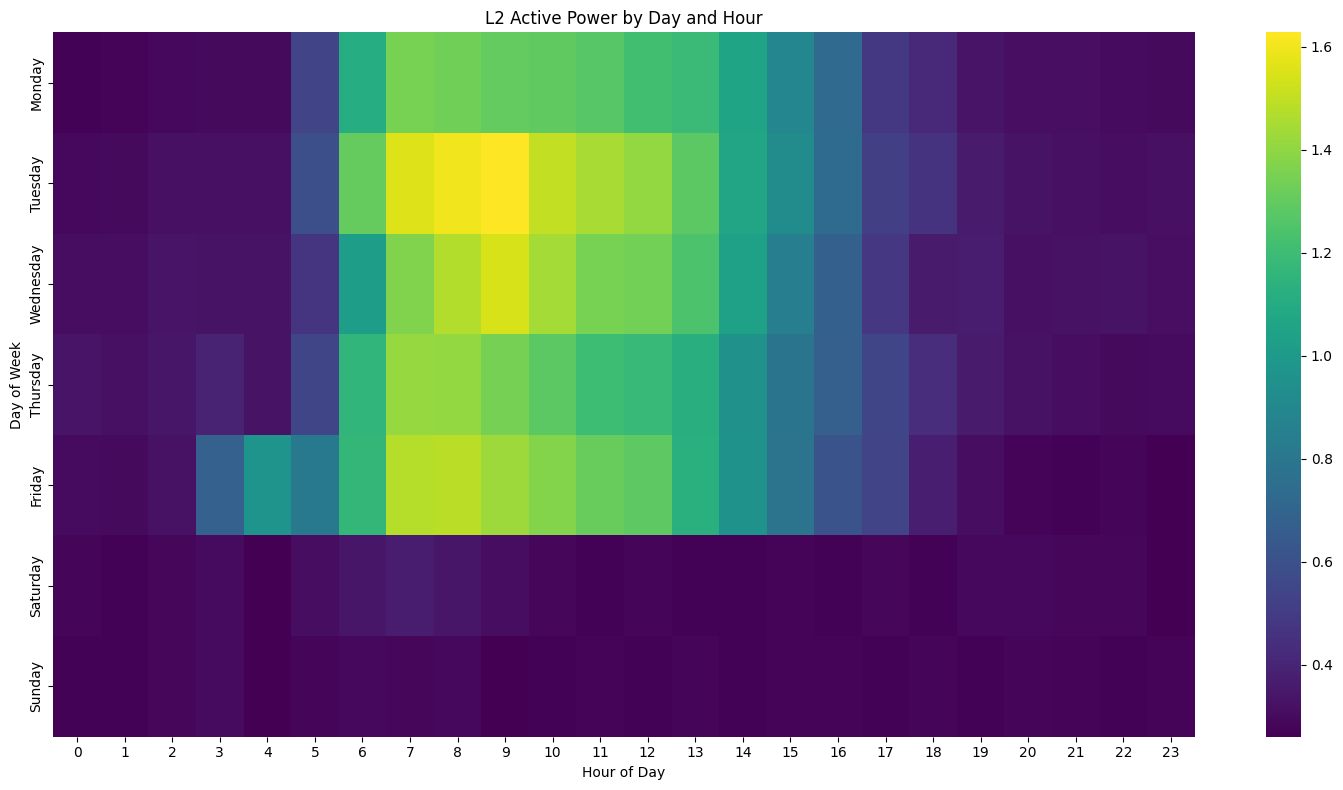

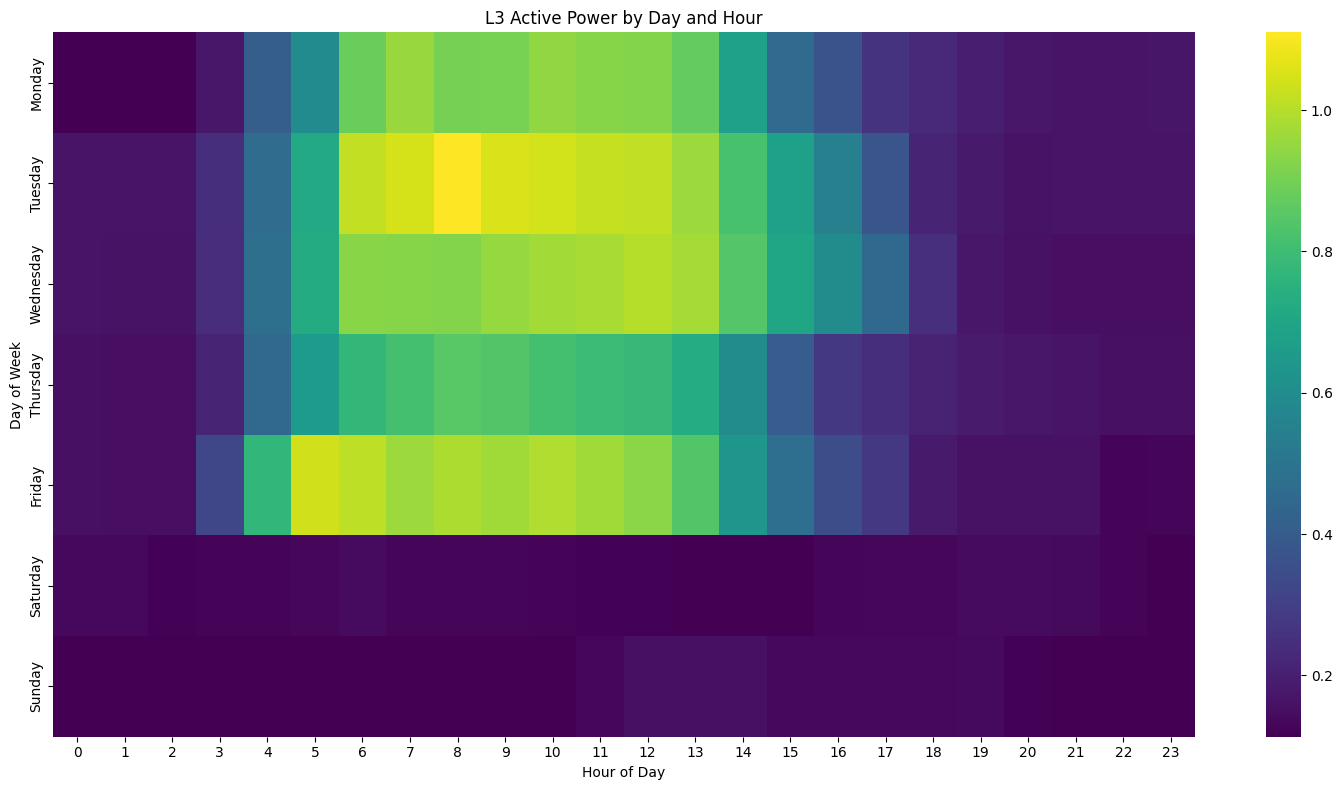

In [31]:
# Extract day of week and hour
df['day_of_week'] = df['timestamp'].dt.day_name()
df['hour'] = df['timestamp'].dt.hour

# Group by day of week and hour
daily_patterns = df.groupby(['day_of_week', 'hour']).agg({
    'L1_act_power': 'mean',
    'L2_act_power': 'mean',
    'L3_act_power': 'mean'
}).reset_index()

# Order days correctly
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
daily_patterns['day_of_week'] = pd.Categorical(daily_patterns['day_of_week'], categories=day_order, ordered=True)
daily_patterns = daily_patterns.sort_values(['day_of_week', 'hour'])

# Plot heatmap for L1
pivot_table = daily_patterns.pivot(index='day_of_week', columns='hour', values='L1_act_power')
sns.heatmap(pivot_table, cmap='viridis', annot=False)
plt.title('L1 Active Power by Day and Hour')
plt.xlabel('Hour of Day')
plt.ylabel('Day of Week')
plt.tight_layout()
plt.show()

if 'L2_act_power' in df.columns:
    # Plot heatmap for L2
    pivot_table = daily_patterns.pivot(index='day_of_week', columns='hour', values='L2_act_power')
    sns.heatmap(pivot_table, cmap='viridis', annot=False)
    plt.title('L2 Active Power by Day and Hour')
    plt.xlabel('Hour of Day')
    plt.ylabel('Day of Week')
    plt.tight_layout()
    plt.show()

if 'L3_act_power' in df.columns:
    # Plot heatmap for L3
    pivot_table = daily_patterns.pivot(index='day_of_week', columns='hour', values='L3_act_power')
    sns.heatmap(pivot_table, cmap='viridis', annot=False)
    plt.title('L3 Active Power by Day and Hour')
    plt.xlabel('Hour of Day')
    plt.ylabel('Day of Week')
    plt.tight_layout()
    plt.show()

## Autocorrelation Analysis

<Figure size 1500x600 with 0 Axes>

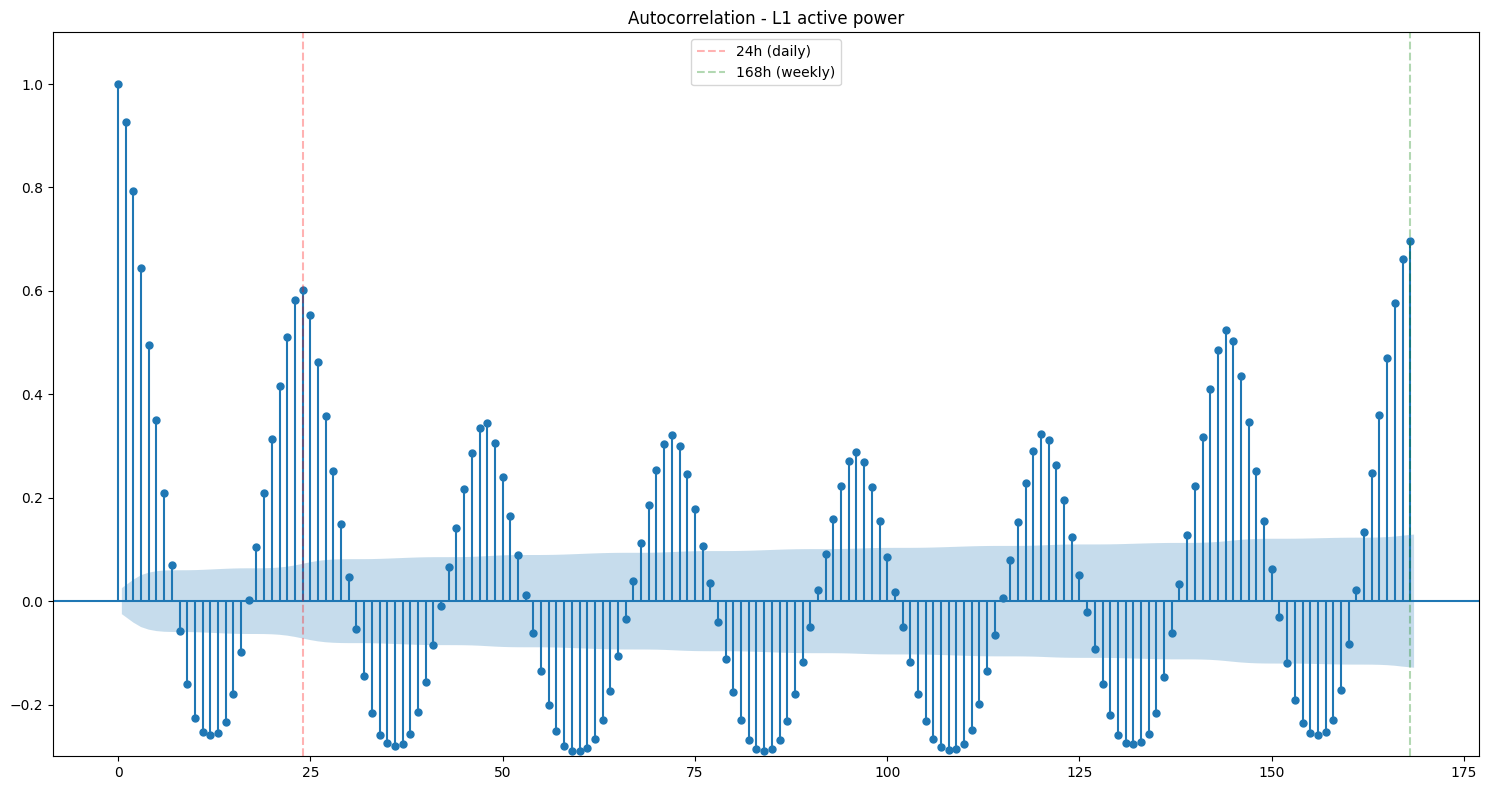

<Figure size 1500x600 with 0 Axes>

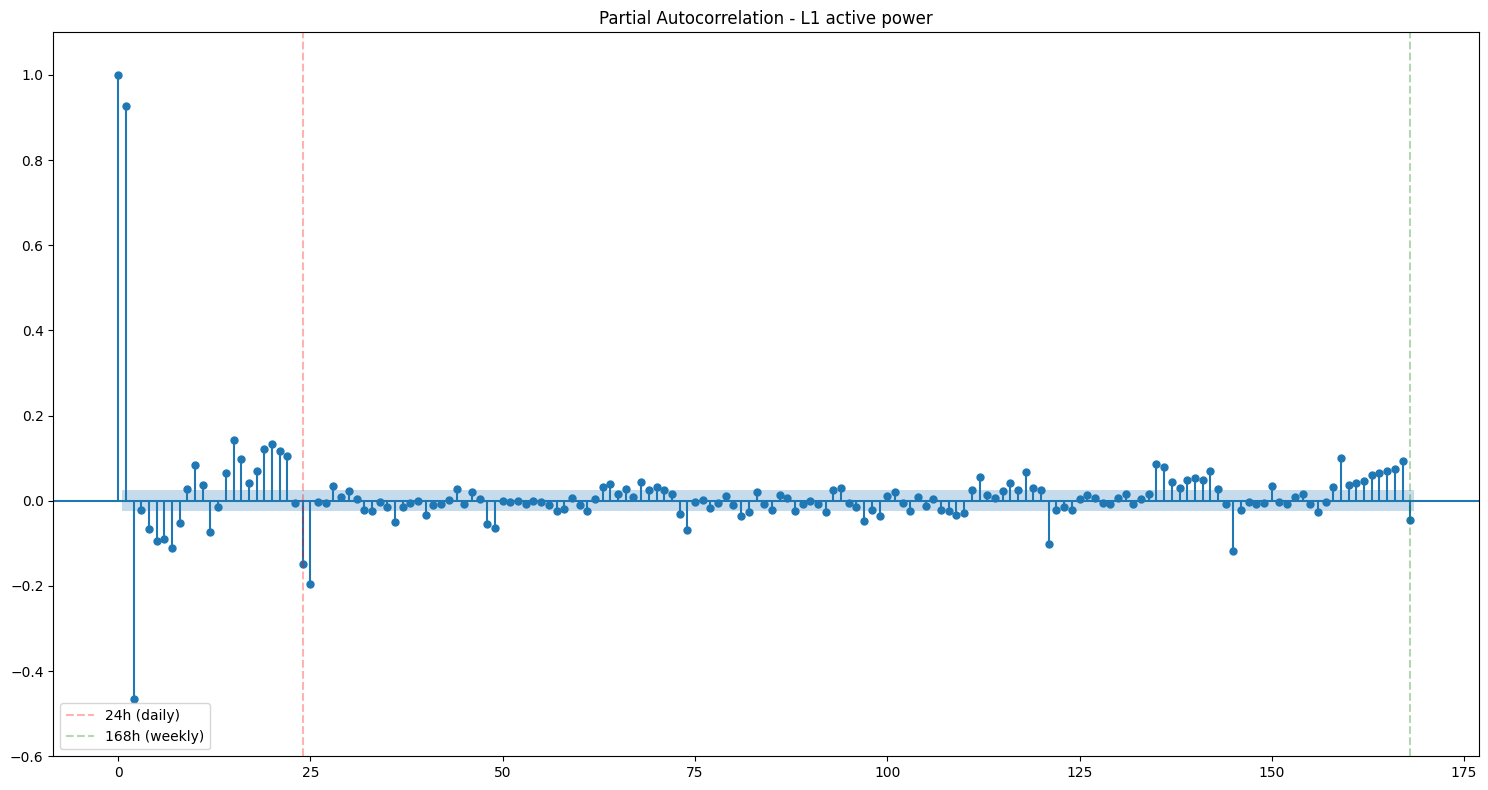

In [34]:
def plot_acf_pacf(series, lags, phase_label):
    fill_value = series.median() if not pd.isna(series.median()) else -100
    filled_series = series.fillna(fill_value)
    
    plt.figure(figsize=(15, 6))
    plot_acf(filled_series, lags=lags, title=f'Autocorrelation - {phase_label} active power')
    plt.ylim(-0.3, 1.1)
    plt.axvline(x=24, color='r', linestyle='--', alpha=0.3, label='24h (daily)')
    plt.axvline(x=24*7, color='g', linestyle='--', alpha=0.3, label='168h (weekly)')
    plt.legend()
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(15, 6))
    plot_pacf(filled_series, lags=lags, title=f'Partial Autocorrelation - {phase_label} active power')
    plt.ylim(-0.6, 1.1)
    plt.axvline(x=24, color='r', linestyle='--', alpha=0.3, label='24h (daily)')
    plt.axvline(x=24*7, color='g', linestyle='--', alpha=0.3, label='168h (weekly)')
    plt.legend()
    plt.tight_layout()
    plt.show()

# L1
plot_acf_pacf(l1_act_pow_hour_endog, lags=24*7, phase_label='L1')

<Figure size 1500x600 with 0 Axes>

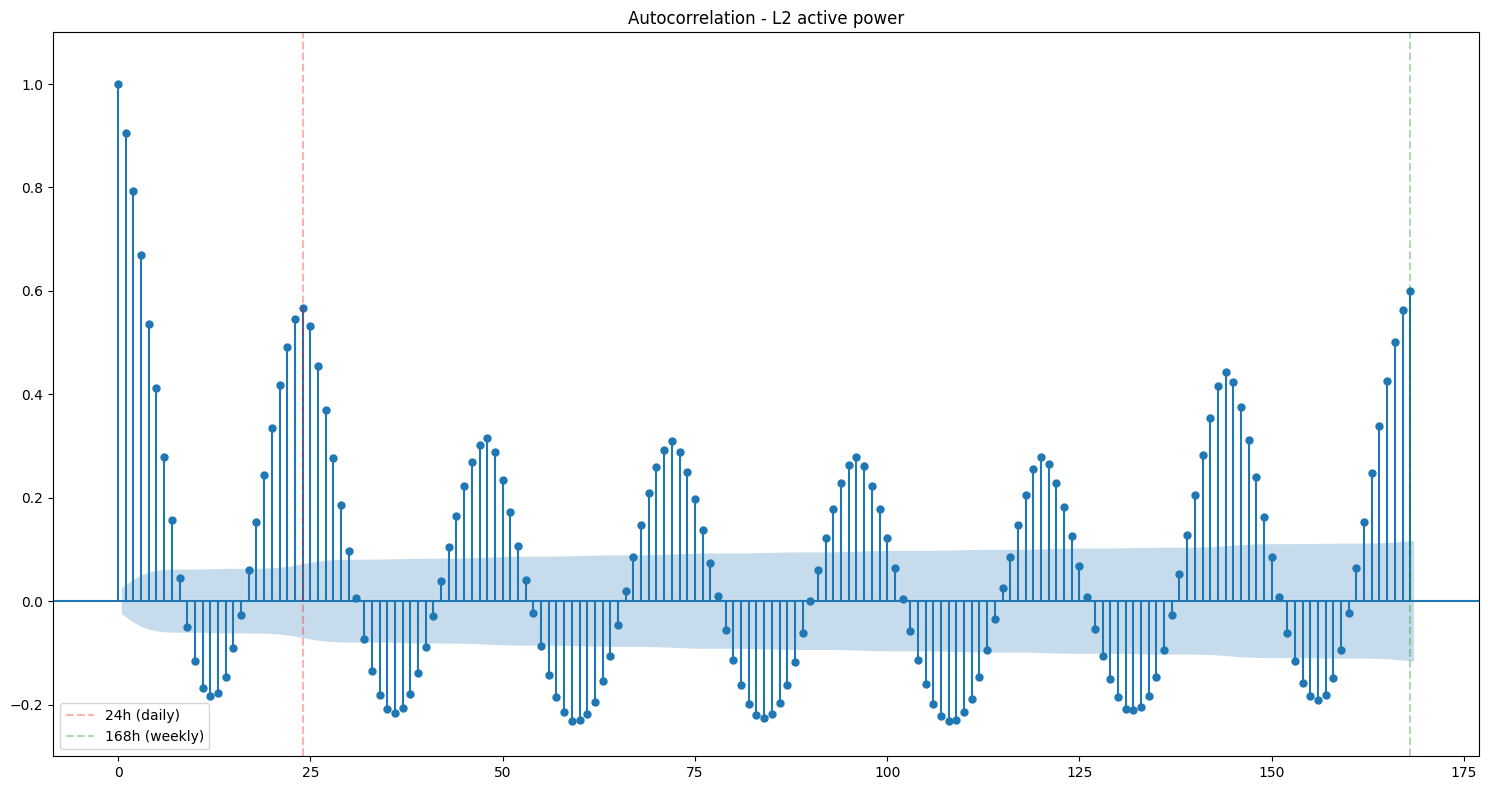

<Figure size 1500x600 with 0 Axes>

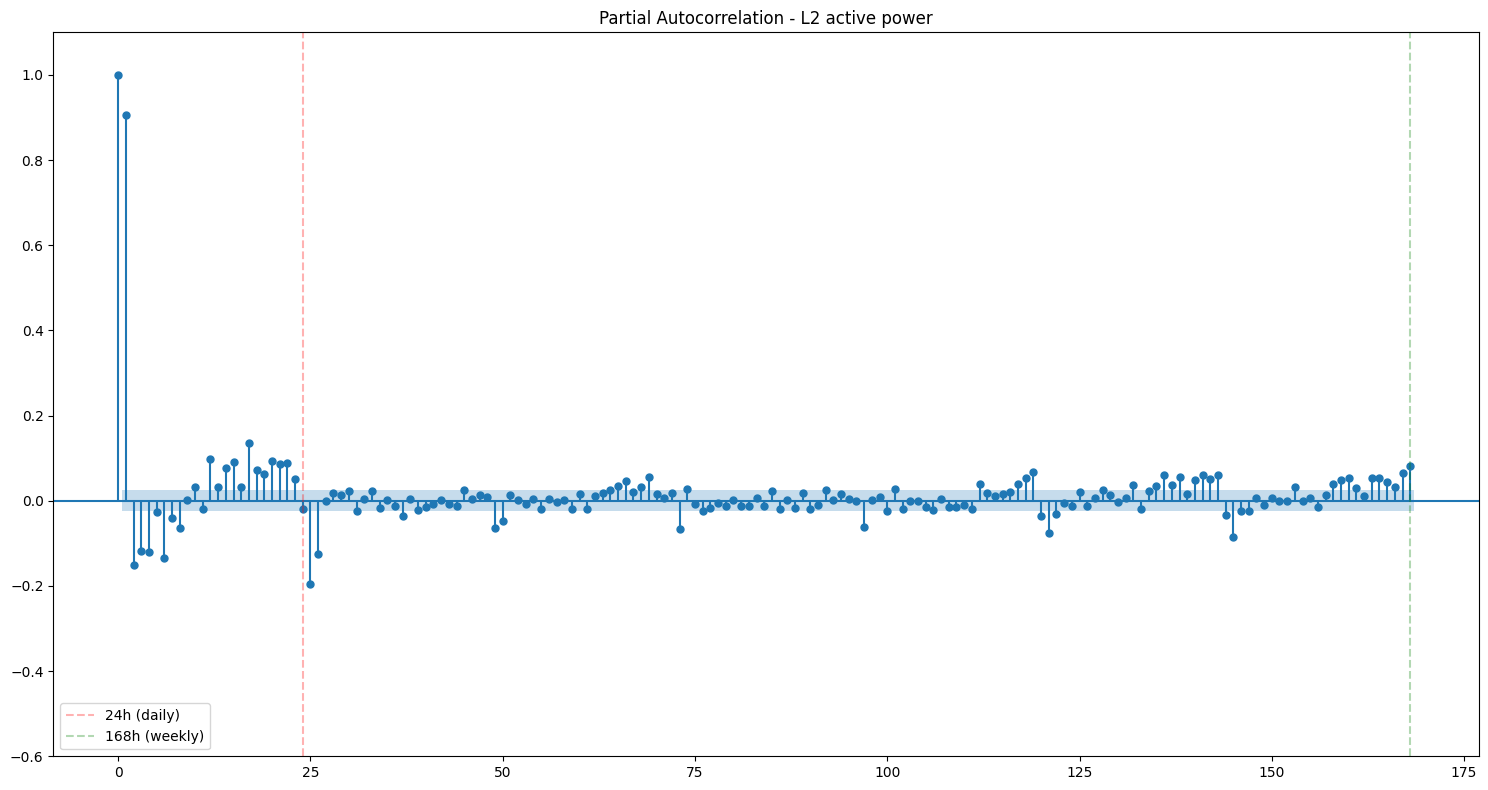

In [35]:
# L2
if 'l2_act_pow_hour_endog' in locals():
    plot_acf_pacf(l2_act_pow_hour_endog, lags=24*7, phase_label='L2')

<Figure size 1500x600 with 0 Axes>

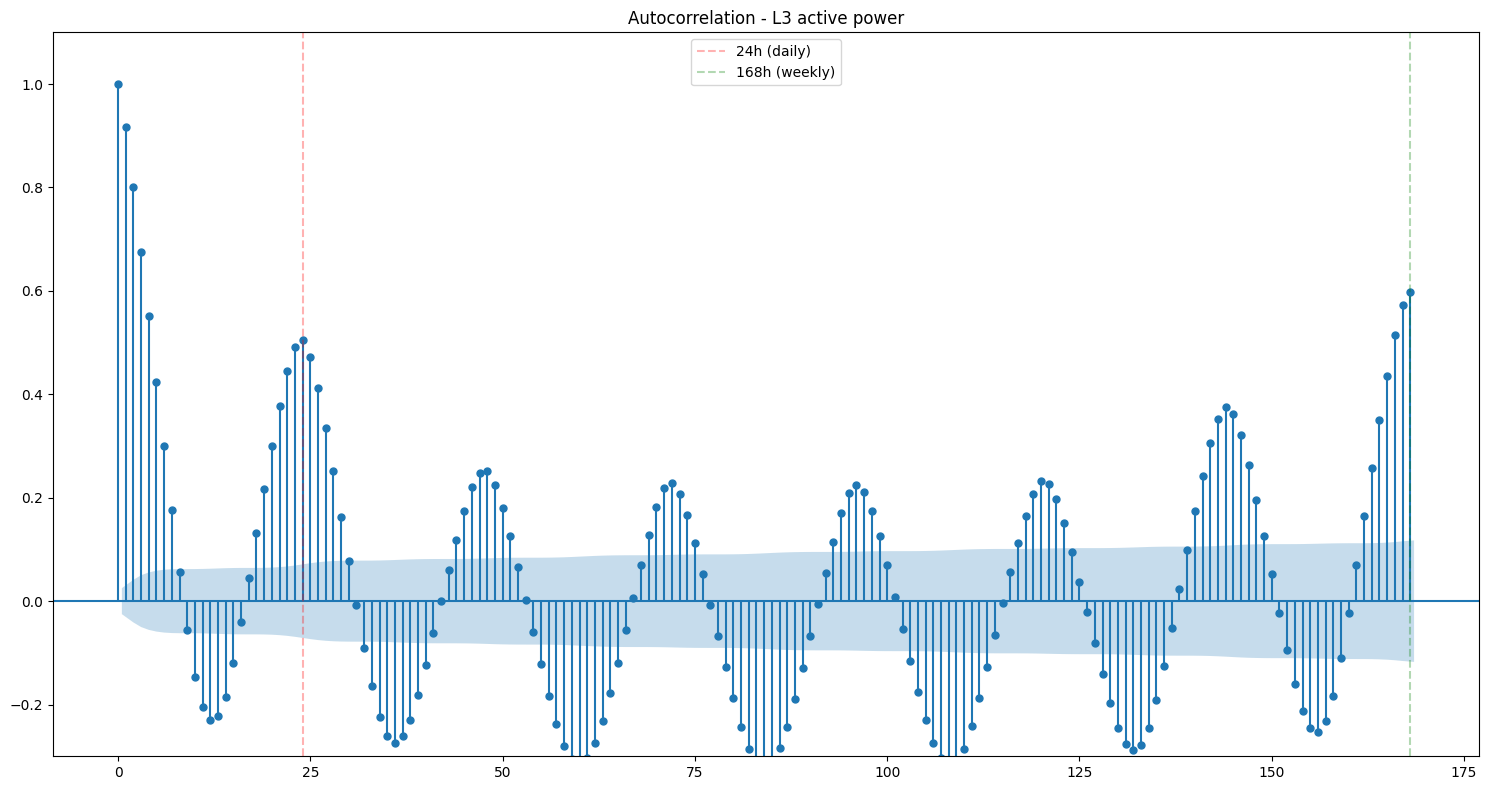

<Figure size 1500x600 with 0 Axes>

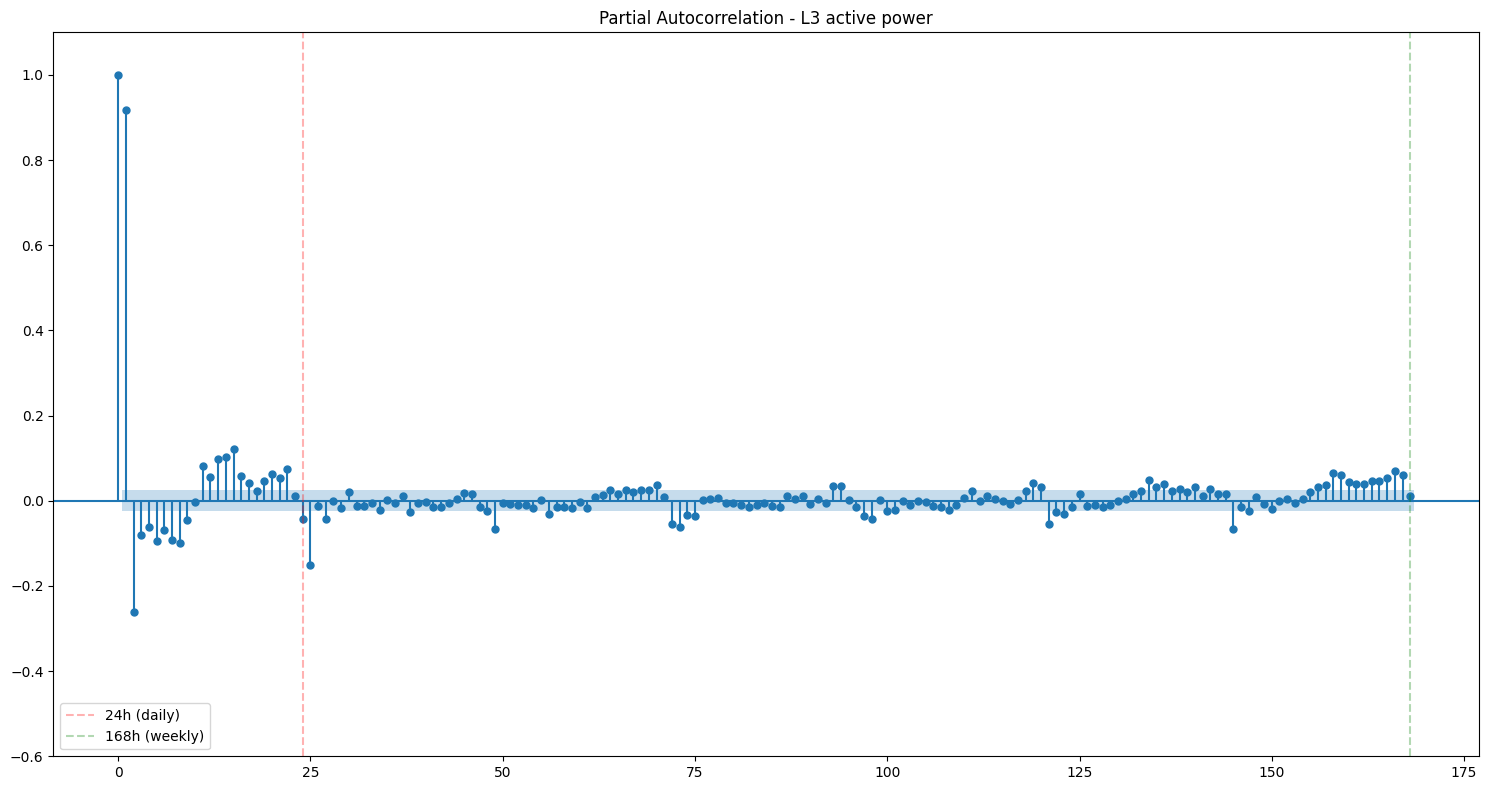

In [36]:
# L3
if 'l3_act_pow_hour_endog' in locals():
    plot_acf_pacf(l3_act_pow_hour_endog, lags=24*7, phase_label='L3')

## 15-min Analysis

In [23]:
# Group by 15-minute intervals
df_15min = df.groupby(df['timestamp'].dt.floor('15min'))

# Create index for full time range
full_range = pd.DataFrame(
    index=pd.date_range(
        pd.DatetimeIndex(df_15min.indices.keys()).min(),
        pd.DatetimeIndex(df_15min.indices.keys()).max(), 
        freq='15min'
    )
)

# Join with hourly aggregated data for each phase
l1_act_pow_15m_endog = full_range.join(df_15min['L1_act_power'].mean(), how='left').squeeze()
if 'L2_act_power' in df.columns:
    l2_act_pow_15m_endog = full_range.join(df_15min['L2_act_power'].mean(), how='left').squeeze()
if 'L3_act_power' in df.columns:
    l3_act_pow_15m_endog = full_range.join(df_15min['L3_act_power'].mean(), how='left').squeeze()

In [24]:
df_15min.count().describe()

,timestamp,L1_act_power,L1_app_power,L1_current,L1_react_power,L1_voltage,L2_act_power,L2_app_power,L2_current,L2_react_power,L2_voltage,L3_act_power,L3_app_power,L3_current,L3_react_power,L3_voltage,grid_freq,powerfactor1,powerfactor2,powerfactor3
count,24319.000000,24319.000000,24319.000000,24319.000000,24319.000000,24319.000000,24319.000000,24319.000000,24319.000000,24319.000000,24319.000000,24319.000000,24319.000000,24319.000000,24319.000000,24319.000000,24319.000000,24319.000000,24319.000000,24319.000000
mean,899.960525,518.376907,518.376907,518.376907,518.376907,518.376907,518.376907,518.376907,518.376907,518.376907,518.376907,518.376907,518.376907,518.376907,518.376907,518.376907,518.376907,518.376907,518.376907,518.376907
std,5.157333,189.737129,189.737129,189.737129,189.737129,189.737129,189.737129,189.737129,189.737129,189.737129,189.737129,189.737129,189.737129,189.737129,189.737129,189.737129,189.737129,189.737129,189.737129,189.737129
min,115.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,900.000000,572.000000,572.000000,572.000000,572.000000,572.000000,572.000000,572.000000,572.000000,572.000000,572.000000,572.000000,572.000000,572.000000,572.000000,572.000000,572.000000,572.000000,572.000000,572.000000
50%,900.000000,595.000000,595.000000,595.000000,595.000000,595.000000,595.000000,595.000000,595.000000,595.000000,595.000000,595.000000,595.000000,595.000000,595.000000,595.000000,595.000000,595.000000,595.000000,595.000000
75%,900.000000,600.000000,600.000000,600.000000,600.000000,600.000000,600.000000,600.000000,600.000000,600.000000,600.000000,600.000000,600.000000,600.000000,600.000000,600.000000,600.000000,600.000000,600.000000,600.000000
max,900.000000,690.000000,690.000000,690.000000,690.000000,690.000000,690.000000,690.000000,690.000000,690.000000,690.000000,690.000000,690.000000,690.000000,690.000000,690.000000,690.000000,690.000000,690.000000,690.000000


In [25]:
def plot_15m_data(series, title, color='blue'):
    # Choose a sensible default value for missing data
    fill_value = series.median() if not pd.isna(series.median()) else -100
    
     
    sns.lineplot(series.fillna(fill_value), label=f'15min {title}', color=color)
    
    # Mark missing values
    plt.scatter(
        x=series[series.isna()].index,
        y=[series.min()-0.01]*series[series.isna()].shape[0],
        color='red',
        marker='x',
        label='missing'
    )
    
    plt.title(f"15-min {title}")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

### Separate by phase

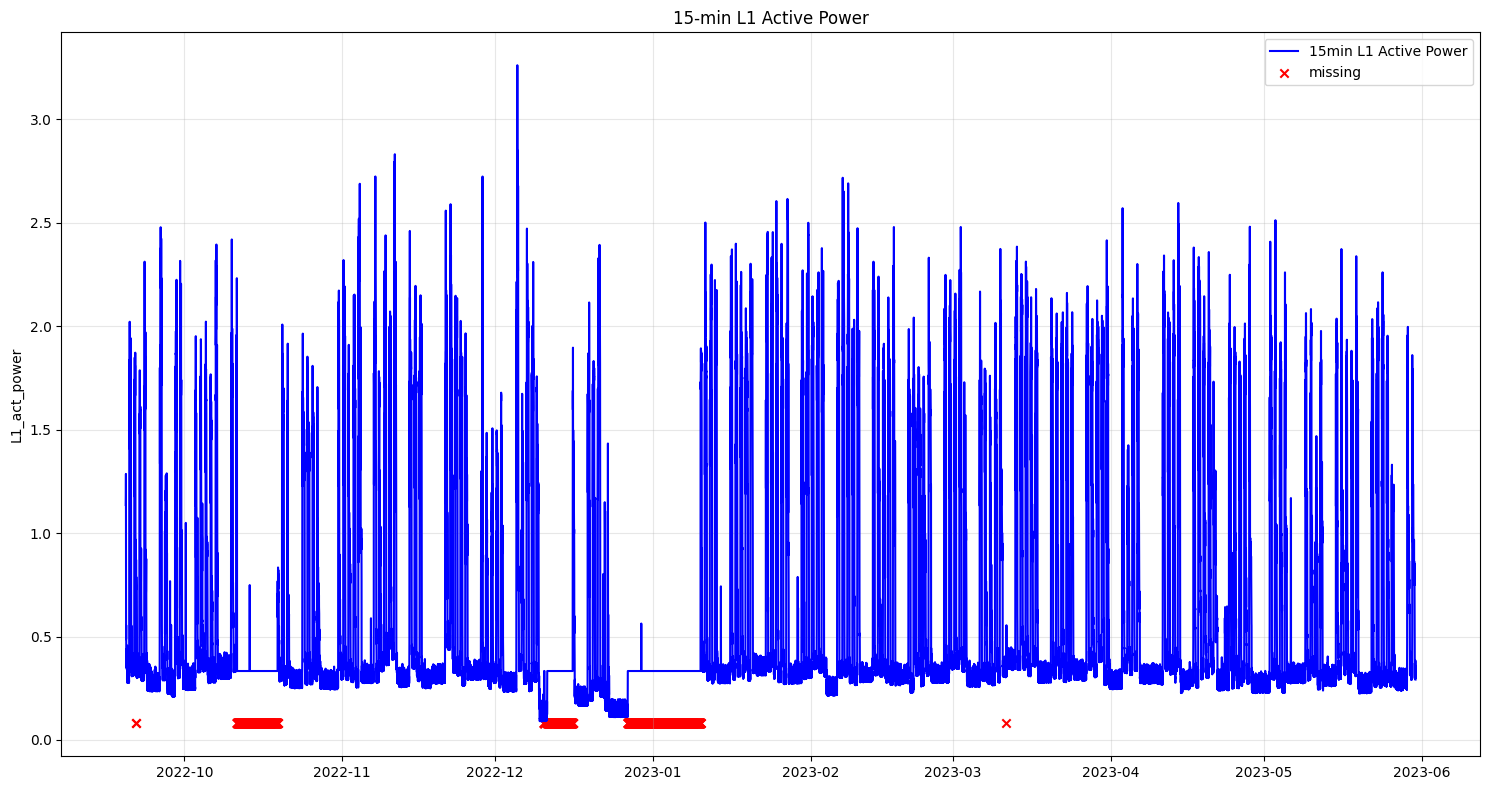

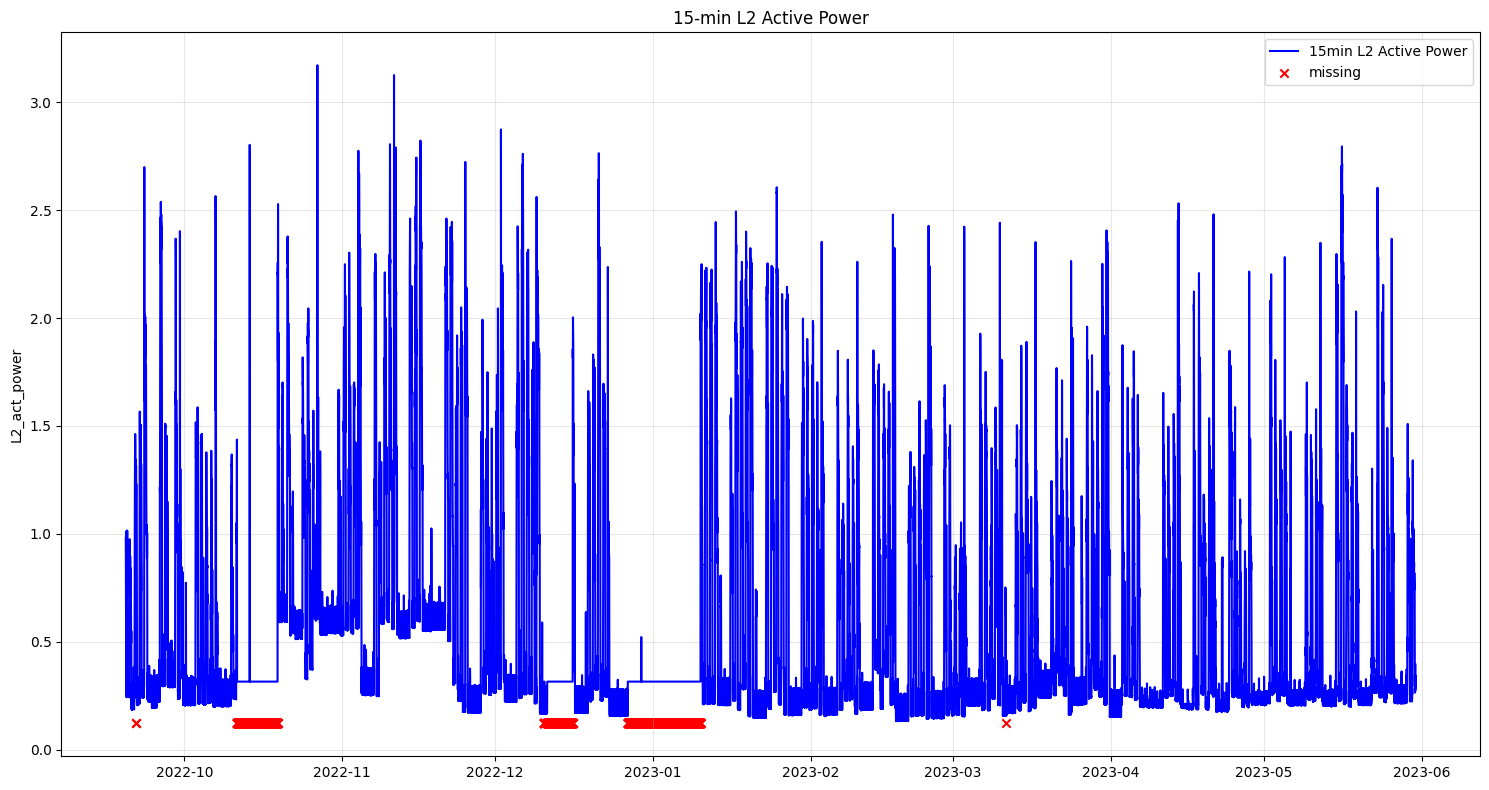

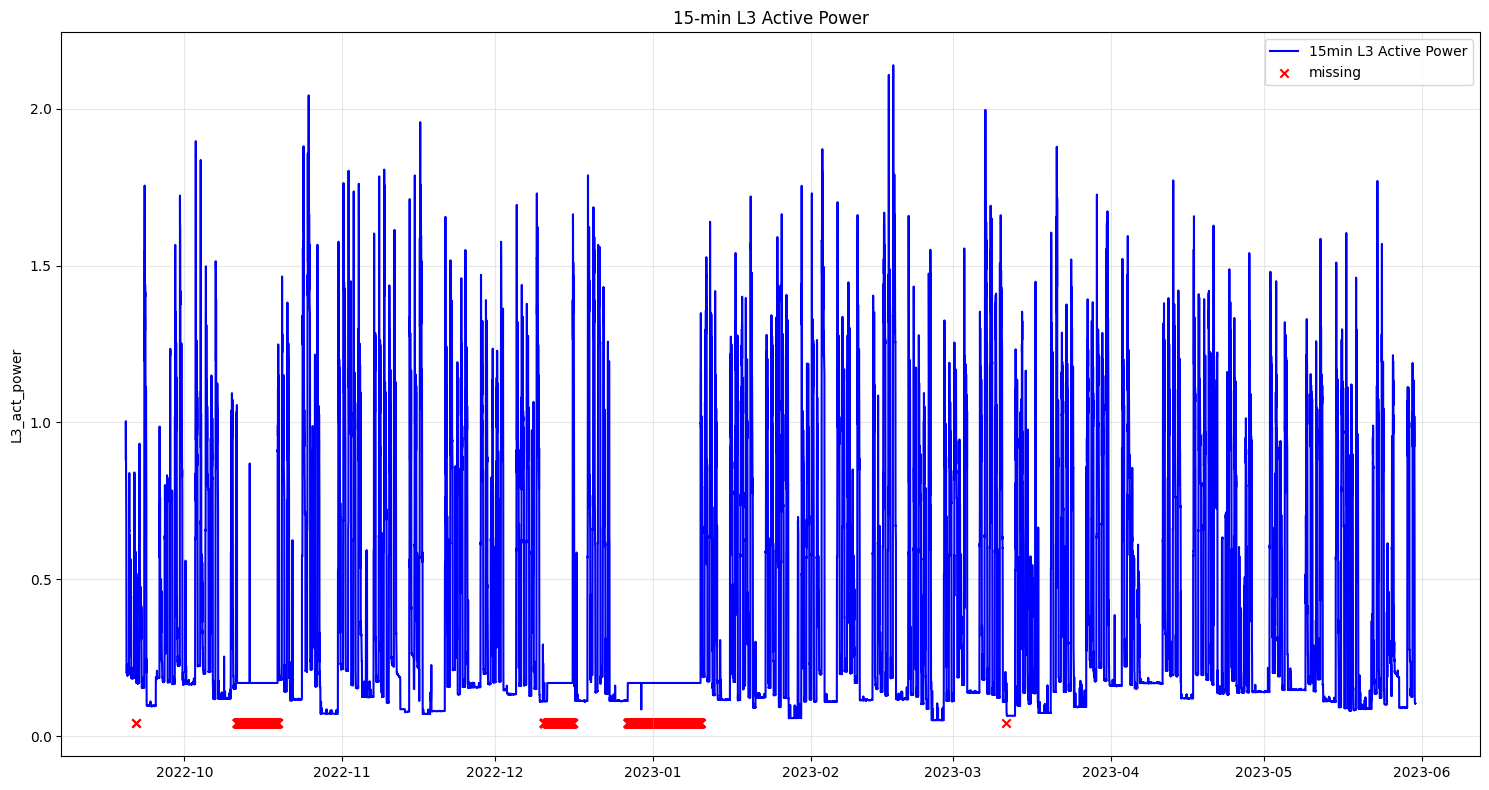

In [26]:
plot_15m_data(l1_act_pow_15m_endog, 'L1 Active Power')
if 'L2_act_power' in df.columns:
    plot_15m_data(l2_act_pow_15m_endog, 'L2 Active Power')
if 'L3_act_power' in df.columns:
    plot_15m_data(l3_act_pow_15m_endog, 'L3 Active Power')

### Detect peaks

C:\Users\HP\AppData\Local\Temp\ipykernel_16416\555613157.py:23: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  plt.plot(x[peaks], y[peaks], "r^", label="Spikes")
C:\Users\HP\AppData\Local\Temp\ipykernel_16416\555613157.py:24: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  plt.plot(x[drops], y[drops], "bv", label="Drops")


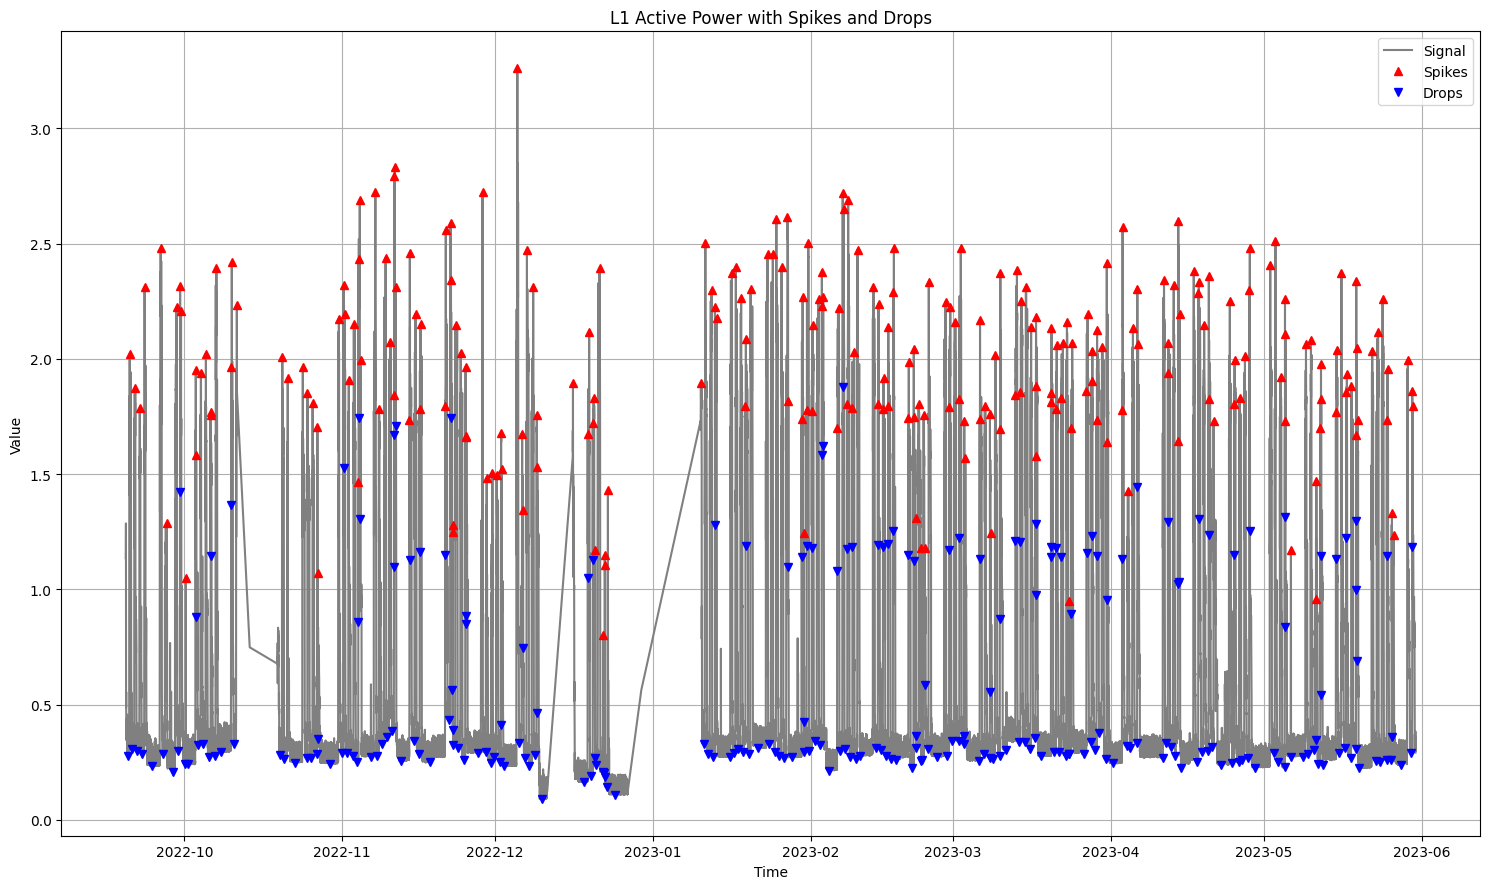

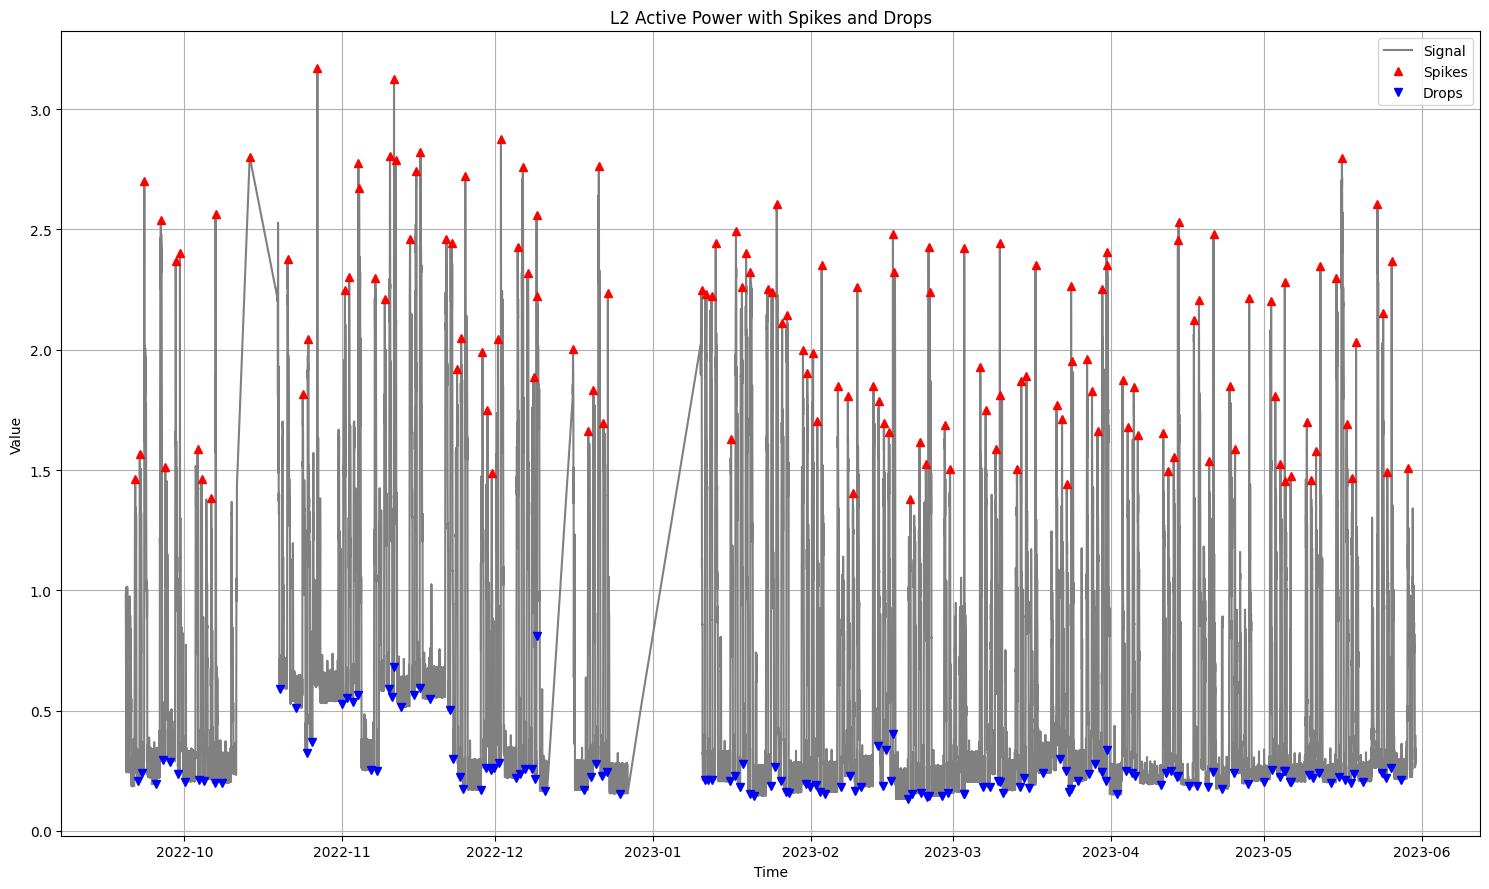

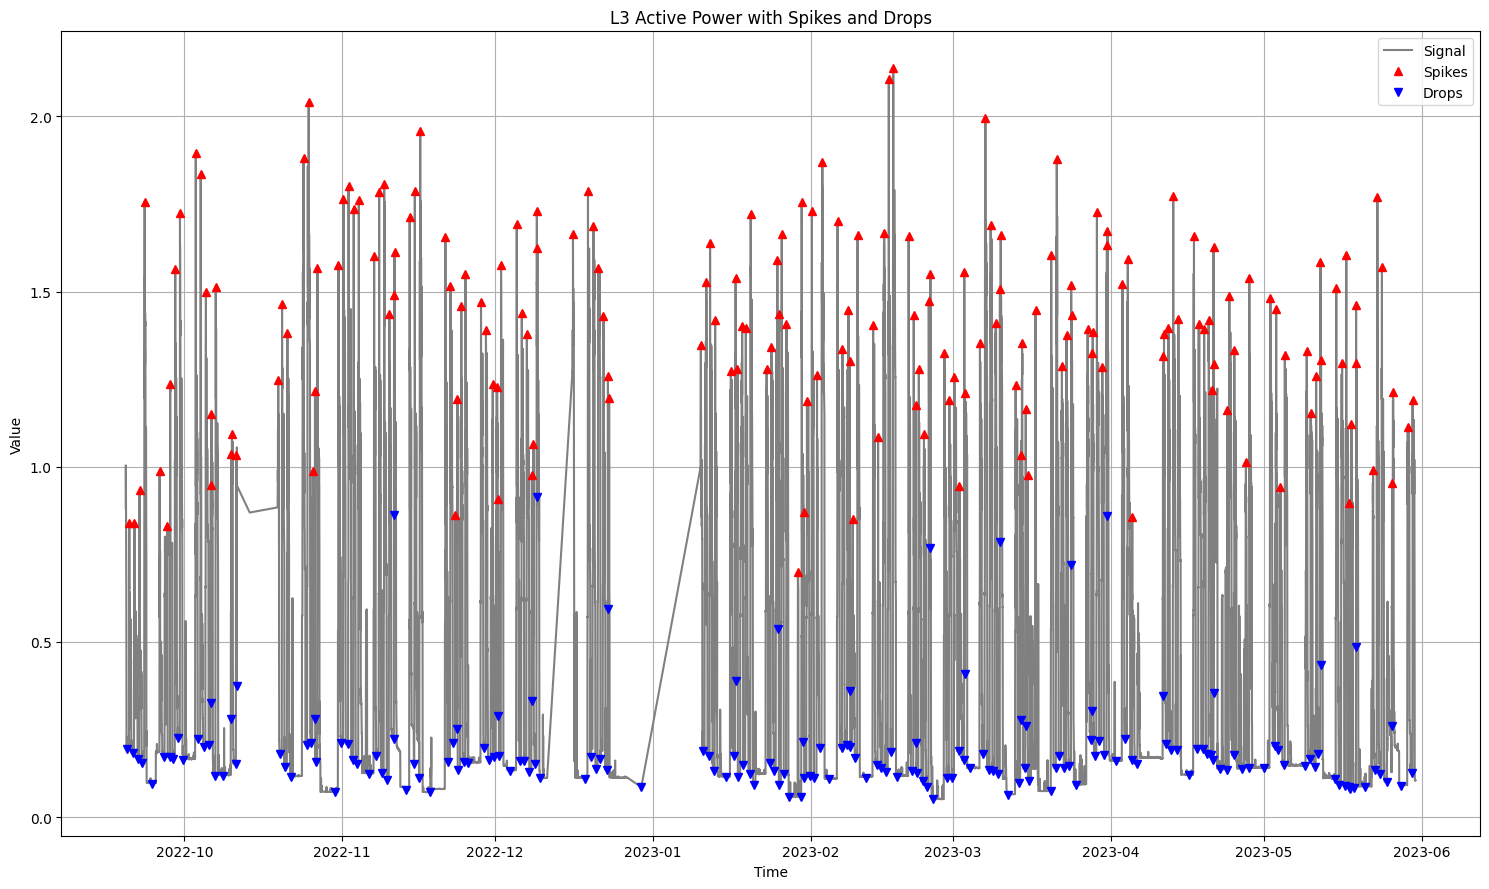

In [31]:
plot_spikes_and_drops(l1_act_pow_15m_endog.dropna().index,
                      l1_act_pow_15m_endog.dropna(), 
                      title="L1 Active Power with Spikes and Drops",
                      prominence=9, robust=True)
if 'L2_act_power' in df.columns:
    plot_spikes_and_drops(l2_act_pow_15m_endog.dropna().index,
                          l2_act_pow_15m_endog.dropna(), 
                          title="L2 Active Power with Spikes and Drops",
                          prominence=9, robust=True)
if 'L3_act_power' in df.columns:
    plot_spikes_and_drops(l3_act_pow_15m_endog.dropna().index,
                          l3_act_pow_15m_endog.dropna(), 
                          title="L3 Active Power with Spikes and Drops",
                          prominence=9, robust=True)

### Cross-phase

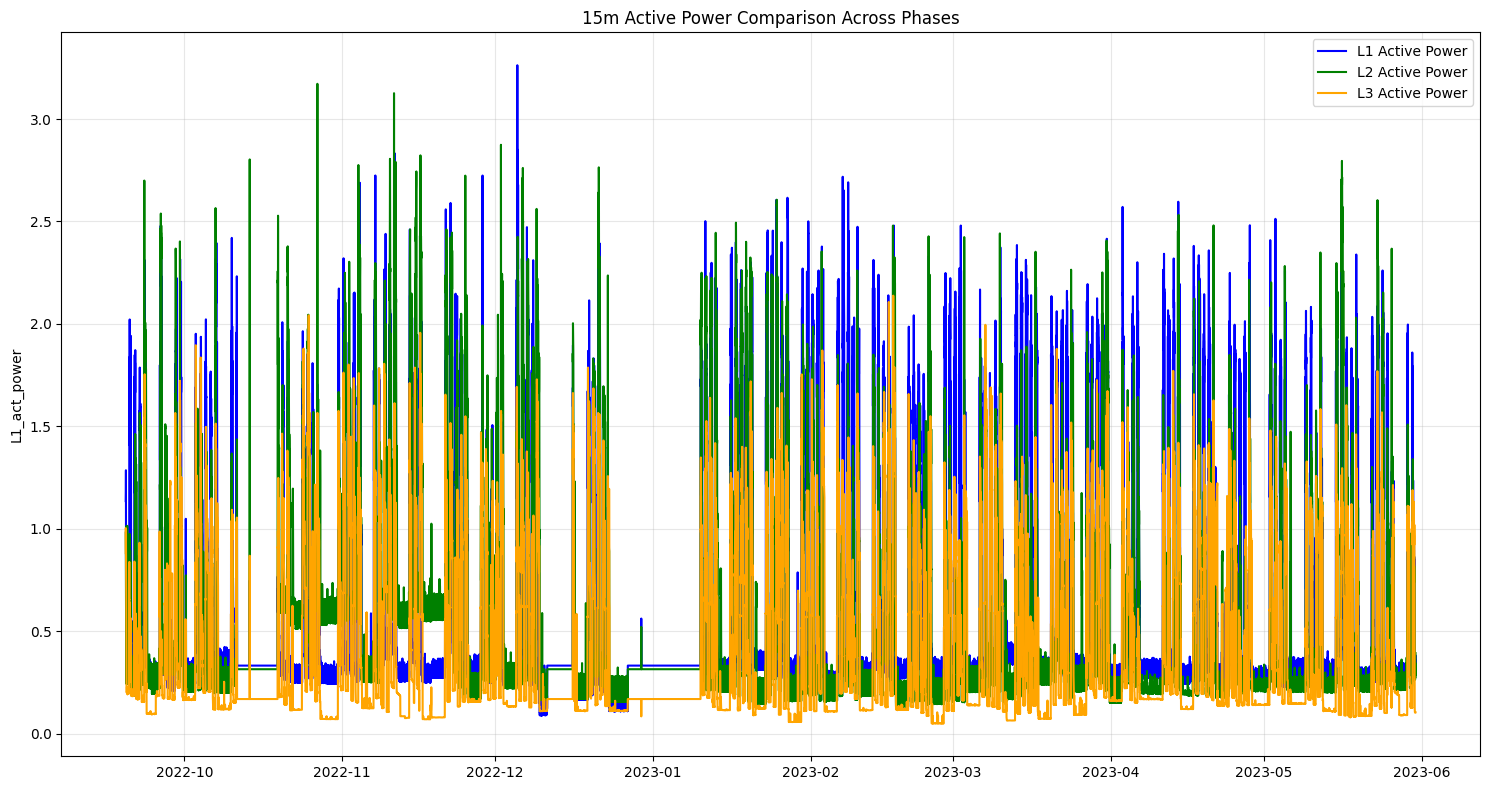

In [32]:
fill_value1 = l1_act_pow_15m_endog.median() if not pd.isna(l1_act_pow_15m_endog.median()) else -100
sns.lineplot(l1_act_pow_15m_endog.fillna(fill_value1), label='L1 Active Power', color='blue')
if 'L2_act_power' in df.columns:
    fill_value2 = l2_act_pow_15m_endog.median() if not pd.isna(l2_act_pow_15m_endog.median()) else -100
    sns.lineplot(l2_act_pow_15m_endog.fillna(fill_value2), label='L2 Active Power', color='green')
if 'L3_act_power' in df.columns:
    fill_value3 = l3_act_pow_15m_endog.median() if not pd.isna(l3_act_pow_15m_endog.median()) else -100
    sns.lineplot(l3_act_pow_15m_endog.fillna(fill_value3), label='L3 Active Power', color='orange')

plt.title("15m Active Power Comparison Across Phases")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Cross-phase (smaller time range)

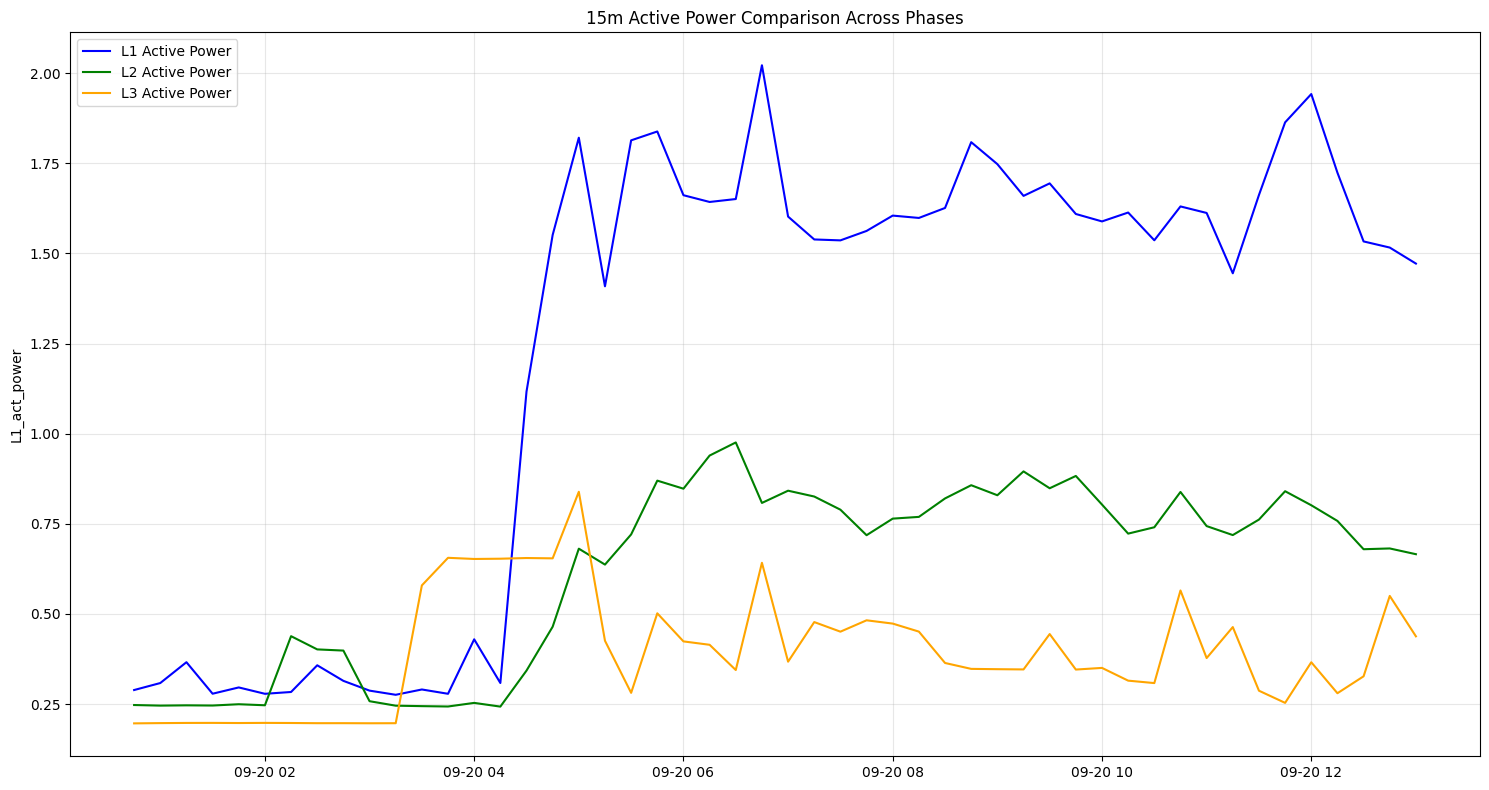

In [33]:
fill_value1 = l1_act_pow_15m_endog.median() if not pd.isna(l1_act_pow_15m_endog.median()) else -100
sns.lineplot(l1_act_pow_15m_endog.fillna(fill_value1).iloc[50:100], label='L1 Active Power', color='blue')
if 'L2_act_power' in df.columns:
    fill_value2 = l2_act_pow_15m_endog.median() if not pd.isna(l2_act_pow_15m_endog.median()) else -100
    sns.lineplot(l2_act_pow_15m_endog.fillna(fill_value2).iloc[50:100], label='L2 Active Power', color='green')
if 'L3_act_power' in df.columns:
    fill_value3 = l3_act_pow_15m_endog.median() if not pd.isna(l3_act_pow_15m_endog.median()) else -100
    sns.lineplot(l3_act_pow_15m_endog.fillna(fill_value3).iloc[50:100], label='L3 Active Power', color='orange')

plt.title("15m Active Power Comparison Across Phases")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Autocorrelation Analysis

<Figure size 1500x600 with 0 Axes>

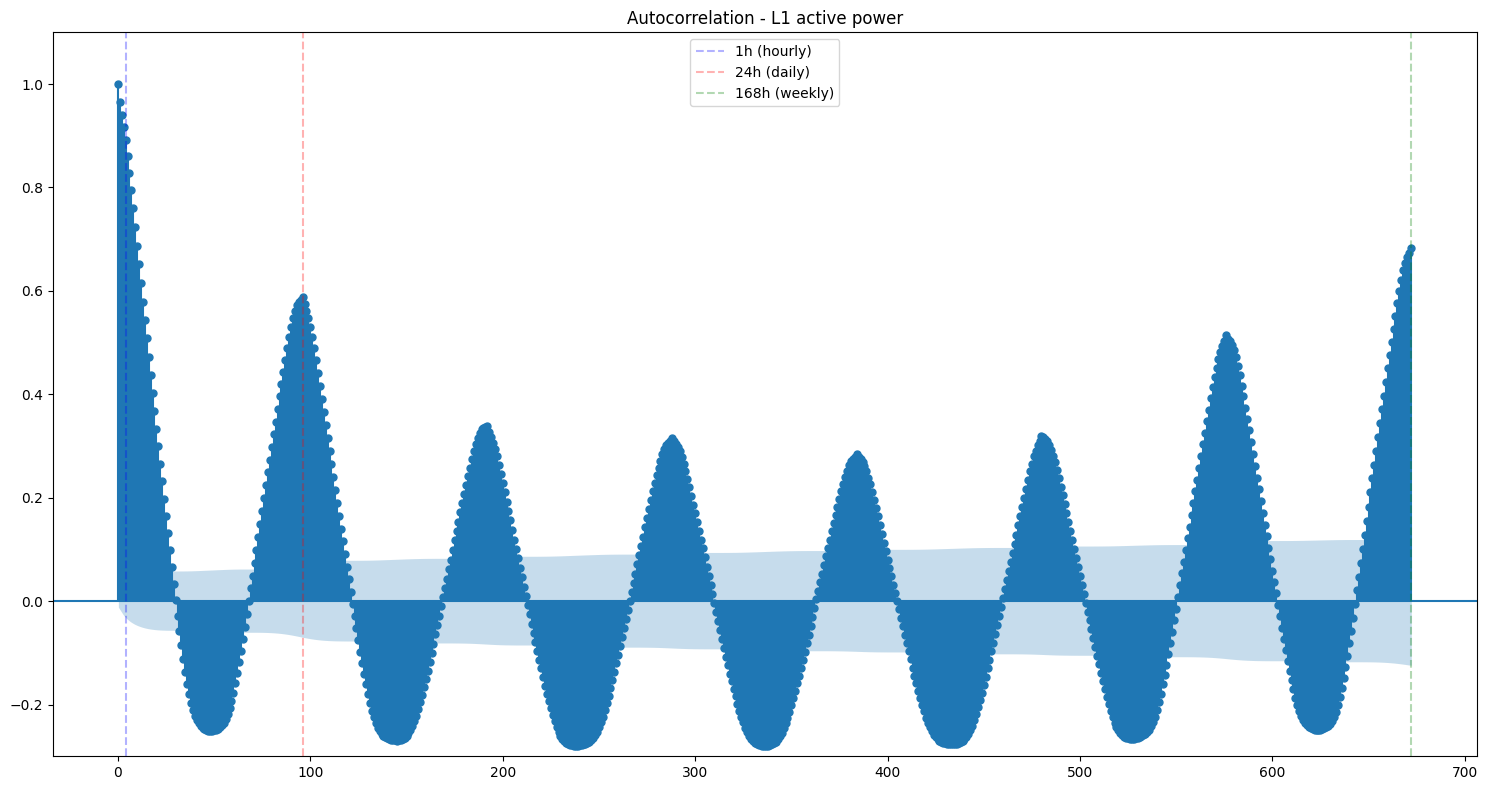

<Figure size 1500x600 with 0 Axes>

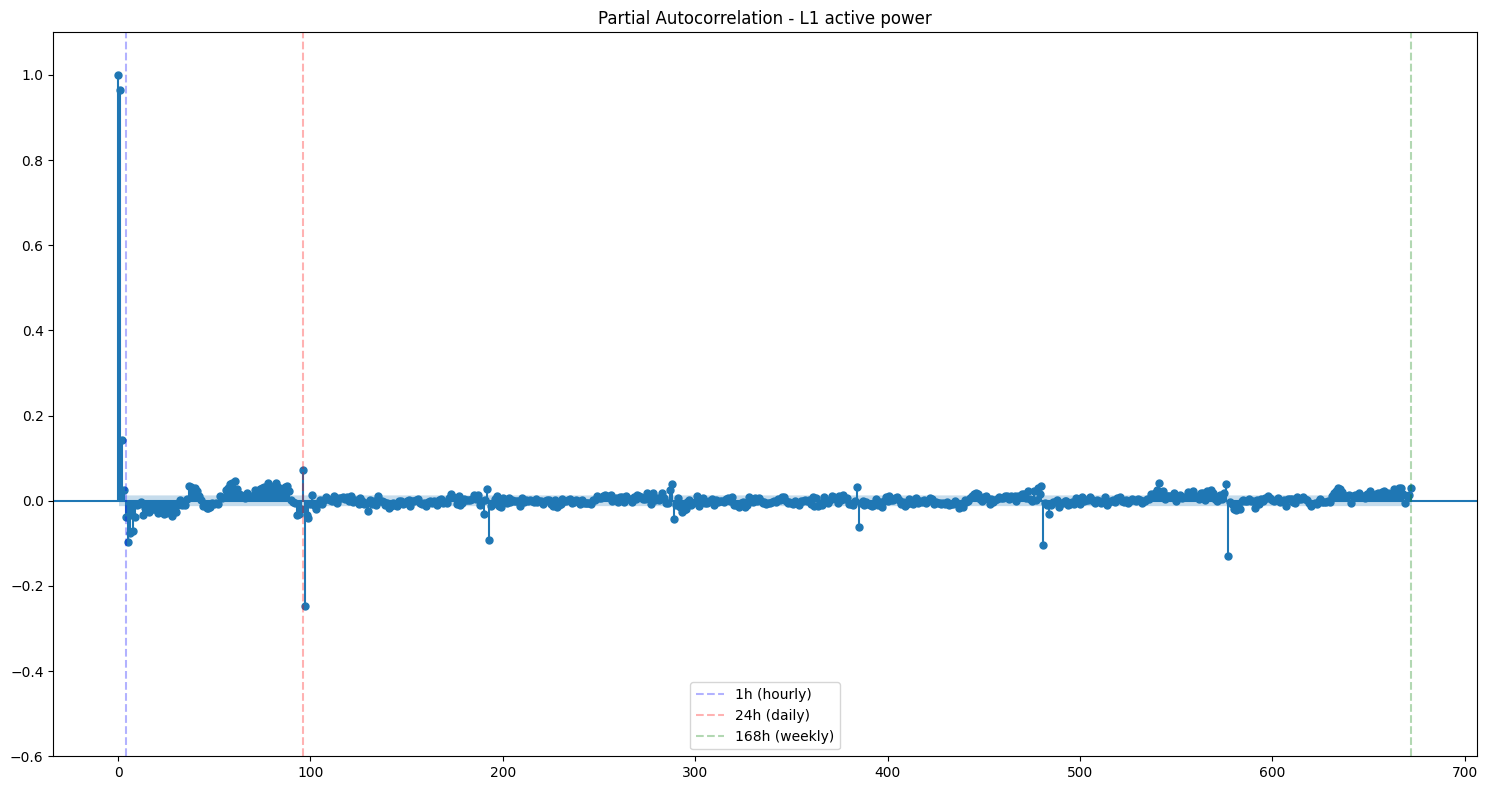

In [35]:
def plot_acf_pacf(series, lags, phase_label):
    fill_value = series.median() if not pd.isna(series.median()) else -100
    filled_series = series.fillna(fill_value)
    
    plt.figure(figsize=(15, 6))
    plot_acf(filled_series, lags=lags, title=f'Autocorrelation - {phase_label} active power')
    plt.ylim(-0.3, 1.1)
    plt.axvline(x=4, color='b', linestyle='--', alpha=0.3, label='1h (hourly)')
    plt.axvline(x=24*4, color='r', linestyle='--', alpha=0.3, label='24h (daily)')
    plt.axvline(x=24*7*4, color='g', linestyle='--', alpha=0.3, label='168h (weekly)')
    plt.legend()
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(15, 6))
    plot_pacf(filled_series, lags=lags, title=f'Partial Autocorrelation - {phase_label} active power')
    plt.ylim(-0.6, 1.1)
    plt.axvline(x=4, color='b', linestyle='--', alpha=0.3, label='1h (hourly)')
    plt.axvline(x=24*4, color='r', linestyle='--', alpha=0.3, label='24h (daily)')
    plt.axvline(x=24*7*4, color='g', linestyle='--', alpha=0.3, label='168h (weekly)')
    plt.legend()
    plt.tight_layout()
    plt.show()

# L1
plot_acf_pacf(l1_act_pow_15m_endog, lags=24*7*4, phase_label='L1')

<Figure size 1500x600 with 0 Axes>

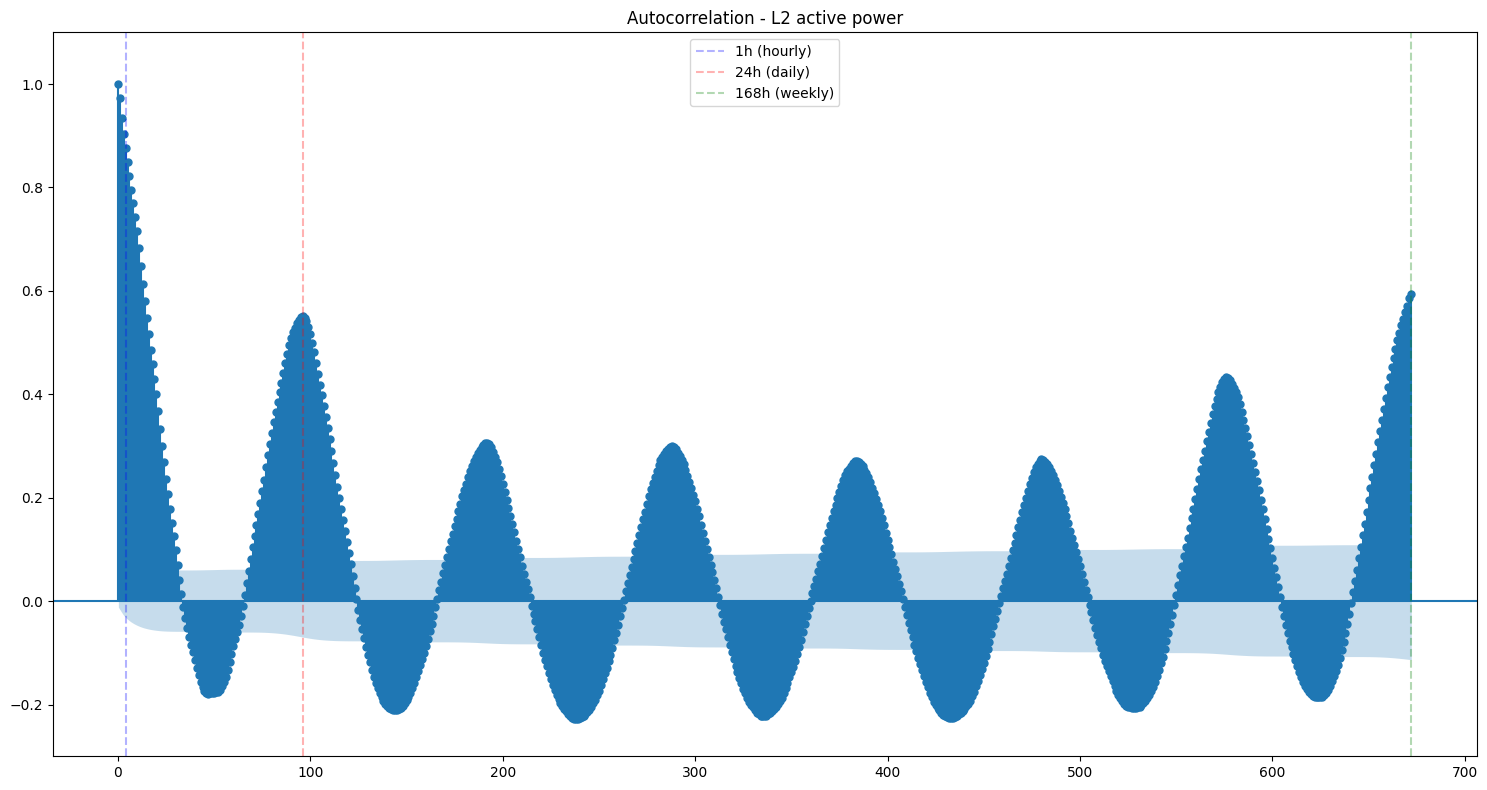

<Figure size 1500x600 with 0 Axes>

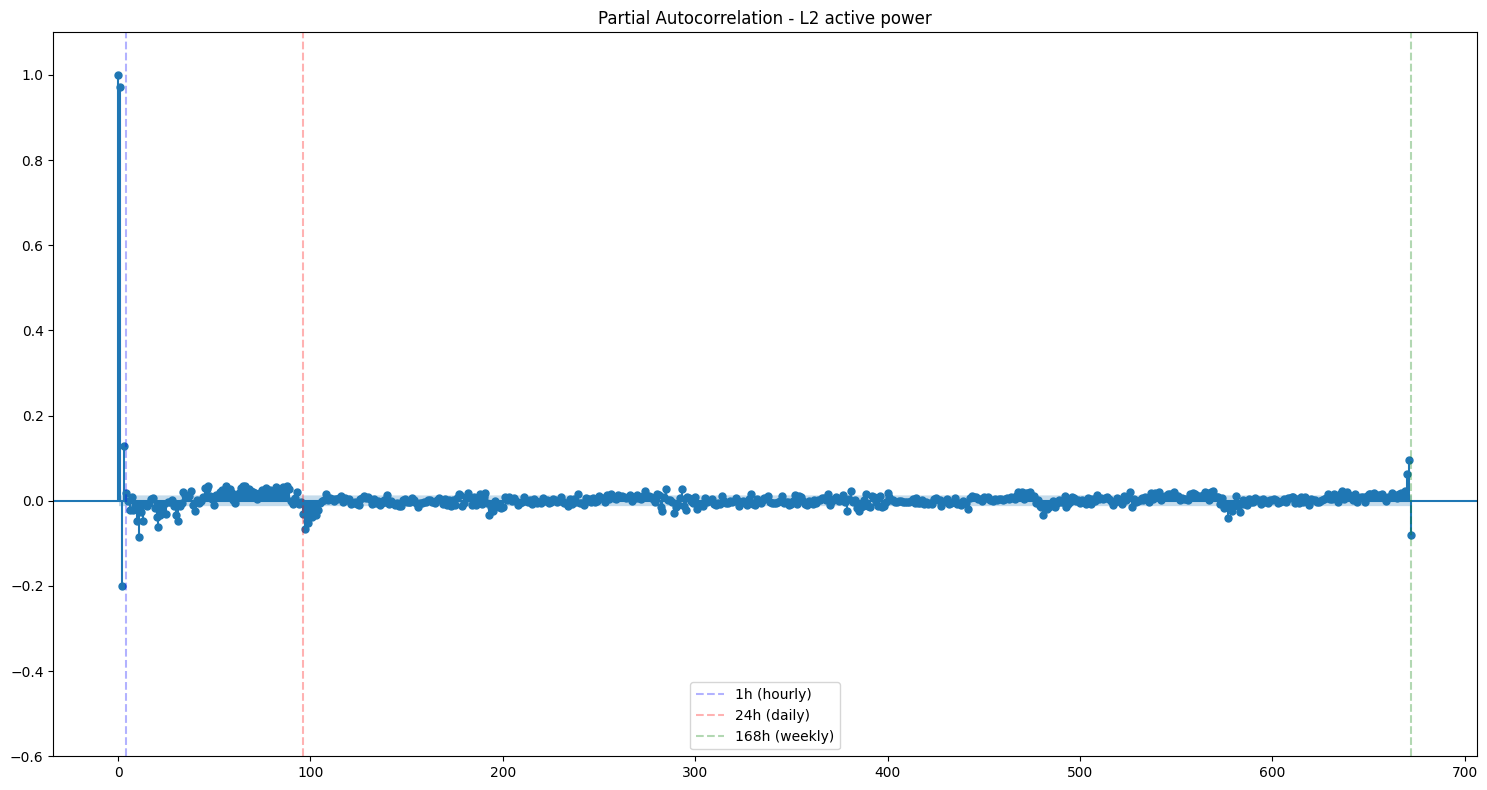

In [36]:
# L2
if 'l2_act_pow_15m_endog' in locals():
    plot_acf_pacf(l2_act_pow_15m_endog, lags=24*7*4, phase_label='L2')

<Figure size 1500x600 with 0 Axes>

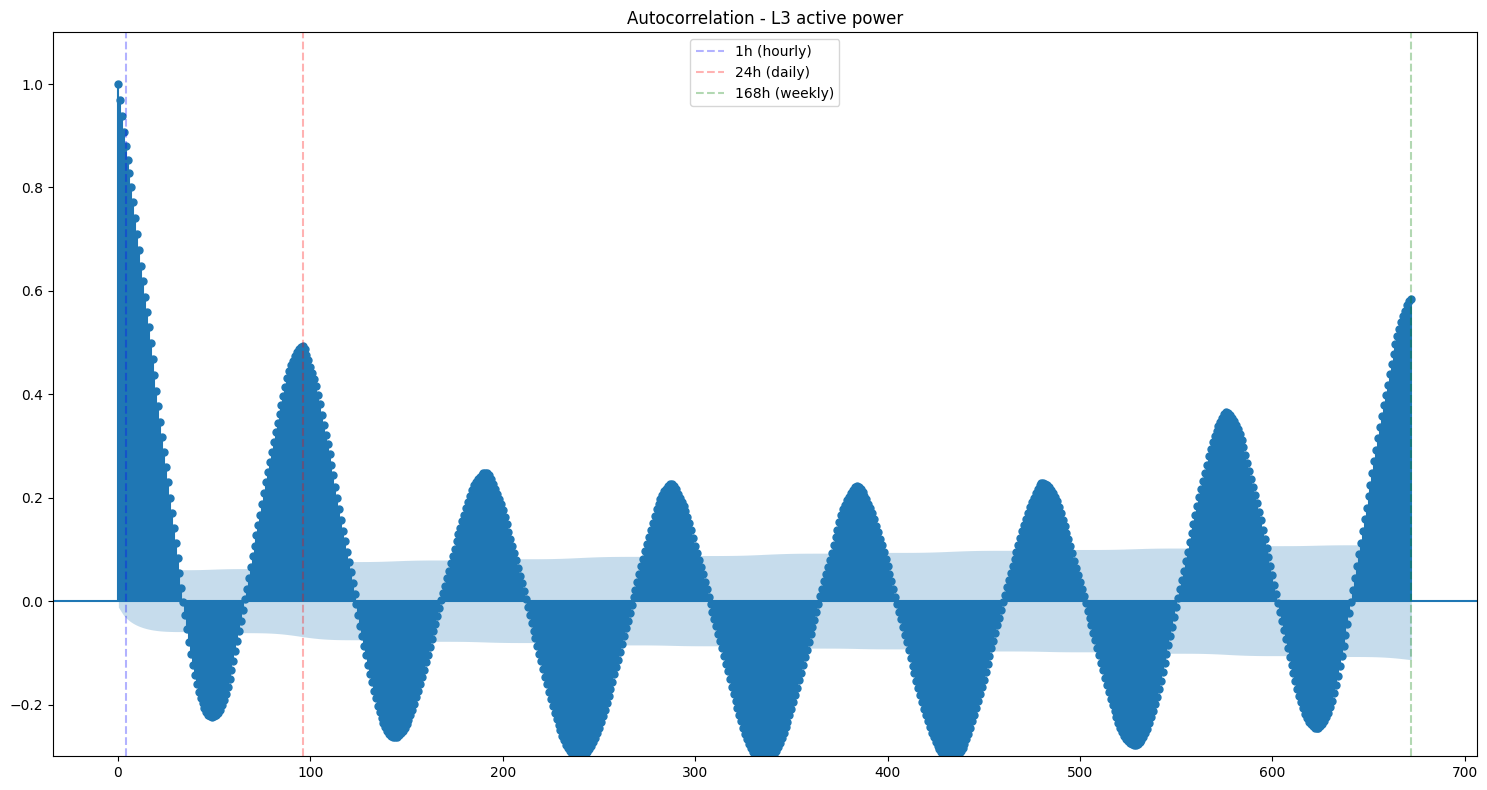

<Figure size 1500x600 with 0 Axes>

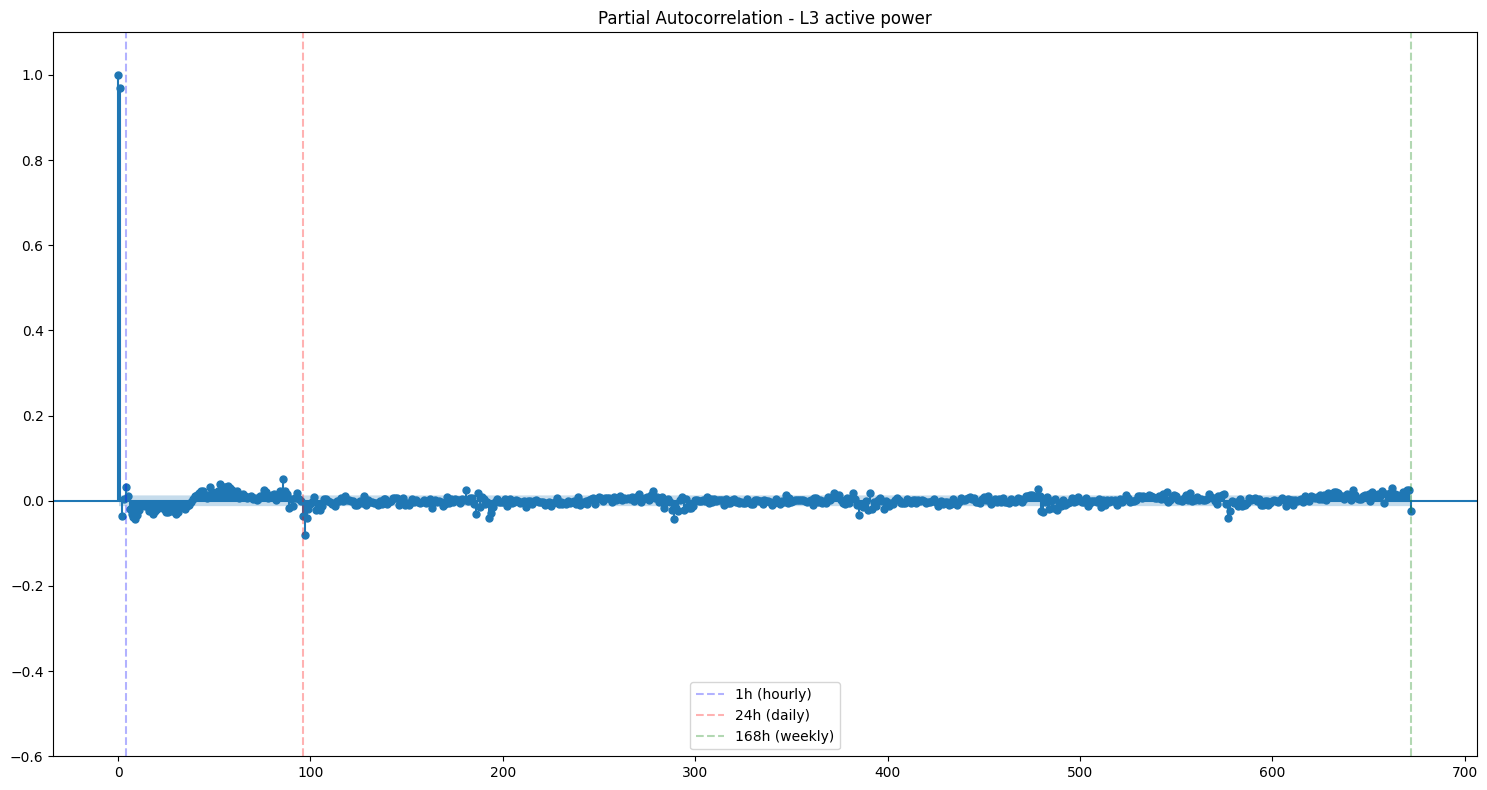

In [37]:
# L3
if 'l3_act_pow_15m_endog' in locals():
    plot_acf_pacf(l3_act_pow_15m_endog, lags=24*7*4, phase_label='L3')